## Fundamentação, fontes e decisões do protocolo

As notas metodológicas vinculam as técnicas empregadas às respectivas publicações ou documentações oficiais. As referências completas aparecem ao final deste notebook. As rotinas de leitura, persistência, verificação de integridade e organização dos resultados são implementações do projeto.

**Escolhas do estudo.** A definição de blocos temporais, as regras de elegibilidade, os sete atributos de B, os hiperparâmetros e os contextos operacionais são escolhas do projeto. Os critérios foram preservados na revisão documental, sem novo ajuste dos modelos.

**Atualização documental de 24/10/2026.** Foram acrescentadas explicações, citações e referências. As instruções executáveis e as saídas armazenadas foram preservadas. Esta revisão não corresponde a uma nova execução dos experimentos. A rastreabilidade da verificação computacional permanece nos registros de reprodução.

O [guia de fundamentação metodológica](../docs/fundamentacao_metodologica.md) relaciona as fontes, seu alcance e os controles adotados ao longo dos notebooks.


**Atualização bibliográfica de 29/10/2026.** As referências adicionais foram confrontadas com o texto integral fornecido. Elas foram incorporadas onde sustentam diretamente a motivação operacional, a avaliação temporal ou os limites de transferência. Não houve alteração de resultados nem novo treinamento nesta revisão; quando a nova literatura sugere procedimentos não executados, eles são identificados apenas como limites ou possibilidades de validação futura.


**Ampliação bibliográfica de 29/10/2026.** A busca expandida acrescentou referências diretamente pertinentes a quatro pontos do protocolo: quantidade de histórico disponível, desempenho por regime operacional, redundância entre atributos e limites de transferência/medição. A nova literatura não altera retrospectivamente as amostras, os modelos ou a conclusão principal. Foi acrescentada uma rotina de auditoria de redundância, sem remoção de atributos ou novo treinamento, para tornar explícitas relações já sugeridas pela PCA e pela definição algébrica das variáveis.


### Fontes das métricas e convenções do projeto

MAE e RMSE pertencem às medidas usuais de magnitude do erro discutidas por Hyndman e Koehler (2006). As funções de regressão da biblioteca, incluindo R², estão documentadas no guia da biblioteca (Scikit-learn, 2025). As métricas são calculadas sobre as mesmas observações usadas na comparação indicada em cada etapa. A análise dos pares é descritiva e não equivale a um teste de significância. Neste projeto, NMAE é definido explicitamente como 100 × MAE / média do alvo observado no subconjunto avaliado. Essa escolha de denominador não é atribuída a uma definição universal. O resíduo e o viés usam a convenção observado menos previsto.


In [1]:
# Referências metodológicas: (Hyndman; Koehler, 2006; Scikit-learn, 2025).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 1: CONFIGURAÇÃO E DEFINIÇÃO DO EXPERIMENTO
# NOTEBOOK 03A.05
# ============================================================
#
# TÍTULO:
# TRAJETÓRIA OPERACIONAL COM HISTÓRICO AMPLIADO
#
#
# O QUE ESTA CÉLULA FAZ?
# ------------------------------------------------------------
#
# Esta célula NÃO treina nenhum modelo e NÃO transforma dados.
#
# Ela prepara o ambiente do notebook e fixa todas as decisões
# metodológicas que serão utilizadas nas próximas células.
#
# Especificamente, esta célula:
#
# 1. importa as bibliotecas necessárias;
# 2. fixa a semente de aleatoriedade para reprodutibilidade;
# 3. conecta o Google Drive;
# 4. define os caminhos das pastas do projeto;
# 5. identifica automaticamente a unidade selecionada;
# 6. confirma que estamos trabalhando com a Iatan Unit 2;
# 7. define a variável-alvo;
# 8. define exatamente os Cenários A e B;
# 9. fixa os períodos de treino, validação e teste;
# 10. registra os hiperparâmetros estruturais do XGBoost;
# 11. cria uma função padronizada para cálculo das métricas;
# 12. apresenta um resumo do experimento.
#
#
# POR QUE ISSO É IMPORTANTE?
# ------------------------------------------------------------
#
# O objetivo do Notebook 03A.05 é fazer uma comparação controlada.
#
# Portanto, as decisões fundamentais do experimento precisam ser
# definidas ANTES de observar os novos resultados.
#
# Isso reduz o risco de alterar o experimento posteriormente em
# função do desempenho encontrado.
# ============================================================


# ============================================================
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================================
#
# Cada biblioteca possui uma função específica:
#
# Path:
#     manipulação de caminhos de arquivos e pastas.
#
# json:
#     leitura do arquivo selected_unit.json que identifica
#     automaticamente a unidade escolhida anteriormente.
#
# random e numpy:
#     controle de aleatoriedade e operações numéricas.
#
# pandas:
#     manipulação das bases de dados.
#
# matplotlib:
#     geração das figuras do experimento.
#
# sklearn.metrics:
#     cálculo das métricas de regressão.
#
# xgboost:
#     algoritmo utilizado nos experimentos anteriores e que
#     continuará sendo utilizado para manter comparabilidade.
#
# IPython.display:
#     melhora a apresentação de tabelas e textos no notebook.
# ============================================================

try:
    from google.colab import drive
except ImportError:
    drive = None

from pathlib import Path

import json
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import xgboost as xgb

from xgboost import XGBRegressor

from IPython.display import (
    display,
    Markdown
)


# ============================================================
# 2. REPRODUTIBILIDADE
# ============================================================
#
# Alguns procedimentos computacionais utilizam aleatoriedade.
#
# O XGBoost, por exemplo, pode amostrar subconjuntos das linhas
# e das variáveis durante o treinamento.
#
# Para que a execução do notebook possa ser reproduzida,
# utilizamos uma semente fixa.
#
# Isso significa que, mantendo os mesmos dados, código e versões
# das bibliotecas, as partes aleatórias do procedimento devem
# seguir a mesma sequência.
#
# A semente 42 já foi utilizada nos notebooks anteriores.
# Mantê-la também ajuda na comparabilidade entre experimentos.
# ============================================================

SEED = 42


random.seed(
    SEED
)


np.random.seed(
    SEED
)


# Ignoramos warnings não críticos para evitar que mensagens
# secundárias poluam a leitura do notebook.
#
# Erros continuam sendo exibidos normalmente.

warnings.filterwarnings(
    "ignore"
)


# Registramos a versão do XGBoost utilizada.
#
# Isso é importante porque alterações entre versões podem mudar
# parâmetros, comportamento do early stopping ou resultados.

print(
    "Versão do XGBoost:",
    xgb.__version__
)


# ============================================================
# 3. CONEXÃO COM O GOOGLE DRIVE
# ============================================================
#
# Os dados históricos, tabelas, figuras e relatórios do projeto
# estão armazenados de forma persistente no Google Drive.
#
# O comando abaixo monta o Drive no ambiente temporário do Colab.
#
# Depois disso, os arquivos podem ser acessados através de:
#
# /content/drive/MyDrive/
# ============================================================

# CO2_PROJECT_ROOT permite execução local sem montar o Google Drive.


# ============================================================
# 4. DEFINIÇÃO DA PASTA PRINCIPAL DO PROJETO
# ============================================================
#
# ROOT representa a raiz do projeto.
#
# Todas as outras pastas serão construídas a partir dela.
#
# Isso evita espalhar caminhos absolutos pelo código.
#
# Se algum dia a estrutura do projeto mudar, basta alterar ROOT
# em vez de modificar dezenas de caminhos individualmente.
# ============================================================

project_root_override = os.environ.get("CO2_PROJECT_ROOT")

if project_root_override:
    ROOT = Path(project_root_override).expanduser().resolve()
elif drive is not None:
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/co2-cems-thermal-modeling")
else:
    raise RuntimeError(
        "Fora do Google Colab, defina CO2_PROJECT_ROOT com a raiz do projeto."
    )


# ============================================================
# 5. DEFINIÇÃO DAS PASTAS DE DADOS
# ============================================================
#
# Seguimos a estrutura já utilizada no projeto:
#
# data/raw
#     dados mais próximos da fonte original.
#
# data/interim
#     bases intermediárias geradas durante o processamento.
#
# data/processed
#     bases finais preparadas para análise/modelagem.
# ============================================================

DATA = (
    ROOT
    /
    "data"
)


DATA_RAW = (
    DATA
    /
    "raw"
)


DATA_INTERIM = (
    DATA
    /
    "interim"
)


DATA_PROCESSED = (
    DATA
    /
    "processed"
)


# ============================================================
# 6. DEFINIÇÃO DAS PASTAS DE SAÍDA
# ============================================================
#
# Os resultados produzidos pelo notebook serão organizados em:
#
# outputs/reports
#     relatórios metodológicos e conclusões.
#
# outputs/figures
#     gráficos e diagnósticos visuais.
#
# outputs/tables
#     métricas, comparações e auditorias em CSV.
#
# outputs/models
#     espaço reservado para modelos, caso seja necessário
#     persistir algum objeto posteriormente.
# ============================================================

OUTPUT = (
    ROOT
    /
    "outputs"
)


REPORTS = (
    OUTPUT
    /
    "reports"
)


FIGURES = (
    OUTPUT
    /
    "figures"
)


TABLES = (
    OUTPUT
    /
    "tables"
)


MODELS = (
    OUTPUT
    /
    "models"
)


# ============================================================
# 7. PASTA DA PIPELINE
# ============================================================
#
# A pasta pipeline contém arquivos utilizados para transmitir
# decisões entre diferentes notebooks.
#
# Um deles é selected_unit.json, criado anteriormente para
# registrar qual unidade foi selecionada para o estudo.
# ============================================================

PIPELINE_DIR = (
    ROOT
    /
    "pipeline"
)


# ============================================================
# 8. DIRETÓRIO HISTÓRICO CRIADO NO NOTEBOOK 03A.04
# ============================================================
#
# O Notebook 03A.04 já realizou:
#
# - obtenção do histórico multianual;
# - organização dos dados;
# - auditoria dos anos;
# - delimitação do período histórico principal.
#
# Portanto, NÃO vamos baixar tudo novamente.
#
# Vamos reutilizar os arquivos históricos já produzidos.
#
# Isso é importante porque queremos que o 03A.05 seja uma
# continuação direta do experimento anterior.
# ============================================================

MULTIYEAR_DIR = (
    DATA_INTERIM
    /
    "03A04_multiyear"
)


# ============================================================
# 9. DIRETÓRIO ESPECÍFICO DO NOTEBOOK 03A.05
# ============================================================
#
# Algumas bases intermediárias serão específicas deste notebook,
# principalmente as bases contendo as features de trajetória
# reconstruídas para o histórico ampliado.
#
# Para não misturá-las com os arquivos do 03A.04, criamos uma
# pasta própria.
# ============================================================

EXPERIMENT_DIR = (
    DATA_INTERIM
    /
    "03A05_trajectory_history"
)


# ============================================================
# 10. CRIAÇÃO DAS PASTAS, CASO NÃO EXISTAM
# ============================================================
#
# mkdir cria cada diretório.
#
# parents=True:
#     cria também diretórios superiores caso sejam necessários.
#
# exist_ok=True:
#     não gera erro se a pasta já existir.
#
# Isso permite executar novamente a célula sem problemas.
# ============================================================

for folder in [

    REPORTS,
    FIGURES,
    TABLES,
    MODELS,
    EXPERIMENT_DIR

]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 11. LEITURA DA UNIDADE SELECIONADA
# ============================================================
#
# Em vez de escrever manualmente no código:
#
#     Facility = Iatan
#     Facility ID = 6065
#     Unit = 2
#
# recuperamos essas informações do arquivo selected_unit.json.
#
# Essa abordagem reduz a duplicação de informações e mantém a
# sequência de notebooks conectada.
# ============================================================

CONFIG_PATH = (
    PIPELINE_DIR
    /
    "selected_unit.json"
)


# Antes de tentar abrir o arquivo, verificamos se ele existe.
#
# Caso não exista, interrompemos a execução imediatamente,
# porque não seria seguro continuar sem saber qual unidade está
# configurada no projeto.

if not CONFIG_PATH.exists():

    raise FileNotFoundError(
        "selected_unit.json não encontrado."
    )


# Abrimos o JSON e transformamos seu conteúdo em um dicionário
# Python chamado selected_unit.

with open(
    CONFIG_PATH,
    "r",
    encoding="utf-8"
) as f:

    selected_unit = json.load(
        f
    )


# ============================================================
# 12. EXTRAÇÃO DAS INFORMAÇÕES DA UNIDADE
# ============================================================
#
# Cada variável abaixo recupera um campo do arquivo JSON.
#
# str() e int() garantem tipos consistentes para comparações
# posteriores.
# ============================================================

FACILITY_ID = str(
    selected_unit[
        "facility_id"
    ]
)


UNIT_ID = str(
    selected_unit[
        "unit_id"
    ]
)


FACILITY_NAME = str(
    selected_unit[
        "facility_name"
    ]
)


STATE = str(
    selected_unit[
        "state"
    ]
).upper()


REFERENCE_YEAR = int(
    selected_unit[
        "year"
    ]
)


# ============================================================
# 13. SANITY CHECK DA UNIDADE
# ============================================================
#
# Este notebook foi desenhado especificamente para a:
#
#     Iatan Unit 2
#     Facility ID 6065
#
# Se selected_unit.json apontar para outra unidade, interrompemos
# a execução.
#
# Isso evita um erro silencioso potencialmente grave, como rodar
# toda a análise histórica para outra termelétrica sem perceber.
# ============================================================

if not (

    FACILITY_ID == "6065"

    and

    UNIT_ID == "2"

):

    raise ValueError(

        "O Notebook 03A.05 foi planejado para "
        "Iatan Unit 2, mas selected_unit.json "
        "aponta para outra unidade."

    )


# ============================================================
# 14. DEFINIÇÃO DA VARIÁVEL-ALVO
# ============================================================
#
# O objetivo continua sendo prever a massa horária de CO2.
#
# Utilizamos exatamente a mesma variável-alvo dos experimentos
# anteriores para preservar comparabilidade.
#
# Unidade:
#
#     short tons de CO2 por hora registrada
# ============================================================

TARGET = (
    "CO2 Mass (short tons)"
)


# ============================================================
# 15. DEFINIÇÃO DO CENÁRIO A
# ============================================================
#
# O Cenário A representa o modelo mais simples.
#
# Ele tenta prever a emissão horária utilizando apenas a carga
# elétrica instantânea da unidade:
#
#     CO2(t) = f(P(t))
#
# Ou seja:
#
# para prever CO2 na hora t, o modelo conhece apenas a carga
# da própria hora t.
#
# Este cenário funciona como baseline estrutural para medir se
# informações adicionais de trajetória realmente acrescentam
# capacidade preditiva.
# ============================================================

FEATURES_A = [

    "load_current_mw"

]


# ============================================================
# 16. DEFINIÇÃO DO CENÁRIO B
# ============================================================
#
# O Cenário B adiciona informações sobre a trajetória recente
# da unidade.
#
# IMPORTANTE:
#
# Estas são EXATAMENTE as 7 features do Cenário B utilizado
# no Notebook 03A.03.
#
# Não estamos criando novas variáveis nesta etapa.
#
# Isso é fundamental para a pergunta científica do 03A.05:
#
# se o desempenho do Cenário B mudar, queremos investigar o
# efeito do HISTÓRICO AMPLIADO, e não o efeito de uma nova
# engenharia de atributos.
#
#
# Significado das features:
#
# load_current_mw
#     carga elétrica da hora atual.
#
# load_lag_1h
#     carga registrada uma hora antes.
#
# delta_load_1h
#     diferença entre carga atual e carga da hora anterior.
#     Representa a direção e intensidade da rampa.
#
# abs_delta_load_1h
#     valor absoluto da variação de carga.
#     Representa apenas a intensidade da mudança, sem considerar
#     se a carga aumentou ou diminuiu.
#
# load_mean_previous_3h
#     média da carga nas três horas anteriores.
#     Representa o nível operacional recente.
#
# operating_time_lag_1h
#     Operating Time registrado na hora anterior.
#     Ajuda a representar continuidade de operação.
#
# hours_since_startup
#     quantidade de horas transcorridas desde o último startup.
#     Representa a posição temporal dentro do ciclo operacional.
# ============================================================

FEATURES_B = [

    "load_current_mw",

    "load_lag_1h",

    "delta_load_1h",

    "abs_delta_load_1h",

    "load_mean_previous_3h",

    "operating_time_lag_1h",

    "hours_since_startup"

]


# ============================================================
# 17. DELIMITAÇÃO DO HISTÓRICO DE REFERÊNCIA
# ============================================================
#
# O Notebook 03A.04 mostrou que nem todos os anos devem ser
# tratados automaticamente como parte de um único regime.
#
# O período principal de referência ficou definido como:
#
#     2011 a 2022
#
# Essa decisão foi tomada ANTES do experimento atual.
# ============================================================

REFERENCE_START_YEAR = 2011

REFERENCE_END_YEAR = 2022


# ============================================================
# 18. ANOS EXCLUÍDOS DA AMOSTRA PRINCIPAL
# ============================================================
#
# 2010:
#
#     ano parcial associado ao commissioning e à entrada em
#     operação comercial da Iatan Unit 2.
#
# 2023 e 2024:
#
#     apresentaram comportamento operacional fora das faixas
#     empíricas observadas em 2011 a 2022 em diversos
#     indicadores.
#
# Esses anos NÃO são considerados "ruins" ou inválidos.
#
# Eles apenas representam um período operacional distinto e,
# por isso, não serão misturados ao histórico principal neste
# experimento controlado.
# ============================================================

EXCLUDED_YEARS = [

    2010,
    2023,
    2024

]


# ============================================================
# 19. ANO-ALVO
# ============================================================
#
# 2025 continuará sendo o período recente utilizado para:
#
# - complementar o treinamento;
# - selecionar a complexidade;
# - realizar o teste temporal final.
# ============================================================

TARGET_YEAR = 2025


# ============================================================
# 20. DEFINIÇÃO DOS INTERVALOS TEMPORAIS DE 2025
# ============================================================
#
# Mantemos a mesma lógica temporal utilizada no experimento
# pareado do Notebook 03A.04.
#
#
# TREINO RECENTE:
#
#     janeiro a setembro de 2025
#
#
# VALIDAÇÃO:
#
#     outubro de 2025
#
#
# TESTE:
#
#     novembro e dezembro de 2025
#
#
# A ordem temporal é preservada.
#
# Não utilizamos divisão aleatória porque isso permitiria que
# informações do futuro aparecessem no treinamento.
# ============================================================

TRAIN_RECENT_END = pd.Timestamp(
    "2025-09-30 23:59:59"
)


VALIDATION_START = pd.Timestamp(
    "2025-10-01 00:00:00"
)


VALIDATION_END = pd.Timestamp(
    "2025-10-31 23:59:59"
)


TEST_START = pd.Timestamp(
    "2025-11-01 00:00:00"
)


TEST_END = pd.Timestamp(
    "2025-12-31 23:59:59"
)


# ============================================================
# 21. HIPERPARÂMETROS ESTRUTURAIS DO XGBOOST
# ============================================================
#
# Utilizamos a mesma configuração estrutural de referência
# adotada no Notebook 03A.04.
#
# Isso mantém o foco do novo experimento sobre as FEATURES.
#
#
# n_estimators = 3000
#
#     É o limite máximo de árvores.
#
#     Não significa que o modelo necessariamente utilizará
#     3000 árvores.
#
#
# early_stopping_rounds = 50
#
#     Durante a validação, o treinamento será interrompido se
#     não houver melhora do RMSE por 50 iterações consecutivas.
#
#
# learning_rate = 0.03
#
#     Controla o tamanho da contribuição de cada nova árvore.
#
#
# max_depth = 4
#
#     Limita a profundidade das árvores e, consequentemente,
#     sua complexidade individual.
#
#
# min_child_weight = 5
#
#     Impõe uma restrição para criação de novos ramos,
#     ajudando a controlar sobreajuste.
#
#
# subsample = 0.80
#
#     Cada árvore utiliza 80% das observações disponíveis.
#
#
# colsample_bytree = 0.80
#
#     Cada árvore pode utilizar uma amostra de 80% das features.
#
#
# reg_alpha e reg_lambda
#
#     controlam regularização L1 e L2.
#
#
# IMPORTANTE:
#
# Cenário A e Cenário B utilizarão o MESMO protocolo.
#
# Entretanto, cada cenário poderá selecionar seu próprio número
# de árvores através do early stopping.
#
# Isso é adequado porque A e B possuem complexidades de entrada
# diferentes.
# ============================================================

XGB_PARAMS_SELECTION = {

    "objective":
        "reg:squarederror",

    "n_estimators":
        3000,

    "learning_rate":
        0.03,

    "max_depth":
        4,

    "min_child_weight":
        5,

    "subsample":
        0.80,

    "colsample_bytree":
        0.80,

    "reg_alpha":
        0.0,

    "reg_lambda":
        1.0,

    "eval_metric":
        "rmse",

    "early_stopping_rounds":
        50,

    "random_state":
        SEED,

    "n_jobs":
        -1

}


# ============================================================
# 22. FUNÇÃO PADRONIZADA DE MÉTRICAS
# ============================================================
#
# Criamos uma única função para calcular todas as métricas.
#
# Isso evita repetir fórmulas em diferentes partes do notebook
# e reduz o risco de calcular uma métrica de maneiras diferentes
# para A e B.
#
#
# MAE
#
#     erro absoluto médio.
#
#     Indica, em média, quantas short tons de CO2 separam a
#     previsão do valor observado.
#
#
# MedianAE
#
#     mediana do erro absoluto.
#
#     É menos influenciada por erros extremos do que o MAE.
#
#
# RMSE
#
#     raiz do erro quadrático médio.
#
#     Penaliza erros grandes de forma mais intensa.
#
#
# R2
#
#     coeficiente de determinação.
#
#     Mede quanto da variabilidade do target é explicada pelo
#     modelo.
#
#
# NMAE
#
#     MAE normalizado pela média observada de CO2.
#
#     Facilita interpretar o erro em escala relativa.
#
#
# Bias
#
#     definido neste projeto como:
#
#         observado - previsto
#
#     Bias positivo:
#         tendência média de subestimação.
#
#     Bias negativo:
#         tendência média de superestimação.
# ============================================================

def regression_metrics(
    y_true,
    y_pred
):

    # Convertemos os vetores para arrays NumPy.
    #
    # Isso garante comportamento consistente mesmo se os dados
    # chegarem à função como Series do pandas.

    y_true = np.asarray(
        y_true,
        dtype=float
    )


    y_pred = np.asarray(
        y_pred,
        dtype=float
    )


    # --------------------------------------------------------
    # MAE
    # --------------------------------------------------------

    mae = mean_absolute_error(
        y_true,
        y_pred
    )


    # --------------------------------------------------------
    # RMSE
    # --------------------------------------------------------
    #
    # sklearn retorna primeiro o MSE.
    #
    # Aplicamos a raiz quadrada para obter o RMSE na mesma
    # unidade física do target.

    rmse = np.sqrt(

        mean_squared_error(
            y_true,
            y_pred
        )

    )


    # --------------------------------------------------------
    # R²
    # --------------------------------------------------------

    r2 = r2_score(
        y_true,
        y_pred
    )


    # --------------------------------------------------------
    # MÉDIA OBSERVADA
    # --------------------------------------------------------
    #
    # Necessária para normalizar o MAE.

    mean_observed = np.mean(
        y_true
    )


    # --------------------------------------------------------
    # NMAE
    # --------------------------------------------------------
    #
    # Multiplicamos por 100 para expressar o resultado em %.
    #
    # A condição evita divisão por zero.

    nmae = (

        100
        *
        mae
        /
        mean_observed

        if mean_observed != 0

        else np.nan

    )


    # --------------------------------------------------------
    # BIAS
    # --------------------------------------------------------
    #
    # Atenção à convenção:
    #
    #     observado - previsto
    #
    # Mantemos exatamente a convenção utilizada nos notebooks
    # anteriores.

    bias = np.mean(

        y_true
        -
        y_pred

    )


    # --------------------------------------------------------
    # MEDIANA DO ERRO ABSOLUTO
    # --------------------------------------------------------

    median_ae = np.median(

        np.abs(
            y_true
            -
            y_pred
        )

    )


    # Retornamos tudo em um dicionário.
    #
    # Isso facilita posteriormente transformar os resultados
    # em DataFrame e salvar em CSV.

    return {

        "MAE":
            mae,

        "MedianAE":
            median_ae,

        "RMSE":
            rmse,

        "R2":
            r2,

        "NMAE_pct":
            nmae,

        "Bias":
            bias

    }


# ============================================================
# 23. CONSTRUÇÃO DE UMA TABELA DOS CENÁRIOS
# ============================================================
#
# Esta tabela não participa do treinamento.
#
# Ela serve para documentar claramente a diferença entre A e B.
#
# É especialmente útil para conferência visual no notebook.
# ============================================================

scenario_summary = pd.DataFrame({

    "cenario": [

        "A",

        "B"

    ],

    "representacao": [

        "Carga instantânea",

        "Carga + trajetória operacional"

    ],

    "n_features": [

        len(
            FEATURES_A
        ),

        len(
            FEATURES_B
        )

    ],

    "features": [

        ", ".join(
            FEATURES_A
        ),

        ", ".join(
            FEATURES_B
        )

    ]

})


# ============================================================
# 24. EXIBIÇÃO DO RESUMO DO EXPERIMENTO
# ============================================================
#
# Antes de seguir para qualquer transformação de dados,
# imprimimos as principais decisões.
#
# Isso funciona como uma auditoria inicial.
#
# Se alguma informação estiver errada, devemos corrigir AGORA,
# antes de avançar para o processamento.
# ============================================================

print("=" * 72)

print(
    "NOTEBOOK 03A.05"
)

print(
    "TRAJETÓRIA OPERACIONAL COM HISTÓRICO AMPLIADO"
)

print("=" * 72)


print(
    "\nUnidade analisada:"
)


print(
    f"{FACILITY_NAME} | Unit {UNIT_ID}"
)


print(
    "Facility ID:",
    FACILITY_ID
)


print(
    "Estado:",
    STATE
)


print(
    "\nHistórico principal:"
)


print(
    f"{REFERENCE_START_YEAR} a {REFERENCE_END_YEAR}"
)


print(
    "\nAnos deliberadamente fora do histórico principal:"
)


print(
    EXCLUDED_YEARS
)


print(
    "\nAno recente utilizado:"
)


print(
    TARGET_YEAR
)


print(
    "\nValidação:"
)


print(
    "Outubro de 2025"
)


print(
    "\nTeste:"
)


print(
    "Novembro e dezembro de 2025"
)


print(
    "\nCenários que serão comparados:"
)


display(
    scenario_summary
)


print(
    "\nPergunta experimental:"
)


print(

    "Com histórico ampliado, a inclusão de variáveis de "
    "trajetória operacional melhora a previsão de CO2 em "
    "relação ao uso exclusivo da carga instantânea?"

)


print(
    "\nBase histórica reutilizada:"
)


print(
    MULTIYEAR_DIR
)


print(
    "\nPasta específica do novo experimento:"
)


print(
    EXPERIMENT_DIR
)


# ============================================================
# 25. MENSAGEM FINAL DA CÉLULA
# ============================================================
#
# Se chegarmos até aqui sem erro, sabemos que:
#
# - o Drive foi montado;
# - a estrutura de pastas foi localizada;
# - a unidade correta foi identificada;
# - A e B estão formalmente definidos;
# - os períodos temporais estão fixados;
# - as métricas estão padronizadas;
# - o protocolo do experimento está registrado.
#
# A próxima célula poderá então começar a trabalhar com os
# dados históricos.
# ============================================================

print(
    "\nConfiguração concluída com sucesso."
)


print(
    "Próxima etapa: localizar, carregar e auditar "
    "as bases multianuais antes da criação das "
    "features de trajetória."
)

Versão do XGBoost: 3.4.1
Mounted at /content/drive
NOTEBOOK 03A.05
TRAJETÓRIA OPERACIONAL COM HISTÓRICO AMPLIADO

Unidade analisada:
Iatan | Unit 2
Facility ID: 6065
Estado: MO

Histórico principal:
2011 a 2022

Anos deliberadamente fora do histórico principal:
[2010, 2023, 2024]

Ano recente utilizado:
2025

Validação:
Outubro de 2025

Teste:
Novembro e dezembro de 2025

Cenários que serão comparados:


,cenario,representacao,n_features,features
0,A,Carga instantânea,1,load_current_mw
1,B,Carga + trajetória operacional,7,"load_current_mw, load_lag_1h, delta_load_1h, a..."



Pergunta experimental:
Com histórico ampliado, a inclusão de variáveis de trajetória operacional melhora a previsão de CO2 em relação ao uso exclusivo da carga instantânea?

Base histórica reutilizada:
/content/drive/MyDrive/co2-cems-thermal-modeling/data/interim/03A04_multiyear

Pasta específica do novo experimento:
/content/drive/MyDrive/co2-cems-thermal-modeling/data/interim/03A05_trajectory_history

Configuração concluída com sucesso.
Próxima etapa: localizar, carregar e auditar as bases multianuais antes da criação das features de trajetória.


In [2]:
# ============================================================
# CÉLULA 2: CARREGAMENTO E AUDITORIA DAS BASES MULTIANUAIS
# ============================================================
#
# O QUE ESTA CÉLULA FAZ?
# ------------------------------------------------------------
#
# Esta célula prepara a matéria-prima temporal que será usada
# para reconstruir as features do Cenário B.
#
# Ela ainda NÃO calcula:
#
#     load_lag_1h
#     delta_load_1h
#     abs_delta_load_1h
#     load_mean_previous_3h
#     operating_time_lag_1h
#     hours_since_startup
#
#
# Antes de calcular qualquer informação de trajetória, precisamos
# saber se a série que alimentará esses cálculos está correta.
#
#
# A célula executará as seguintes etapas:
#
# 1. definir quais anos serão utilizados;
# 2. localizar os arquivos anuais produzidos no Notebook 03A.04;
# 3. verificar se todos os arquivos necessários existem;
# 4. carregar cada ano separadamente;
# 5. conferir as colunas obrigatórias;
# 6. padronizar timestamp e variáveis numéricas;
# 7. conferir Facility ID e Unit ID;
# 8. procurar timestamps duplicados;
# 9. procurar lacunas na sequência horária;
# 10. conferir dados ausentes durante a operação;
# 11. consolidar 2011 a 2022;
# 12. manter 2025 como um bloco temporal separado;
# 13. identificar automaticamente descontinuidades temporais;
# 14. gerar uma tabela de auditoria;
# 15. salvar essa auditoria em outputs/tables.
#
#
# POR QUE NÃO CALCULAMOS OS LAGS AINDA?
# ------------------------------------------------------------
#
# Uma operação como:
#
#     df["load_current_mw"].shift(1)
#
# simplesmente utiliza a linha anterior do DataFrame.
#
# Ela NÃO sabe se a linha anterior representa realmente a hora
# imediatamente anterior.
#
# Isso poderia produzir, por exemplo:
#
#     31/12/2022 23:00
#
# como "hora anterior" de:
#
#     01/01/2025 00:00
#
# caso os dados fossem apenas concatenados e um shift fosse
# aplicado diretamente.
#
# Esse seria um lag falso, pois existe uma lacuna de dois anos.
#
#
# SOLUÇÃO
# ------------------------------------------------------------
#
# Nesta célula criaremos uma variável chamada:
#
#     temporal_block
#
# Um novo bloco será iniciado sempre que a diferença entre dois
# timestamps consecutivos deixar de ser exatamente 1 hora.
#
#
# Assim:
#
# 2011 -> 2012
#
# pode permanecer no mesmo bloco se houver continuidade horária.
#
#
# 2022 -> 2025
#
# obrigatoriamente formará um novo bloco.
#
#
# Posteriormente, todas as features temporais serão calculadas
# DENTRO desses blocos.
# ============================================================


# ============================================================
# 1. DEFINIR OS ANOS QUE PARTICIPAM DO EXPERIMENTO
# ============================================================
#
# O histórico de referência foi definido no Notebook 03A.04:
#
#     2011 a 2022
#
# Acrescentamos 2025 porque ele contém:
#
#     janeiro a setembro:
#         dados recentes de treinamento;
#
#     outubro:
#         validação;
#
#     novembro e dezembro:
#         teste.
#
#
# IMPORTANTE:
#
# 2010 não entra porque representa período parcial associado
# à entrada em operação da unidade.
#
# 2023 e 2024 não entram porque foram previamente identificados
# como período operacional distinto.
# ============================================================

REFERENCE_YEARS = list(

    range(
        REFERENCE_START_YEAR,
        REFERENCE_END_YEAR + 1
    )

)


YEARS_TO_LOAD = (

    REFERENCE_YEARS

    +

    [
        TARGET_YEAR
    ]

)


print(
    "Anos que serão carregados:"
)


print(
    YEARS_TO_LOAD
)


# ============================================================
# 2. COLUNAS OBRIGATÓRIAS DOS ARQUIVOS HISTÓRICOS
# ============================================================
#
# Os arquivos anuais foram produzidos no Notebook 03A.04.
#
# Esperamos encontrar pelo menos:
#
# Facility ID
#     identifica a instalação.
#
# Unit ID
#     identifica a unidade geradora.
#
# Date
#     data do registro.
#
# Hour
#     hora do registro.
#
# timestamp
#     data e hora combinadas.
#
# Operating Time
#     informação de operação reportada pela EPA.
#
# Gross Load (MW)
#     carga elétrica bruta da unidade.
#
# CO2 Mass (short tons)
#     variável-alvo.
#
#
# source_year
#     ano de origem do arquivo.
#
#
# Nenhuma dessas variáveis é criada silenciosamente, exceto
# timestamp e source_year, que podem ser reconstruídos de forma
# determinística caso necessário.
# ============================================================

RAW_REQUIRED_COLUMNS = [

    "Facility ID",
    "Unit ID",
    "Date",
    "Hour",
    "Operating Time",
    "Gross Load (MW)",
    "CO2 Mass (short tons)"

]


# ============================================================
# 3. CONSTRUIR O CATÁLOGO DOS ARQUIVOS ESPERADOS
# ============================================================
#
# No Notebook 03A.04 cada ano foi salvo com o padrão:
#
#     iatan_unit2_YYYY.parquet
#
# Por exemplo:
#
#     iatan_unit2_2011.parquet
#
#     iatan_unit2_2022.parquet
#
#     iatan_unit2_2025.parquet
#
#
# Construímos os caminhos automaticamente para evitar escrever
# manualmente treze nomes de arquivos.
# ============================================================

annual_file_catalog = pd.DataFrame({

    "year":
        YEARS_TO_LOAD

})


annual_file_catalog[
    "file_name"
] = annual_file_catalog[
    "year"
].apply(

    lambda year:

        f"iatan_unit2_{year}.parquet"

)


annual_file_catalog[
    "path"
] = annual_file_catalog[
    "file_name"
].apply(

    lambda file_name:

        MULTIYEAR_DIR
        /
        file_name

)


# ============================================================
# 4. VERIFICAR SE OS ARQUIVOS EXISTEM
# ============================================================
#
# Path.exists() devolve:
#
#     True
#         arquivo encontrado;
#
#     False
#         arquivo ausente.
#
#
# Não queremos descobrir no meio do processamento que algum ano
# está faltando.
#
# Portanto, esta checagem ocorre antes da leitura dos dados.
# ============================================================

annual_file_catalog[
    "exists"
] = annual_file_catalog[
    "path"
].apply(

    lambda path:

        path.exists()

)


# Também registramos o tamanho de cada arquivo.
#
# Essa informação não participa da modelagem, mas ajuda a
# identificar arquivos inesperadamente vazios ou anômalos.

annual_file_catalog[
    "size_kb"
] = annual_file_catalog.apply(

    lambda row:

        (
            row["path"].stat().st_size
            /
            1024
        )

        if row["exists"]

        else np.nan,

    axis=1

)


print("\n" + "=" * 72)

print(
    "CATÁLOGO DOS ARQUIVOS ANUAIS"
)

print("=" * 72)


display(

    annual_file_catalog[
        [
            "year",
            "file_name",
            "exists",
            "size_kb"
        ]
    ]

    .round(
        2
    )

)


# ============================================================
# 5. INTERROMPER SE ALGUM ANO ESTIVER AUSENTE
# ============================================================
#
# Uma série incompleta poderia alterar a construção das
# trajetórias.
#
# Por isso, não continuamos automaticamente caso algum arquivo
# esperado esteja faltando.
# ============================================================

missing_files = (

    annual_file_catalog.loc[

        ~annual_file_catalog[
            "exists"
        ],

        "file_name"

    ]

    .tolist()

)


if missing_files:

    raise FileNotFoundError(

        "Arquivos históricos ausentes: "
        +
        ", ".join(
            missing_files
        )

    )


print(
    "\nTodos os arquivos necessários foram encontrados."
)


# ============================================================
# 6. ESTRUTURAS PARA ARMAZENAR OS RESULTADOS
# ============================================================
#
# annual_data:
#
#     dicionário contendo o DataFrame completo de cada ano.
#
#     Exemplo:
#
#         annual_data[2011]
#
#         annual_data[2025]
#
#
# audit_rows:
#
#     lista que receberá uma linha de auditoria para cada ano.
#
#     Ao final, essa lista será transformada em DataFrame.
# ============================================================

annual_data = {}


audit_rows = []


# ============================================================
# 7. CARREGAR E AUDITAR CADA ANO
# ============================================================
#
# A leitura é feita ano a ano deliberadamente.
#
# Isso permite identificar um problema específico em 2015,
# 2018 ou qualquer outro ano sem mascará-lo dentro de uma base
# consolidada de mais de 100 mil linhas.
# ============================================================

for year in YEARS_TO_LOAD:


    print("\n" + "=" * 72)

    print(
        f"AUDITORIA DO ANO {year}"
    )

    print("=" * 72)


    # --------------------------------------------------------
    # 7.1. LOCALIZAR O ARQUIVO DO ANO
    # --------------------------------------------------------

    file_path = (

        MULTIYEAR_DIR
        /
        f"iatan_unit2_{year}.parquet"

    )


    print(
        "Arquivo:"
    )


    print(
        file_path
    )


    # --------------------------------------------------------
    # 7.2. LER O PARQUET
    # --------------------------------------------------------
    #
    # pd.read_parquet preserva tipos e é muito mais eficiente
    # do que CSV para esse tipo de base.
    # --------------------------------------------------------

    df_year = pd.read_parquet(
        file_path
    )


    # Trabalhamos sobre uma cópia independente.
    #
    # Isso evita modificar acidentalmente uma referência
    # compartilhada de outro objeto.

    df_year = df_year.copy()


    print(
        "\nRegistros carregados:",
        f"{len(df_year):,}"
    )


    # --------------------------------------------------------
    # 7.3. CONFERIR COLUNAS OBRIGATÓRIAS
    # --------------------------------------------------------
    #
    # Procuramos as colunas definidas no início da célula.
    #
    # Se uma delas estiver ausente, interrompemos imediatamente,
    # pois não seria possível reconstruir o Cenário B de maneira
    # consistente.
    # --------------------------------------------------------

    missing_columns = [

        column

        for column in RAW_REQUIRED_COLUMNS

        if column not in df_year.columns

    ]


    if missing_columns:

        raise ValueError(

            f"Ano {year}: colunas obrigatórias ausentes: "
            +
            ", ".join(
                missing_columns
            )

        )


    # --------------------------------------------------------
    # 7.4. NORMALIZAR DATE
    # --------------------------------------------------------
    #
    # errors="coerce":
    #
    # qualquer valor impossível de interpretar como data será
    # convertido em NaT.
    #
    # Isso é preferível a manter uma string inválida escondida
    # na série.
    # --------------------------------------------------------

    df_year[
        "Date"
    ] = pd.to_datetime(

        df_year[
            "Date"
        ],

        errors="coerce"

    )


    # --------------------------------------------------------
    # 7.5. NORMALIZAR HOUR
    # --------------------------------------------------------
    #
    # A coluna Hour precisa ser numérica para que possamos
    # reconstruir o timestamp caso necessário.
    # --------------------------------------------------------

    df_year[
        "Hour"
    ] = pd.to_numeric(

        df_year[
            "Hour"
        ],

        errors="coerce"

    )


    # --------------------------------------------------------
    # 7.6. PREPARAR TIMESTAMP
    # --------------------------------------------------------
    #
    # Os arquivos do 03A.04 já devem possuir timestamp.
    #
    # Mesmo assim, fazemos a lógica abaixo de forma defensiva.
    #
    #
    # Caso timestamp exista:
    #
    #     apenas garantimos que ele seja datetime.
    #
    #
    # Caso não exista:
    #
    #     reconstruímos usando:
    #
    #         Date + Hour
    #
    #
    # Essa reconstrução não utiliza nenhuma informação futura.
    # --------------------------------------------------------

    if "timestamp" in df_year.columns:

        df_year[
            "timestamp"
        ] = pd.to_datetime(

            df_year[
                "timestamp"
            ],

            errors="coerce"

        )


    else:

        df_year[
            "timestamp"
        ] = (

            df_year[
                "Date"
            ]

            +

            pd.to_timedelta(

                df_year[
                    "Hour"
                ],

                unit="h"

            )

        )


    # --------------------------------------------------------
    # 7.7. NORMALIZAR VARIÁVEIS NUMÉRICAS
    # --------------------------------------------------------
    #
    # As três variáveis abaixo serão fundamentais para as
    # próximas etapas.
    #
    # Transformamos valores não interpretáveis em NaN para que
    # sejam detectados explicitamente na auditoria.
    # --------------------------------------------------------

    numeric_columns = [

        "Operating Time",
        "Gross Load (MW)",
        "CO2 Mass (short tons)"

    ]


    for column in numeric_columns:

        df_year[
            column
        ] = pd.to_numeric(

            df_year[
                column
            ],

            errors="coerce"

        )


    # --------------------------------------------------------
    # 7.8. DEFINIR SOURCE_YEAR
    # --------------------------------------------------------
    #
    # source_year indica de qual arquivo anual a observação veio.
    #
    # Mesmo que a coluna já exista, redefinimos usando o ano que
    # está sendo carregado.
    #
    # Dessa forma, não dependemos de metadados antigos.
    # --------------------------------------------------------

    df_year[
        "source_year"
    ] = year


    # --------------------------------------------------------
    # 7.9. ORDENAR CRONOLOGICAMENTE
    # --------------------------------------------------------
    #
    # Lags e rolling windows dependem estritamente da ordem das
    # observações.
    #
    # Portanto, antes de qualquer auditoria temporal, ordenamos
    # pelo timestamp.
    # --------------------------------------------------------

    df_year = (

        df_year

        .sort_values(
            "timestamp"
        )

        .reset_index(
            drop=True
        )

    )


    # --------------------------------------------------------
    # 7.10. VERIFICAR TIMESTAMPS INVÁLIDOS
    # --------------------------------------------------------

    invalid_timestamps = int(

        df_year[
            "timestamp"
        ]

        .isna()

        .sum()

    )


    # Um timestamp ausente impede determinar qual observação vem
    # antes ou depois.
    #
    # Portanto, tratamos isso como erro crítico.

    if invalid_timestamps > 0:

        raise ValueError(

            f"Ano {year}: "
            f"{invalid_timestamps} timestamps inválidos."

        )

    # IDs ausentes também são inválidos; não descartá-los antes da conferência.
    for id_column, expected_id in [("Facility ID", 6065), ("Unit ID", 2)]:
        ids = pd.to_numeric(df_year[id_column], errors="coerce")
        if not ids.eq(expected_id).all():
            raise ValueError(f"Ano {year}: {id_column} ausente ou inesperado.")

    timestamps_from_fields = (
        df_year["Date"] + pd.to_timedelta(df_year["Hour"], unit="h")
    )
    if timestamps_from_fields.isna().any() or not df_year["timestamp"].eq(
        timestamps_from_fields
    ).all():
        raise ValueError(f"Ano {year}: timestamp não corresponde a Date + Hour.")


    # --------------------------------------------------------
    # 7.11. VERIFICAR FACILITY ID
    # --------------------------------------------------------
    #
    # Primeiro convertemos para número.
    #
    # Isso evita diferenças meramente de representação, como:
    #
    #     6065
    #
    # e
    #
    #     6065.0
    # --------------------------------------------------------

    facility_values = (

        pd.to_numeric(

            df_year[
                "Facility ID"
            ],

            errors="coerce"

        )

        .dropna()

        .unique()

    )


    # A base deve conter somente Facility ID 6065.

    facility_ok = (

        len(
            facility_values
        )
        ==
        1

        and

        float(
            facility_values[0]
        )
        ==
        6065.0

    )


    if not facility_ok:

        raise ValueError(

            f"Ano {year}: Facility ID inesperado. "
            f"Valores encontrados: {facility_values}"

        )


    # --------------------------------------------------------
    # 7.12. VERIFICAR UNIT ID
    # --------------------------------------------------------

    unit_values = (

        pd.to_numeric(

            df_year[
                "Unit ID"
            ],

            errors="coerce"

        )

        .dropna()

        .unique()

    )


    unit_ok = (

        len(
            unit_values
        )
        ==
        1

        and

        float(
            unit_values[0]
        )
        ==
        2.0

    )


    if not unit_ok:

        raise ValueError(

            f"Ano {year}: Unit ID inesperado. "
            f"Valores encontrados: {unit_values}"

        )


    # --------------------------------------------------------
    # 7.13. VERIFICAR SE OS TIMESTAMPS PERTENCEM AO ANO
    # --------------------------------------------------------
    #
    # Um arquivo chamado iatan_unit2_2017.parquet deve conter
    # timestamps de 2017.
    #
    # Essa checagem detecta mistura acidental entre arquivos.
    # --------------------------------------------------------

    timestamp_years = (

        df_year[
            "timestamp"
        ]

        .dt.year

        .dropna()

        .unique()

    )


    timestamp_year_ok = (

        len(
            timestamp_years
        )
        ==
        1

        and

        int(
            timestamp_years[0]
        )
        ==
        year

    )


    if not timestamp_year_ok:

        raise ValueError(

            f"Ano {year}: timestamps fora do ano esperado. "
            f"Anos encontrados: {timestamp_years}"

        )


    # --------------------------------------------------------
    # 7.14. VERIFICAR DUPLICIDADES TEMPORAIS
    # --------------------------------------------------------
    #
    # Duas linhas com o mesmo timestamp poderiam produzir
    # ambiguidades na trajetória.
    #
    # Portanto, registramos quantas duplicidades existem.
    # --------------------------------------------------------

    n_duplicates = int(

        df_year[
            "timestamp"
        ]

        .duplicated()

        .sum()

    )


    # Duplicidade temporal é considerada problema estrutural.
    #
    # Interrompemos a execução para não criar trajetórias
    # ambíguas.

    if n_duplicates > 0:

        raise ValueError(

            f"Ano {year}: "
            f"{n_duplicates} timestamps duplicados."

        )

    expected_year_timestamps = pd.date_range(
        f"{year}-01-01 00:00:00", f"{year}-12-31 23:00:00", freq="h"
    )
    if not np.array_equal(
        df_year["timestamp"].to_numpy(dtype="datetime64[ns]"),
        expected_year_timestamps.to_numpy(dtype="datetime64[ns]")
    ):
        raise ValueError(f"Ano {year}: calendário anual incompleto ou divergente.")


    # --------------------------------------------------------
    # 7.15. CALCULAR DIFERENÇA ENTRE HORAS CONSECUTIVAS
    # --------------------------------------------------------
    #
    # diff() calcula:
    #
    #     timestamp(t) - timestamp(t-1)
    #
    #
    # Em uma sequência horária contínua esperamos:
    #
    #     1 hora
    #
    # --------------------------------------------------------

    timestamp_diff = (

        df_year[
            "timestamp"
        ]

        .diff()

    )


    # --------------------------------------------------------
    # 7.16. IDENTIFICAR QUEBRAS INTERNAS
    # --------------------------------------------------------
    #
    # A primeira linha naturalmente possui NaT no diff porque
    # não existe observação anterior.
    #
    # Ela não é considerada uma lacuna.
    #
    # Nas demais linhas, qualquer diferença diferente de
    # exatamente 1 hora representa uma descontinuidade.
    # --------------------------------------------------------

    internal_break_mask = (

        timestamp_diff.notna()

        &

        timestamp_diff.ne(
            pd.Timedelta(
                hours=1
            )
        )

    )


    n_internal_breaks = int(

        internal_break_mask.sum()

    )


    # --------------------------------------------------------
    # 7.17. CALCULAR TAMANHO DA MAIOR QUEBRA
    # --------------------------------------------------------
    #
    # Se não houver quebra, registramos 0.
    #
    # Caso existam, transformamos o maior intervalo em horas.
    # --------------------------------------------------------

    if n_internal_breaks > 0:

        max_internal_gap_hours = float(

            timestamp_diff.loc[
                internal_break_mask
            ]

            .max()

            /
            pd.Timedelta(
                hours=1
            )

        )


    else:

        max_internal_gap_hours = 0.0


    # --------------------------------------------------------
    # 7.18. DEFINIR HORAS OPERACIONAIS
    # --------------------------------------------------------
    #
    # Mantemos a definição utilizada anteriormente:
    #
    #     Operating Time > 0
    #
    #
    # Atenção:
    #
    # NÃO removemos horas OFF neste momento.
    #
    # Para reconstruir trajetória e identificar startups,
    # precisamos preservar a sequência completa ON/OFF.
    # --------------------------------------------------------

    operating_mask = (

        df_year[
            "Operating Time"
        ]
        >
        0

    )


    n_operating = int(

        operating_mask.sum()

    )


    # --------------------------------------------------------
    # 7.19. AUDITAR CARGA AUSENTE DURANTE OPERAÇÃO
    # --------------------------------------------------------
    #
    # Ausências durante horas OFF podem ser estruturais.
    #
    # O problema relevante para o modelo ocorre se carga ou CO2
    # estiverem ausentes enquanto a unidade está operando.
    # --------------------------------------------------------

    missing_load_operating = int(

        df_year.loc[

            operating_mask,

            "Gross Load (MW)"

        ]

        .isna()

        .sum()

    )


    # --------------------------------------------------------
    # 7.20. AUDITAR CO2 AUSENTE DURANTE OPERAÇÃO
    # --------------------------------------------------------

    missing_co2_operating = int(

        df_year.loc[

            operating_mask,

            "CO2 Mass (short tons)"

        ]

        .isna()

        .sum()

    )


    # --------------------------------------------------------
    # 7.21. CONTAR HORAS OFF
    # --------------------------------------------------------

    n_off = int(

        (
            ~operating_mask
        ).sum()

    )


    # --------------------------------------------------------
    # 7.22. PERÍODO EFETIVAMENTE DISPONÍVEL
    # --------------------------------------------------------

    date_min = (

        df_year[
            "timestamp"
        ]

        .min()

    )


    date_max = (

        df_year[
            "timestamp"
        ]

        .max()

    )


    # --------------------------------------------------------
    # 7.23. GUARDAR O DATAFRAME DO ANO
    # --------------------------------------------------------

    annual_data[
        year
    ] = df_year


    # --------------------------------------------------------
    # 7.24. REGISTRAR A AUDITORIA
    # --------------------------------------------------------

    audit_rows.append({

        "year":
            year,

        "n_records":
            len(
                df_year
            ),

        "date_min":
            date_min,

        "date_max":
            date_max,

        "n_operating":
            n_operating,

        "n_off":
            n_off,

        "duplicate_timestamps":
            n_duplicates,

        "internal_temporal_breaks":
            n_internal_breaks,

        "max_internal_gap_hours":
            max_internal_gap_hours,

        "missing_load_operating":
            missing_load_operating,

        "missing_co2_operating":
            missing_co2_operating,

        "facility_ok":
            facility_ok,

        "unit_ok":
            unit_ok,

        "timestamp_year_ok":
            timestamp_year_ok

    })


    # --------------------------------------------------------
    # 7.25. EXIBIR O RESUMO DO ANO
    # --------------------------------------------------------

    print(
        "Período:",
        date_min,
        "até",
        date_max
    )


    print(
        "Horas totais:",
        f"{len(df_year):,}"
    )


    print(
        "Horas operacionais:",
        f"{n_operating:,}"
    )


    print(
        "Horas OFF:",
        f"{n_off:,}"
    )


    print(
        "Duplicidades:",
        n_duplicates
    )


    print(
        "Quebras temporais internas:",
        n_internal_breaks
    )


    print(
        "Carga ausente durante operação:",
        missing_load_operating
    )


    print(
        "CO2 ausente durante operação:",
        missing_co2_operating
    )


# ============================================================
# 8. CONSTRUIR A TABELA DE AUDITORIA
# ============================================================
#
# Agora transformamos a lista audit_rows em uma tabela única.
#
# Cada linha representa um ano.
# ============================================================

annual_audit = (

    pd.DataFrame(
        audit_rows
    )

    .sort_values(
        "year"
    )

    .reset_index(
        drop=True
    )

)


print("\n" + "=" * 72)

print(
    "AUDITORIA CONSOLIDADA DAS BASES ANUAIS"
)

print("=" * 72)


display(
    annual_audit
)


# ============================================================
# 9. VERIFICAR PROBLEMAS NAS VARIÁVEIS OPERACIONAIS
# ============================================================
#
# Para modelagem, esperamos que as horas operacionais possuam
# carga e CO2 disponíveis.
#
# Caso apareçam faltantes nessas condições, não interrompemos
# automaticamente aqui.
#
# Primeiro queremos enxergá-los.
#
# A decisão de exclusão ou tratamento deve ser explícita.
# ============================================================

problematic_years = annual_audit.loc[

    (
        annual_audit[
            "missing_load_operating"
        ]
        >
        0
    )

    |

    (
        annual_audit[
            "missing_co2_operating"
        ]
        >
        0
    )

]


if len(
    problematic_years
) == 0:

    print(
        "\nNenhum valor ausente de carga ou CO2 "
        "foi encontrado durante horas operacionais."
    )


else:

    print(
        "\nATENÇÃO: foram encontrados valores ausentes "
        "durante operação."
    )


    display(
        problematic_years
    )


# ============================================================
# 10. CONSOLIDAR O HISTÓRICO DE REFERÊNCIA
# ============================================================
#
# Concatenamos somente:
#
#     2011 a 2022
#
#
# Como esses anos são consecutivos, não vamos assumir que cada
# mudança de ano representa uma quebra.
#
# Primeiro unimos os dados e depois verificamos a diferença real
# entre os timestamps.
#
# Se:
#
#     31/12/2011 23:00
#
# for seguido por:
#
#     01/01/2012 00:00
#
# existe continuidade temporal legítima.
# ============================================================

history_reference_raw = (

    pd.concat(

        [

            annual_data[
                year
            ]

            for year in REFERENCE_YEARS

        ],

        ignore_index=True

    )

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 11. PREPARAR 2025 SEPARADAMENTE
# ============================================================
#
# 2025 é mantido separado neste momento porque:
#
# entre 2022 e 2025 existem 2023 e 2024, deliberadamente
# retirados do treinamento principal.
#
# Portanto:
#
# o último registro de 2022 NÃO pode fornecer informação
# temporal para o primeiro registro de 2025.
# ============================================================

recent_2025_raw = (

    annual_data[
        TARGET_YEAR
    ]

    .copy()

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 12. UNIR AS DUAS PARTES PARA AUDITORIA TEMPORAL
# ============================================================
#
# Neste DataFrame teremos:
#
#     bloco histórico 2011 a 2022
#
#     bloco recente 2025
#
#
# Ainda não fazemos nenhum shift.
# ============================================================

trajectory_source_raw = (

    pd.concat(

        [

            history_reference_raw,

            recent_2025_raw

        ],

        ignore_index=True

    )

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)

if trajectory_source_raw["timestamp"].duplicated().any():
    raise ValueError("Blocos históricos contêm timestamps duplicados após a concatenação.")


# ============================================================
# 13. CALCULAR A DISTÂNCIA PARA O TIMESTAMP ANTERIOR
# ============================================================
#
# Esta variável é fundamental para determinar quando uma linha
# possui realmente uma hora anterior disponível.
#
#
# Exemplo válido:
#
#     10:00 -> 11:00
#
#     diferença = 1 hora
#
#
# Exemplo inválido para lag:
#
#     31/12/2022 23:00 -> 01/01/2025 00:00
#
#     diferença muito maior que 1 hora
# ============================================================

trajectory_source_raw[
    "time_diff_previous"
] = (

    trajectory_source_raw[
        "timestamp"
    ]

    .diff()

)


# ============================================================
# 14. IDENTIFICAR O INÍCIO DE CADA BLOCO TEMPORAL
# ============================================================
#
# Uma linha inicia um novo bloco quando:
#
# 1. ela é a primeira linha de toda a base;
#
# ou
#
# 2. a diferença para a observação anterior não é exatamente
#    uma hora.
#
#
# Isso é mais correto do que separar simplesmente por ano.
# ============================================================

trajectory_source_raw[
    "starts_new_temporal_block"
] = (

    trajectory_source_raw[
        "time_diff_previous"
    ]

    .isna()

    |

    trajectory_source_raw[
        "time_diff_previous"
    ]

    .ne(
        pd.Timedelta(
            hours=1
        )
    )

)


# ============================================================
# 15. CRIAR O IDENTIFICADOR DO BLOCO TEMPORAL
# ============================================================
#
# cumsum() acumula os inícios de bloco.
#
# Exemplo:
#
# starts_new_temporal_block:
#
#     True
#     False
#     False
#     True
#     False
#
#
# temporal_block:
#
#     1
#     1
#     1
#     2
#     2
#
#
# Nas próximas células, qualquer operação temporal será feita
# respeitando esse identificador.
# ============================================================

trajectory_source_raw[
    "temporal_block"
] = (

    trajectory_source_raw[
        "starts_new_temporal_block"
    ]

    .cumsum()

    .astype(int)

)


# ============================================================
# 16. RESUMIR OS BLOCOS TEMPORAIS
# ============================================================
#
# Esta tabela mostra:
#
# - início;
# - fim;
# - quantidade de registros;
# - anos incluídos;
# - duração aproximada.
#
#
# Se os dados de 2011 a 2022 forem totalmente contínuos,
# esperamos essencialmente:
#
#     bloco 1: 2011 a 2022
#
#     bloco 2: 2025
#
#
# Se surgirem mais blocos, isso significa que existe alguma
# lacuna interna que precisará ser respeitada na criação das
# features.
# ============================================================

temporal_blocks = (

    trajectory_source_raw

    .groupby(
        "temporal_block"
    )

    .agg(

        timestamp_start=(
            "timestamp",
            "min"
        ),

        timestamp_end=(
            "timestamp",
            "max"
        ),

        n_records=(
            "timestamp",
            "size"
        ),

        first_year=(
            "source_year",
            "min"
        ),

        last_year=(
            "source_year",
            "max"
        )

    )

    .reset_index()

)


temporal_blocks[
    "duration_days"
] = (

    (
        temporal_blocks[
            "timestamp_end"
        ]

        -

        temporal_blocks[
            "timestamp_start"
        ]

    )

    /
    pd.Timedelta(
        days=1
    )

)


print("\n" + "=" * 72)

print(
    "BLOCOS TEMPORAIS IDENTIFICADOS"
)

print("=" * 72)


display(
    temporal_blocks
)


# ============================================================
# 17. EXAMINAR EXPLICITAMENTE A TRANSIÇÃO 2022 -> 2025
# ============================================================
#
# Queremos confirmar visualmente que o algoritmo detectou essa
# descontinuidade.
# ============================================================

last_2022_timestamp = (

    history_reference_raw[
        "timestamp"
    ]

    .max()

)


first_2025_timestamp = (

    recent_2025_raw[
        "timestamp"
    ]

    .min()

)


gap_2022_2025 = (

    first_2025_timestamp

    -

    last_2022_timestamp

)


gap_2022_2025_hours = (

    gap_2022_2025

    /
    pd.Timedelta(
        hours=1
    )

)


print(
    "\nÚltimo timestamp do histórico:"
)


print(
    last_2022_timestamp
)


print(
    "\nPrimeiro timestamp de 2025:"
)


print(
    first_2025_timestamp
)


print(
    "\nIntervalo entre os dois blocos:"
)


print(
    f"{gap_2022_2025_hours:,.0f} horas"
)


# ============================================================
# 18. VERIFICAR A CONTINUIDADE ENTRE OS ANOS DE 2011 A 2022
# ============================================================
#
# Aqui analisamos especificamente as fronteiras anuais.
#
# Para cada passagem:
#
#     2011 -> 2012
#     2012 -> 2013
#     ...
#     2021 -> 2022
#
# calculamos a distância entre:
#
#     último timestamp do ano anterior
#
# e
#
#     primeiro timestamp do ano seguinte.
#
#
# Idealmente esperamos:
#
#     1 hora.
# ============================================================

year_boundary_rows = []


for previous_year, next_year in zip(

    REFERENCE_YEARS[:-1],

    REFERENCE_YEARS[1:]

):


    previous_last = (

        annual_data[
            previous_year
        ][
            "timestamp"
        ]

        .max()

    )


    next_first = (

        annual_data[
            next_year
        ][
            "timestamp"
        ]

        .min()

    )


    boundary_gap_hours = (

        (
            next_first
            -
            previous_last
        )

        /
        pd.Timedelta(
            hours=1
        )

    )


    year_boundary_rows.append({

        "from_year":
            previous_year,

        "to_year":
            next_year,

        "previous_last_timestamp":
            previous_last,

        "next_first_timestamp":
            next_first,

        "gap_hours":
            float(
                boundary_gap_hours
            ),

        "continuous":
            bool(
                boundary_gap_hours
                ==
                1
            )

    })


year_boundary_audit = pd.DataFrame(

    year_boundary_rows

)


print("\n" + "=" * 72)

print(
    "CONTINUIDADE ENTRE ANOS DO HISTÓRICO"
)

print("=" * 72)


display(
    year_boundary_audit
)


# ============================================================
# 19. RESUMO DA BASE CONSOLIDADA
# ============================================================

print("\n" + "=" * 72)

print(
    "RESUMO DA BASE PARA RECONSTRUÇÃO DAS TRAJETÓRIAS"
)

print("=" * 72)


print(
    "\nRegistros de 2011 a 2022:",
    f"{len(history_reference_raw):,}"
)


print(
    "Registros de 2025:",
    f"{len(recent_2025_raw):,}"
)


print(
    "Registros totais carregados:",
    f"{len(trajectory_source_raw):,}"
)


print(
    "Número de blocos temporais:",
    temporal_blocks[
        "temporal_block"
    ].nunique()
)


# ============================================================
# 20. SALVAR A AUDITORIA ANUAL
# ============================================================
#
# Esta tabela registra formalmente o estado das bases de entrada
# antes da engenharia de atributos.
#
# Ela será útil tanto para conferência quanto para documentação
# posterior no GitHub.
# ============================================================

ANNUAL_AUDIT_PATH = (

    TABLES
    /
    "03A05_auditoria_bases_anuais.csv"

)


annual_audit.to_csv(

    ANNUAL_AUDIT_PATH,

    index=False

)


# ============================================================
# 21. SALVAR A AUDITORIA DAS FRONTEIRAS ANUAIS
# ============================================================

BOUNDARY_AUDIT_PATH = (

    TABLES
    /
    "03A05_auditoria_continuidade_anos.csv"

)


year_boundary_audit.to_csv(

    BOUNDARY_AUDIT_PATH,

    index=False

)


# ============================================================
# 22. SALVAR A DESCRIÇÃO DOS BLOCOS TEMPORAIS
# ============================================================

TEMPORAL_BLOCKS_PATH = (

    TABLES
    /
    "03A05_blocos_temporais.csv"

)


temporal_blocks.to_csv(

    TEMPORAL_BLOCKS_PATH,

    index=False

)


# ============================================================
# 23. MENSAGEM FINAL
# ============================================================
#
# Se a célula chegar até aqui, teremos:
#
# - todos os arquivos necessários localizados;
# - unidade confirmada;
# - timestamps válidos;
# - duplicidades auditadas;
# - lacunas identificadas;
# - continuidade entre anos conhecida;
# - 2022 e 2025 corretamente separados;
# - base pronta para criação segura das features temporais.
#
#
# IMPORTANTE:
#
# Ainda NÃO removemos horas OFF.
#
# Isso é proposital.
#
# A sequência OFF -> ON é justamente o que permite identificar
# eventos de startup e calcular hours_since_startup.
# ============================================================

print("\nArquivos de auditoria salvos:")


print(
    ANNUAL_AUDIT_PATH
)


print(
    BOUNDARY_AUDIT_PATH
)


print(
    TEMPORAL_BLOCKS_PATH
)


print(
    "\nAuditoria das bases concluída."
)


print(
    "Nenhuma feature de trajetória foi criada nesta célula."
)


print(
    "Próxima etapa: reconstruir as features do Cenário B "
    "dentro de cada bloco temporal."
)

Anos que serão carregados:
[2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2025]

CATÁLOGO DOS ARQUIVOS ANUAIS


,year,file_name,exists,size_kb
0,2011,iatan_unit2_2011.parquet,True,119.00
1,2012,iatan_unit2_2012.parquet,True,120.71
2,2013,iatan_unit2_2013.parquet,True,117.82
3,2014,iatan_unit2_2014.parquet,True,114.67
4,2015,iatan_unit2_2015.parquet,True,118.56
5,2016,iatan_unit2_2016.parquet,True,111.70
6,2017,iatan_unit2_2017.parquet,True,120.15
7,2018,iatan_unit2_2018.parquet,True,110.60
8,2019,iatan_unit2_2019.parquet,True,118.30
9,2020,iatan_unit2_2020.parquet,True,116.90



Todos os arquivos necessários foram encontrados.

AUDITORIA DO ANO 2011
Arquivo:
/content/drive/MyDrive/co2-cems-thermal-modeling/data/interim/03A04_multiyear/iatan_unit2_2011.parquet

Registros carregados: 8,760
Período: 2011-01-01 00:00:00 até 2011-12-31 23:00:00
Horas totais: 8,760
Horas operacionais: 7,545
Horas OFF: 1,215
Duplicidades: 0
Quebras temporais internas: 0
Carga ausente durante operação: 0
CO2 ausente durante operação: 0

AUDITORIA DO ANO 2012
Arquivo:
/content/drive/MyDrive/co2-cems-thermal-modeling/data/interim/03A04_multiyear/iatan_unit2_2012.parquet

Registros carregados: 8,784
Período: 2012-01-01 00:00:00 até 2012-12-31 23:00:00
Horas totais: 8,784
Horas operacionais: 8,186
Horas OFF: 598
Duplicidades: 0
Quebras temporais internas: 0
Carga ausente durante operação: 0
CO2 ausente durante operação: 0

AUDITORIA DO ANO 2013
Arquivo:
/content/drive/MyDrive/co2-cems-thermal-modeling/data/interim/03A04_multiyear/iatan_unit2_2013.parquet

Registros carregados: 8,760
Perí

,year,n_records,date_min,date_max,n_operating,n_off,duplicate_timestamps,internal_temporal_breaks,max_internal_gap_hours,missing_load_operating,missing_co2_operating,facility_ok,unit_ok,timestamp_year_ok
0,2011,8760,2011-01-01,2011-12-31 23:00:00,7545,1215,0,0,0.0,0,0,True,True,True
1,2012,8784,2012-01-01,2012-12-31 23:00:00,8186,598,0,0,0.0,0,0,True,True,True
2,2013,8760,2013-01-01,2013-12-31 23:00:00,7637,1123,0,0,0.0,0,0,True,True,True
3,2014,8760,2014-01-01,2014-12-31 23:00:00,5929,2831,0,0,0.0,0,0,True,True,True
4,2015,8760,2015-01-01,2015-12-31 23:00:00,7414,1346,0,0,0.0,0,0,True,True,True
5,2016,8784,2016-01-01,2016-12-31 23:00:00,6082,2702,0,0,0.0,0,0,True,True,True
6,2017,8760,2017-01-01,2017-12-31 23:00:00,8505,255,0,0,0.0,0,0,True,True,True
7,2018,8760,2018-01-01,2018-12-31 23:00:00,5287,3473,0,0,0.0,0,0,True,True,True
8,2019,8760,2019-01-01,2019-12-31 23:00:00,7702,1058,0,0,0.0,1,0,True,True,True
9,2020,8784,2020-01-01,2020-12-31 23:00:00,6566,2218,0,0,0.0,0,0,True,True,True



ATENÇÃO: foram encontrados valores ausentes durante operação.


...


BLOCOS TEMPORAIS IDENTIFICADOS


,temporal_block,timestamp_start,timestamp_end,n_records,first_year,last_year,duration_days
0,1,2011-01-01,2022-12-31 23:00:00,105192,2011,2022,4382.958333
1,2,2025-01-01,2025-12-31 23:00:00,8760,2025,2025,364.958333



Último timestamp do histórico:
2022-12-31 23:00:00

Primeiro timestamp de 2025:
2025-01-01 00:00:00

Intervalo entre os dois blocos:
17,545 horas

CONTINUIDADE ENTRE ANOS DO HISTÓRICO


,from_year,to_year,previous_last_timestamp,next_first_timestamp,gap_hours,continuous
0,2011,2012,2011-12-31 23:00:00,2012-01-01,1.0,True
1,2012,2013,2012-12-31 23:00:00,2013-01-01,1.0,True
2,2013,2014,2013-12-31 23:00:00,2014-01-01,1.0,True
3,2014,2015,2014-12-31 23:00:00,2015-01-01,1.0,True
4,2015,2016,2015-12-31 23:00:00,2016-01-01,1.0,True
5,2016,2017,2016-12-31 23:00:00,2017-01-01,1.0,True
6,2017,2018,2017-12-31 23:00:00,2018-01-01,1.0,True
7,2018,2019,2018-12-31 23:00:00,2019-01-01,1.0,True
8,2019,2020,2019-12-31 23:00:00,2020-01-01,1.0,True
9,2020,2021,2020-12-31 23:00:00,2021-01-01,1.0,True



RESUMO DA BASE PARA RECONSTRUÇÃO DAS TRAJETÓRIAS

Registros de 2011 a 2022: 105,192
Registros de 2025: 8,760
Registros totais carregados: 113,952
Número de blocos temporais: 2

Arquivos de auditoria salvos:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_auditoria_bases_anuais.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_auditoria_continuidade_anos.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_blocos_temporais.csv

Auditoria das bases concluída.
Nenhuma feature de trajetória foi criada nesta célula.
Próxima etapa: reconstruir as features do Cenário B dentro de cada bloco temporal.


In [3]:
# ============================================================
# CÉLULA 3: DIAGNÓSTICO DO ÚNICO VALOR DE CARGA AUSENTE
# DURANTE OPERAÇÃO
# ============================================================
#
# O QUE ESTA CÉLULA FAZ?
# ------------------------------------------------------------
#
# A auditoria da Célula 2 encontrou exatamente uma observação
# com:
#
#     Operating Time > 0
#
# mas:
#
#     Gross Load (MW) = NaN
#
# no ano de 2019.
#
#
# Antes de criar qualquer feature temporal, precisamos entender
# exatamente onde esse registro está localizado e como ele se
# relaciona com as horas imediatamente anteriores e posteriores.
#
#
# POR QUE ISSO É IMPORTANTE?
# ------------------------------------------------------------
#
# Uma carga ausente na hora t afeta diretamente:
#
#     load_current_mw(t)
#
# mas também pode afetar:
#
#     load_lag_1h(t+1)
#
#     delta_load_1h(t)
#
#     delta_load_1h(t+1)
#
#     abs_delta_load_1h(t)
#
#     abs_delta_load_1h(t+1)
#
# e:
#
#     load_mean_previous_3h
#
# nas horas seguintes.
#
#
# Portanto, não devemos simplesmente:
#
#     preencher com zero;
#
#     interpolar;
#
#     substituir pela média;
#
# ou:
#
#     remover silenciosamente a linha.
#
#
# Primeiro vamos identificar o registro e observar sua vizinhança
# temporal.
# ============================================================


# ============================================================
# 1. RECUPERAR A BASE DE 2019
# ============================================================
#
# annual_data foi criado na Célula 2.
#
# Ele é um dicionário em que cada chave representa um ano.
#
# Portanto:
#
#     annual_data[2019]
#
# retorna exatamente o DataFrame correspondente a 2019.
# ============================================================

df_2019 = (

    annual_data[
        2019
    ]

    .copy()

)


# ============================================================
# 2. IDENTIFICAR HORAS OPERACIONAIS COM CARGA AUSENTE
# ============================================================
#
# A condição possui duas partes:
#
# Operating Time > 0
#
#     indica que a EPA registra a unidade como operando.
#
# Gross Load (MW).isna()
#
#     indica ausência do valor de carga.
#
#
# A combinação das duas condições localiza exatamente o problema
# observado na auditoria.
# ============================================================

missing_load_mask_2019 = (

    (
        df_2019[
            "Operating Time"
        ]
        >
        0
    )

    &

    (
        df_2019[
            "Gross Load (MW)"
        ]

        .isna()
    )

)


missing_load_rows_2019 = (

    df_2019.loc[
        missing_load_mask_2019
    ]

    .copy()

)


print("=" * 72)

print(
    "REGISTRO COM CARGA AUSENTE DURANTE OPERAÇÃO"
)

print("=" * 72)


display(
    missing_load_rows_2019
)


# ============================================================
# 3. CONFIRMAR A QUANTIDADE ENCONTRADA
# ============================================================
#
# A Célula 2 encontrou exatamente um caso.
#
# Esta checagem evita continuar caso o DataFrame tenha sido
# alterado entre uma célula e outra.
# ============================================================

n_missing_load_2019 = len(
    missing_load_rows_2019
)


print(
    "\nQuantidade de registros encontrados:",
    n_missing_load_2019
)


if n_missing_load_2019 != 1:

    raise ValueError(

        "Esperávamos exatamente 1 registro com carga ausente "
        "durante operação em 2019, mas foram encontrados "
        f"{n_missing_load_2019}."

    )


# ============================================================
# 4. RECUPERAR O TIMESTAMP PROBLEMÁTICO
# ============================================================
#
# Como sabemos que existe exatamente uma ocorrência, podemos
# recuperar seu timestamp diretamente.
# ============================================================

missing_timestamp_2019 = (

    missing_load_rows_2019[
        "timestamp"
    ]

    .iloc[0]

)


print(
    "\nTimestamp problemático:"
)


print(
    missing_timestamp_2019
)


# ============================================================
# 5. IDENTIFICAR A POSIÇÃO DA LINHA NO DATAFRAME
# ============================================================
#
# Precisamos conhecer o índice da observação para examinar
# algumas horas antes e depois dela.
# ============================================================

missing_index_2019 = (

    df_2019.index[
        missing_load_mask_2019
    ][0]

)


print(
    "\nÍndice da observação:"
)


print(
    missing_index_2019
)


# ============================================================
# 6. DEFINIR UMA JANELA DE INSPEÇÃO
# ============================================================
#
# Vamos observar:
#
#     6 horas antes
#
#     registro problemático
#
#     6 horas depois
#
#
# Essa janela permite verificar se estamos no meio de:
#
#     operação estável;
#
#     uma rampa;
#
#     startup;
#
#     shutdown;
#
# ou outra condição operacional.
# ============================================================

WINDOW_HOURS = 6


window_start_index = max(

    0,

    missing_index_2019
    -
    WINDOW_HOURS

)


window_end_index = min(

    len(
        df_2019
    ),

    missing_index_2019
    +
    WINDOW_HOURS
    +
    1

)


diagnostic_window_2019 = (

    df_2019

    .iloc[
        window_start_index:
        window_end_index
    ]

    .copy()

)


# ============================================================
# 7. SELECIONAR AS COLUNAS MAIS ÚTEIS PARA A INSPEÇÃO
# ============================================================
#
# Queremos enxergar principalmente:
#
# timestamp
#     posição temporal.
#
# Operating Time
#     indica condição operacional reportada.
#
# Gross Load (MW)
#     variável que possui a ausência.
#
# CO2 Mass (short tons)
#     ajuda a observar se a emissão foi normalmente registrada
#     naquela hora.
#
#
# Outras colunas existentes serão preservadas no DataFrame
# original, mas não precisamos exibi-las todas agora.
# ============================================================

diagnostic_columns = [

    "timestamp",
    "Operating Time",
    "Gross Load (MW)",
    "CO2 Mass (short tons)"

]


# Se alguma coluna adicional relacionada a medição de carga,
# vapor, combustível ou calor existir na base, não a utilizamos
# automaticamente.
#
# Primeiro apenas listaremos todas as colunas disponíveis para
# saber se existe alguma informação potencialmente útil para a
# interpretação do registro.

print("\n" + "=" * 72)

print(
    "JANELA TEMPORAL AO REDOR DO REGISTRO"
)

print("=" * 72)


display(

    diagnostic_window_2019[
        diagnostic_columns
    ]

)


# ============================================================
# 8. EXIBIR TODAS AS COLUNAS DISPONÍVEIS
# ============================================================
#
# Esta etapa é apenas informativa.
#
# Não vamos escolher outra variável para substituir Gross Load
# automaticamente.
#
# A intenção é verificar quais informações o arquivo original
# contém antes de tomar qualquer decisão.
# ============================================================

print("\n" + "=" * 72)

print(
    "COLUNAS DISPONÍVEIS NO ARQUIVO DE 2019"
)

print("=" * 72)


for column in df_2019.columns:

    print(
        column
    )


# ============================================================
# 9. EXIBIR O REGISTRO PROBLEMÁTICO COMPLETO
# ============================================================
#
# Agora mostramos todas as colunas daquela hora específica.
#
# Isso ajuda a verificar se existe alguma indicação adicional
# sobre estado operacional ou qualidade da medição.
# ============================================================

print("\n" + "=" * 72)

print(
    "REGISTRO PROBLEMÁTICO COMPLETO"
)

print("=" * 72)


display(

    df_2019.loc[

        [
            missing_index_2019
        ]

    ].T

)


# ============================================================
# 10. VERIFICAR CONTINUIDADE TEMPORAL LOCAL
# ============================================================
#
# Embora a auditoria anual já tenha mostrado ausência de lacunas,
# confirmamos explicitamente a diferença temporal imediatamente
# antes e depois do registro problemático.
# ============================================================

previous_timestamp = (

    df_2019.loc[
        missing_index_2019 - 1,
        "timestamp"
    ]

    if missing_index_2019 > 0

    else pd.NaT

)


next_timestamp = (

    df_2019.loc[
        missing_index_2019 + 1,
        "timestamp"
    ]

    if missing_index_2019 < len(df_2019) - 1

    else pd.NaT

)


gap_previous = (

    missing_timestamp_2019
    -
    previous_timestamp

    if pd.notna(
        previous_timestamp
    )

    else pd.NaT

)


gap_next = (

    next_timestamp
    -
    missing_timestamp_2019

    if pd.notna(
        next_timestamp
    )

    else pd.NaT

)


print(
    "\nDiferença para a hora anterior:",
    gap_previous
)


print(
    "Diferença para a hora seguinte:",
    gap_next
)


# ============================================================
# 11. QUANTIFICAR O IMPACTO POTENCIAL SOBRE AS FEATURES
# ============================================================
#
# A ausência em uma única hora não necessariamente afeta apenas
# uma linha do Cenário B.
#
#
# load_current_mw:
#
#     afeta a própria hora.
#
#
# load_lag_1h:
#
#     afeta a hora seguinte.
#
#
# delta_load_1h:
#
#     depende de carga atual e carga anterior.
#
#     Portanto, pode ficar indisponível na própria hora e na
#     hora seguinte.
#
#
# load_mean_previous_3h:
#
#     pode ser afetada nas três horas seguintes, dependendo da
#     forma como definirmos a exigência de janela completa.
#
#
# Por isso, NÃO faremos imputação neste momento.
# ============================================================

potentially_affected_start = (
    missing_timestamp_2019
)


potentially_affected_end = (

    missing_timestamp_2019

    +

    pd.Timedelta(
        hours=3
    )

)


print("\n" + "=" * 72)

print(
    "INTERVALO POTENCIALMENTE AFETADO"
)

print("=" * 72)


print(
    "Início:",
    potentially_affected_start
)


print(
    "Fim:",
    potentially_affected_end
)


# ============================================================
# 12. REGISTRAR O DIAGNÓSTICO EM UMA PEQUENA TABELA
# ============================================================
#
# Esta tabela poderá ser salva posteriormente como parte da
# documentação metodológica do notebook.
# ============================================================

missing_load_diagnostic = pd.DataFrame(

    [

        {

            "year":
                2019,

            "timestamp":
                missing_timestamp_2019,

            "operating_time":
                missing_load_rows_2019[
                    "Operating Time"
                ].iloc[0],

            "gross_load_mw":
                missing_load_rows_2019[
                    "Gross Load (MW)"
                ].iloc[0],

            "co2_mass_short_tons":
                missing_load_rows_2019[
                    "CO2 Mass (short tons)"
                ].iloc[0],

            "gap_previous_hours":
                (
                    gap_previous
                    /
                    pd.Timedelta(
                        hours=1
                    )
                ),

            "gap_next_hours":
                (
                    gap_next
                    /
                    pd.Timedelta(
                        hours=1
                    )
                )

        }

    ]

)


display(
    missing_load_diagnostic
)


# ============================================================
# 13. NÃO MODIFICAR A BASE AINDA
# ============================================================
#
# Esta célula é exclusivamente diagnóstica.
#
# Não:
#
#     interpolamos;
#
#     removemos;
#
#     substituímos;
#
#     preenchemos com zero.
#
#
# A decisão metodológica será tomada depois de observarmos o
# registro e suas horas vizinhas.
# ============================================================

print("\nDiagnóstico concluído.")


print(
    "Nenhuma alteração foi feita na base."
)


print(
    "A decisão sobre o registro ausente será tomada "
    "antes da engenharia de features."
)


# ============================================================
# 14. DECISÃO METODOLÓGICA SOBRE O VALOR AUSENTE
# ============================================================
#
# A inspeção confirmou que existe apenas um registro com carga
# ausente durante operação:
#
#     11/07/2019 às 14:00
#
# Características observadas:
#
# - Operating Time = 1.0;
# - Gross Load (MW) ausente;
# - CO2 normalmente medido;
# - timestamp temporalmente contínuo;
# - carga aproximadamente estável antes e depois do registro;
# - ausência isolada na variável de carga.
#
#
# DECISÃO:
# ------------------------------------------------------------
#
# O valor de Gross Load (MW) NÃO será imputado.
#
# Não utilizaremos:
#
# - interpolação;
# - média das horas vizinhas;
# - preenchimento com zero;
# - qualquer valor estimado artificialmente.
#
#
# JUSTIFICATIVA:
# ------------------------------------------------------------
#
# A ausência representa apenas uma observação em uma série
# histórica superior a 100 mil horas.
#
# A imputação introduziria um valor não observado sem necessidade
# para a análise.
#
# Portanto, o valor original será preservado como NaN.
#
#
# CONSEQUÊNCIA PARA O CENÁRIO B:
# ------------------------------------------------------------
#
# Como algumas features dependem da carga atual e das cargas
# anteriores, essa única ausência poderá tornar inelegíveis
# algumas observações próximas.
#
# Essas observações serão identificadas DEPOIS da construção das
# features.
#
# Não removeremos linhas antecipadamente.
#
#
# COMPARAÇÃO A x B:
# ------------------------------------------------------------
#
# Para garantir uma comparação pareada e metodologicamente justa,
# os Cenários A e B utilizarão posteriormente a MESMA amostra
# comum de observações válidas.
#
# Assim, nenhuma diferença de desempenho poderá ser atribuída ao
# fato de um cenário ter sido treinado ou avaliado em linhas
# diferentes do outro.
# ============================================================


# ============================================================
# 15. REGISTRAR A DECISÃO DE FORMA ESTRUTURADA
# ============================================================
#
# Em vez de deixar essa decisão apenas nos comentários do
# notebook, criamos uma tabela com:
#
# - o registro afetado;
# - o problema identificado;
# - a decisão tomada;
# - a justificativa;
# - a consequência metodológica.
#
# Isso facilita auditoria e documentação posterior.
# ============================================================

missing_load_decision = pd.DataFrame(

    [

        {

            "timestamp":
                missing_timestamp_2019,

            "year":
                2019,

            "issue":
                "Gross Load (MW) ausente durante operação",

            "operating_time":
                float(
                    missing_load_rows_2019[
                        "Operating Time"
                    ].iloc[0]
                ),

            "co2_mass_short_tons":
                float(
                    missing_load_rows_2019[
                        "CO2 Mass (short tons)"
                    ].iloc[0]
                ),

            "decision":
                "Preservar NaN e não realizar imputação",

            "justification":
                (
                    "Ausência isolada de carga em série histórica "
                    "extensa, com continuidade temporal e operação "
                    "estável nas horas vizinhas. A imputação "
                    "introduziria valor não observado sem necessidade."
                ),

            "feature_handling":
                (
                    "Construir as features normalmente e identificar "
                    "posteriormente as observações sem vetor completo."
                ),

            "comparison_rule":
                (
                    "Cenários A e B utilizarão a mesma amostra comum "
                    "de observações elegíveis."
                )

        }

    ]

)


display(
    missing_load_decision
)


# ============================================================
# 16. SALVAR A DECISÃO
# ============================================================
#
# O arquivo passa a fazer parte dos outputs metodológicos do
# Notebook 03A.05.
# ============================================================

MISSING_LOAD_DECISION_PATH = (

    TABLES
    /
    "03A05_decisao_carga_ausente_2019.csv"

)


missing_load_decision.to_csv(

    MISSING_LOAD_DECISION_PATH,

    index=False

)


print(
    "\nDecisão metodológica registrada em:"
)


print(
    MISSING_LOAD_DECISION_PATH
)


print(
    "\nDecisão: preservar o NaN original, sem imputação."
)


print(
    "A elegibilidade das observações será determinada "
    "após a construção das features do Cenário B."
)


print(
    "A comparação A x B utilizará uma amostra comum."
)

REGISTRO COM CARGA AUSENTE DURANTE OPERAÇÃO


,Facility ID,Unit ID,Date,Hour,Operating Time,Gross Load (MW),CO2 Mass (short tons),CO2 Mass Measure Indicator,facilityId_norm,unitId_norm,timestamp,source_year
4598,6065,2,2019-07-11,14,1.0,NaN,798.6,Measured,6065,2,2019-07-11 14:00:00,2019



Quantidade de registros encontrados: 1

Timestamp problemático:
2019-07-11 14:00:00

Índice da observação:
4598

JANELA TEMPORAL AO REDOR DO REGISTRO


,timestamp,Operating Time,Gross Load (MW),CO2 Mass (short tons)
4592,2019-07-11 08:00:00,1.0,899.0,800.2
4593,2019-07-11 09:00:00,1.0,898.0,798.7
4594,2019-07-11 10:00:00,1.0,897.0,795.0
4595,2019-07-11 11:00:00,1.0,896.0,795.0
4596,2019-07-11 12:00:00,1.0,898.0,796.8
4597,2019-07-11 13:00:00,1.0,898.0,797.3
4598,2019-07-11 14:00:00,1.0,NaN,798.6
4599,2019-07-11 15:00:00,1.0,899.0,797.5
4600,2019-07-11 16:00:00,1.0,898.0,795.7
4601,2019-07-11 17:00:00,1.0,898.0,795.5



COLUNAS DISPONÍVEIS NO ARQUIVO DE 2019
Facility ID
Unit ID
Date
Hour
Operating Time
Gross Load (MW)
CO2 Mass (short tons)
CO2 Mass Measure Indicator
facilityId_norm
unitId_norm
timestamp
source_year

REGISTRO PROBLEMÁTICO COMPLETO


...


Diferença para a hora anterior: 0 days 01:00:00
Diferença para a hora seguinte: 0 days 01:00:00

INTERVALO POTENCIALMENTE AFETADO
Início: 2019-07-11 14:00:00
Fim: 2019-07-11 17:00:00


,year,timestamp,operating_time,gross_load_mw,co2_mass_short_tons,gap_previous_hours,gap_next_hours
0,2019,2019-07-11 14:00:00,1.0,NaN,798.6,1.0,1.0



Diagnóstico concluído.
Nenhuma alteração foi feita na base.
A decisão sobre o registro ausente será tomada antes da engenharia de features.


,timestamp,year,issue,operating_time,co2_mass_short_tons,decision,justification,feature_handling,comparison_rule
0,2019-07-11 14:00:00,2019,Gross Load (MW) ausente durante operação,1.0,798.6,Preservar NaN e não realizar imputação,Ausência isolada de carga em série histórica e...,Construir as features normalmente e identifica...,Cenários A e B utilizarão a mesma amostra comu...



Decisão metodológica registrada em:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_decisao_carga_ausente_2019.csv

Decisão: preservar o NaN original, sem imputação.
A elegibilidade das observações será determinada após a construção das features do Cenário B.
A comparação A x B utilizará uma amostra comum.


### Engenharia de atributos temporais (*temporal feature engineering*)

A reconstrução do Cenário B aplica **engenharia temporal de atributos** sobre observações horárias da Iatan Unit 2. A implementação distingue três operações:

- **Variáveis defasadas (*lagged features*)**: `groupby("temporal_block").shift(1)` representa o estado observado na hora anterior, como `load_lag_1h = P(t−1)` e `operating_time_lag_1h`.
- **Estatísticas em janela móvel (*rolling-window features*)**: `shift(1).rolling(window=3, min_periods=1).mean()` calcula a média das três cargas anteriores disponíveis, excluindo a hora atual da janela. O `shift(1)` evita *look-ahead bias* nessa estatística retrospectiva.
- **Detecção de eventos por transição de estado (*state-transition event detection*)**: a mudança `OFF → ON` identifica um *startup*. A contagem `hours_since_startup` representa a idade observável do ciclo operacional.

O cálculo separado por `temporal_block` impede que o fim de 2022 seja tratado como antecedente imediato de 2025. A exclusão de observações sem defasagens válidas e dos ciclos cujo início é desconhecido preserva a interpretação das variáveis, sem inventar informações ausentes.

**Limite de interpretação:** o uso de `P(t)` e de `delta_load_1h = P(t) − P(t−1)` pressupõe disponibilidade da carga na hora prevista. A prevenção de vazamento temporal das variáveis retrospectivas não equivale, por si só, a uma previsão de CO₂ antes de observar a carga da hora corrente.


### Motivação e origem dos atributos

Gu, Sward e Zhang (2023) utilizam carga, tempo de operação, fator de capacidade e fator de rampa em modelos horários de emissões com dados públicos, oferecendo uma referência diretamente relacionada à representação operacional empregada aqui. Suri, de Chalendar e Azevedo (2025) mostram que a resposta de térmicas à variabilidade pode produzir regimes menos eficientes, com relevância de rampas e partidas. Liu et al. (2025a), em uma unidade a carvão de 1.000 MW, também associam a operação em baixa carga e *deep load regulation* a aumento da intensidade de carbono. O alvo, a escala e a instalação desses estudos não são idênticos aos da Iatan, de modo que servem como motivação física e operacional, não como validação externa dos resultados deste notebook.

Huang et al. (2027) combinam variáveis operacionais informadas pelo domínio com previsão temporal e mostram que a qualidade preditiva varia entre regimes, com erro maior em rampa do que em condição estável no conjunto avaliado. Esse resultado reforça a decisão de examinar o erro por contexto, sem antecipar que a trajetória necessariamente será superior no conjunto global.

Em contraste, Gu, Sward e Zhang (2023) excluem horas parciais para retirar partidas e desligamentos, enquanto este estudo as preserva e avalia esses contextos separadamente.

As sete variáveis de B, suas defasagens, janelas e regras de startup continuam sendo escolhas do projeto. O cálculo separado por bloco temporal evita continuidade fictícia entre 2022 e 2025.


In [4]:
# Referências metodológicas: (Gu; Sward; Zhang, 2023; Suri; de Chalendar; Azevedo, 2025; Liu et al., 2025; Huang et al., 2027).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 4: RECONSTRUÇÃO DAS FEATURES DO CENÁRIO B
# COM HISTÓRICO AMPLIADO
# ============================================================
#
# O QUE ESTA CÉLULA FAZ?
# ------------------------------------------------------------
#
# Esta célula reconstrói, para a base histórica ampliada, as
# mesmas informações operacionais utilizadas no Cenário B dos
# notebooks anteriores.
#
# O Cenário B possui exatamente 7 features:
#
# 1. load_current_mw
# 2. load_lag_1h
# 3. delta_load_1h
# 4. abs_delta_load_1h
# 5. load_mean_previous_3h
# 6. operating_time_lag_1h
# 7. hours_since_startup
#
#
# OBJETIVO METODOLÓGICO
# ------------------------------------------------------------
#
# Não queremos criar um novo Cenário B.
#
# Queremos reproduzir a MESMA representação utilizada
# anteriormente e alterar somente a disponibilidade histórica.
#
# Assim, se o desempenho de B mudar, a interpretação poderá ser
# associada à ampliação da base de treinamento, e não a uma nova
# engenharia de atributos.
#
#
# DIFERENÇA EM RELAÇÃO AO NOTEBOOK 02
# ------------------------------------------------------------
#
# O Notebook 02 trabalhava apenas com 2025.
#
# Agora temos:
#
#     bloco 1:
#         2011 a 2022
#
#     bloco 2:
#         2025
#
#
# Portanto, operações como shift() e rolling() NÃO podem ser
# aplicadas ingenuamente sobre todo o DataFrame.
#
# Elas serão calculadas dentro de cada temporal_block.
#
#
# Isso impede, por exemplo, que:
#
#     31/12/2022 23:00
#
# seja utilizado como informação anterior de:
#
#     01/01/2025 00:00
#
#
# TRATAMENTO DE DADOS FALTANTES
# ------------------------------------------------------------
#
# Reproduzimos também a lógica do Notebook 02:
#
# - carga ausente em hora OFF:
#       representa ausência estrutural e recebe zero somente
#       na variável tratada;
#
# - carga ausente durante operação:
#       permanece NaN;
#
# - nenhuma interpolação é realizada;
#
# - o registro original nunca é sobrescrito.
#
#
# IMPORTANTE
# ------------------------------------------------------------
#
# Esta célula ainda NÃO separa treino, validação e teste.
#
# Primeiro criaremos e auditaremos as features.
# ============================================================


# ============================================================
# 1. CRIAR UMA CÓPIA DA BASE TEMPORAL AUDITADA
# ============================================================
#
# trajectory_source_raw foi construída na Célula 2.
#
# Ela contém:
#
#     2011 a 2022
#
# e:
#
#     2025
#
# com a variável temporal_block identificando as regiões de
# continuidade temporal.
#
#
# Utilizamos .copy() para preservar a base anterior intacta.
# ============================================================

df_features = (

    trajectory_source_raw

    .copy()

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


print(
    "Registros recebidos:",
    f"{len(df_features):,}"
)


# ============================================================
# 2. CONFERIR OS BLOCOS TEMPORAIS
# ============================================================
#
# Antes de criar qualquer lag, confirmamos novamente quantos
# blocos temporais existem.
#
# Na auditoria anterior encontramos:
#
#     bloco 1 = 2011 a 2022
#
#     bloco 2 = 2025
#
#
# Se esse número mudar inesperadamente, interrompemos a célula.
# ============================================================

n_temporal_blocks = (

    df_features[
        "temporal_block"
    ]

    .nunique()

)


print(
    "Blocos temporais:",
    n_temporal_blocks
)


if n_temporal_blocks != 2:

    raise ValueError(

        "Esperávamos exatamente 2 blocos temporais "
        "após a auditoria da Célula 2."

    )


# ============================================================
# 3. GARANTIR TIPOS NUMÉRICOS
# ============================================================
#
# Mesmo que a Célula 2 já tenha normalizado esses campos,
# repetimos essa conversão aqui por segurança.
#
# errors='coerce' transforma qualquer conteúdo não numérico
# inesperado em NaN.
#
# Isso é preferível a utilizar silenciosamente uma string ou
# outro valor incompatível nos cálculos.
# ============================================================

for column in [

    "Operating Time",
    "Gross Load (MW)",
    TARGET

]:

    df_features[
        column
    ] = pd.to_numeric(

        df_features[
            column
        ],

        errors="coerce"

    )


# ============================================================
# 4. PRESERVAR INDICADORES DE AUSÊNCIA ORIGINAL
# ============================================================
#
# Antes de qualquer tratamento criamos indicadores booleanos.
#
# Assim podemos saber posteriormente:
#
#     quais cargas estavam originalmente ausentes;
#
#     quais valores de CO2 estavam originalmente ausentes.
#
#
# Nenhuma informação original é perdida.
# ============================================================

df_features[
    "gross_load_missing_original"
] = (

    df_features[
        "Gross Load (MW)"
    ]

    .isna()

)


df_features[
    "co2_missing_original"
] = (

    df_features[
        TARGET
    ]

    .isna()

)


# ============================================================
# 5. RECONSTRUIR O ESTADO OPERACIONAL BÁSICO
# ============================================================
#
# A classificação utiliza somente Operating Time.
#
#
# OFF:
#
#     Operating Time = 0
#
#
# PARTIAL_OPERATION:
#
#     0 < Operating Time < 1
#
#
# FULL_OPERATION:
#
#     Operating Time = 1
#
#
# Essa classificação não utiliza carga nem CO2.
#
# Portanto, não existe risco de utilizar a variável-alvo para
# determinar o estado operacional.
# ============================================================

operating_time = (

    df_features[
        "Operating Time"
    ]

)


off_mask = (

    operating_time
    .eq(0)

)


partial_mask = (

    (
        operating_time
        >
        0
    )

    &

    (
        operating_time
        <
        1
    )

)


full_mask = (

    operating_time
    .eq(1)

)


# ============================================================
# 6. CRIAR INDICADORES ON/OFF
# ============================================================
#
# is_on será particularmente importante porque a amostra final
# de modelagem utilizará apenas horas em operação.
#
#
# Importante:
#
# ainda NÃO removemos as horas OFF.
#
# Elas são necessárias para identificar corretamente a
# transição:
#
#     OFF -> ON
#
# que define um startup.
# ============================================================

df_features[
    "is_off"
] = (

    off_mask

)


df_features[
    "is_on"
] = (

    operating_time
    .gt(0)

)


df_features[
    "is_partial_operation"
] = (

    partial_mask

)


# ============================================================
# 7. CRIAR ESTADO OPERACIONAL CATEGÓRICO
# ============================================================
#
# Esta coluna não faz parte das 7 features de B.
#
# Ela é criada apenas para facilitar auditorias e futuras
# interpretações operacionais.
# ============================================================

df_features[
    "operational_state_basic"
] = np.select(

    [

        off_mask,
        partial_mask,
        full_mask

    ],

    [

        "OFF",
        "PARTIAL_OPERATION",
        "FULL_OPERATION"

    ],

    default="UNDEFINED"

)


# ============================================================
# 8. CRIAR A VARIÁVEL DE CARGA TRATADA
# ============================================================
#
# No Notebook 02 foi criada uma variável separada:
#
#     gross_load_mw_treated
#
#
# A coluna original Gross Load (MW) permaneceu intacta.
#
#
# Regra:
#
# se:
#
#     unidade OFF
#
# e:
#
#     Gross Load (MW) = NaN
#
# então:
#
#     gross_load_mw_treated = 0
#
#
# Isso representa fisicamente a condição desligada.
#
#
# IMPORTANTE:
#
# O NaN encontrado em 11/07/2019 às 14:00 ocorreu com:
#
#     Operating Time = 1
#
# Portanto, ele NÃO será preenchido.
# ============================================================

df_features[
    "gross_load_mw_treated"
] = (

    df_features[
        "Gross Load (MW)"
    ]

    .copy()

)


fill_load_off_mask = (

    df_features[
        "is_off"
    ]

    &

    df_features[
        "gross_load_mw_treated"
    ]

    .isna()

)


df_features.loc[

    fill_load_off_mask,

    "gross_load_mw_treated"

] = 0.0


# ============================================================
# 9. CRIAR UMA VERSÃO TRATADA DO CO2 PARA RASTREABILIDADE
# ============================================================
#
# O Cenário B NÃO utiliza CO2 como feature.
#
# Criamos esta coluna somente para reproduzir a lógica de
# tratamento do Notebook 02 e manter a base autoconsistente.
#
#
# Nas horas OFF:
#
#     CO2 ausente -> 0
#
#
# O TARGET utilizado posteriormente continuará sendo a coluna
# original:
#
#     CO2 Mass (short tons)
#
#
# Como o modelo utilizará somente horas operacionais, não existe
# mudança no valor-alvo usado para treinamento.
# ============================================================

df_features[
    "co2_mass_short_tons_treated"
] = (

    df_features[
        TARGET
    ]

    .copy()

)


fill_co2_off_mask = (

    df_features[
        "is_off"
    ]

    &

    df_features[
        "co2_mass_short_tons_treated"
    ]

    .isna()

)


df_features.loc[

    fill_co2_off_mask,

    "co2_mass_short_tons_treated"

] = 0.0


# ============================================================
# 10. FEATURE 1: CARGA INSTANTÂNEA
# ============================================================
#
# Definição original:
#
#     load_current_mw = gross_load_mw_treated
#
#
# Esta é a única feature do Cenário A e também faz parte do
# Cenário B.
#
#
# Para horas OFF cuja carga original estava ausente:
#
#     load_current_mw = 0
#
#
# Para a observação problemática de 2019:
#
#     load_current_mw = NaN
#
# pois ela ocorreu durante operação e não foi imputada.
# ============================================================

df_features[
    "load_current_mw"
] = (

    df_features[
        "gross_load_mw_treated"
    ]

)


# ============================================================
# 11. FEATURE 2: CARGA DA HORA ANTERIOR
# ============================================================
#
# Definição:
#
#     P(t-1)
#
#
# No Notebook 02 foi utilizado:
#
#     shift(1)
#
#
# Agora precisamos acrescentar uma proteção:
#
#     o shift será calculado DENTRO de temporal_block.
#
#
# Dessa forma:
#
# - 2011 a 2022 podem compartilhar informação entre anos
#   consecutivos, pois existe continuidade horária real;
#
# - 2022 não pode fornecer informação para 2025.
#
#
# groupby(...).shift(1) executa exatamente essa operação.
# ============================================================

df_features[
    "load_lag_1h"
] = (

    df_features

    .groupby(
        "temporal_block",
        sort=False
    )[
        "load_current_mw"
    ]

    .shift(1)

)


# ============================================================
# 12. FEATURE 3: VARIAÇÃO HORÁRIA DA CARGA
# ============================================================
#
# Definição original:
#
#     delta_load_1h = P(t) - P(t-1)
#
#
# Interpretação:
#
#     valor positivo:
#         aumento de carga;
#
#     valor negativo:
#         redução de carga;
#
#     valor igual a zero:
#         carga estável.
#
#
# Se P(t) ou P(t-1) estiver ausente, o resultado será NaN.
#
# Isso é proposital.
# ============================================================

df_features[
    "delta_load_1h"
] = (

    df_features[
        "load_current_mw"
    ]

    -

    df_features[
        "load_lag_1h"
    ]

)


# ============================================================
# 13. FEATURE 4: INTENSIDADE DA VARIAÇÃO DA CARGA
# ============================================================
#
# Definição:
#
#     |delta_load_1h|
#
#
# Essa variável remove o sinal da rampa.
#
# Assim:
#
#     +100 MW/h
#
# e:
#
#     -100 MW/h
#
# possuem a mesma intensidade:
#
#     100 MW/h.
# ============================================================

df_features[
    "abs_delta_load_1h"
] = (

    df_features[
        "delta_load_1h"
    ]

    .abs()

)


# ============================================================
# 14. FEATURE 5: MÉDIA DAS CARGAS ANTERIORES
# ============================================================
#
# Esta definição precisa reproduzir exatamente o Notebook 02.
#
#
# A fórmula original foi:
#
#     load_current_mw
#         .shift(1)
#         .rolling(
#             window=3,
#             min_periods=1
#         )
#         .mean()
#
#
# Portanto:
#
# 1. a carga da hora atual NÃO entra na média;
#
# 2. são consideradas no máximo as três horas anteriores;
#
# 3. min_periods=1 significa que não exigimos obrigatoriamente
#    três valores válidos;
#
# 4. caso uma das três horas possua NaN, pandas pode calcular
#    a média das demais observações válidas;
#
# 5. somente quando nenhuma observação válida estiver disponível
#    o resultado será NaN.
#
#
# Essa definição é importante para o caso de 2019.
#
# Não vamos alterá-la agora apenas porque encontramos um NaN.
#
# Isso preserva o mesmo Cenário B dos notebooks anteriores.
#
#
# A operação é novamente executada separadamente em cada
# temporal_block.
# ============================================================

df_features[
    "load_mean_previous_3h"
] = (

    df_features

    .groupby(
        "temporal_block",
        sort=False
    )[
        "load_current_mw"
    ]

    .transform(

        lambda series:

            series

            .shift(1)

            .rolling(
                window=3,
                min_periods=1
            )

            .mean()

    )

)


# ============================================================
# 15. FEATURE 6: OPERATING TIME DA HORA ANTERIOR
# ============================================================
#
# Definição:
#
#     Operating Time(t-1)
#
#
# Novamente utilizamos shift dentro de cada bloco temporal.
#
# Portanto, o primeiro registro de 2025 NÃO recebe o Operating
# Time de dezembro de 2022.
# ============================================================

df_features[
    "operating_time_lag_1h"
] = (

    df_features

    .groupby(
        "temporal_block",
        sort=False
    )[
        "Operating Time"
    ]

    .shift(1)

)


# ============================================================
# 16. ESTADO ON DA HORA ANTERIOR
# ============================================================
#
# Esta variável auxiliar será usada apenas para identificar
# transições operacionais.
#
# Ela NÃO faz parte das features utilizadas diretamente pelo
# modelo.
#
#
# O cálculo respeita temporal_block.
#
# Portanto, o primeiro registro de um bloco não possui estado
# anterior conhecido.
# ============================================================

df_features[
    "previous_is_on"
] = (

    df_features

    .groupby(
        "temporal_block",
        sort=False
    )[
        "is_on"
    ]

    .shift(1)

)


# ============================================================
# 17. IDENTIFICAR STARTUPS
# ============================================================
#
# Definição utilizada nos notebooks anteriores:
#
#     startup = OFF -> ON
#
#
# Formalmente:
#
#     is_on(t) = True
#
# e:
#
#     is_on(t-1) = False
#
#
# A primeira observação de cada bloco temporal NÃO será
# considerada startup automaticamente.
#
# Isso é importante porque:
#
# - não conhecemos o estado anterior a 01/01/2011 dentro da
#   amostra escolhida;
#
# - 2023 e 2024 foram excluídos, portanto não conhecemos o
#   estado imediatamente anterior a 01/01/2025 dentro da
#   amostra experimental.
# ============================================================

df_features[
    "startup_event"
] = (

    df_features[
        "is_on"
    ]

    &

    df_features[
        "previous_is_on"
    ]

    .eq(False)

)


# ============================================================
# 18. IDENTIFICAR SHUTDOWNS
# ============================================================
#
# Definição:
#
#     shutdown = ON -> OFF
#
#
# Assim:
#
#     is_off(t) = True
#
# e:
#
#     is_on(t-1) = True
# ============================================================

df_features[
    "shutdown_event"
] = (

    df_features[
        "is_off"
    ]

    &

    df_features[
        "previous_is_on"
    ]

    .eq(True)

)


# ============================================================
# 19. FEATURE 7: HORAS DESDE O ÚLTIMO STARTUP
# ============================================================
#
# Esta é a única feature do Cenário B que exige um contador
# sequencial.
#
#
# A lógica original do Notebook 02 foi:
#
# hora OFF:
#
#     contador = 0
#
#
# startup:
#
#     contador = 1
#
#
# hora ON após startup:
#
#     contador aumenta:
#
#         2, 3, 4, 5, ...
#
#
# Caso o bloco comece com a unidade já ligada:
#
#     hours_since_startup = 0
#
# até que um startup efetivamente observado ocorra.
#
#
# Isso evita inventar há quantas horas a unidade estava operando
# antes do início da série conhecida.
#
#
# IMPORTANTE:
#
# O contador será reiniciado no início de cada temporal_block.
#
# Portanto, o estado de 2022 não interfere em 2025.
# ============================================================

hours_since_startup = np.zeros(

    len(
        df_features
    ),

    dtype=int

)


# Percorremos cada bloco separadamente.
#
# groupby.indices devolve os índices das linhas pertencentes a
# cada bloco temporal.

for (
    block_id,
    block_indices
) in df_features.groupby(

    "temporal_block",
    sort=False

).indices.items():


    # O contador começa em zero porque não conhecemos nenhuma
    # trajetória anterior ao início do bloco.

    counter = 0


    # block_indices contém as posições correspondentes ao bloco.
    #
    # Como o DataFrame já está cronologicamente ordenado,
    # percorremos essas posições na sequência temporal.

    for idx in block_indices:


        is_on_value = bool(

            df_features.at[
                idx,
                "is_on"
            ]

        )


        startup_value = bool(

            df_features.at[
                idx,
                "startup_event"
            ]

        )


        # ----------------------------------------------------
        # UNIDADE OFF
        # ----------------------------------------------------
        #
        # O contador retorna a zero.

        if not is_on_value:

            counter = 0


        # ----------------------------------------------------
        # STARTUP OBSERVADO
        # ----------------------------------------------------
        #
        # A primeira hora após a transição OFF -> ON recebe 1.

        elif startup_value:

            counter = 1


        # ----------------------------------------------------
        # CONTINUAÇÃO DO CICLO
        # ----------------------------------------------------
        #
        # Se já existia um startup observado nesse ciclo,
        # incrementamos o contador.

        elif counter > 0:

            counter += 1


        # ----------------------------------------------------
        # UNIDADE JÁ LIGADA NO INÍCIO DO BLOCO
        # ----------------------------------------------------
        #
        # Não sabemos quando ocorreu o startup anterior.
        #
        # Portanto, mantemos zero em vez de inventar um tempo
        # desde startup.

        else:

            counter = 0


        hours_since_startup[
            idx
        ] = counter


df_features[
    "hours_since_startup"
] = (

    hours_since_startup

)


# ============================================================
# 20. DIREÇÃO DA CARGA
# ============================================================
#
# Esta variável NÃO entra nas 7 features do Cenário B.
#
# Ela é criada apenas para interpretação operacional e
# diagnóstico posterior.
#
#
# A classificação segue a lógica do Notebook 02.
# ============================================================

load_direction_conditions = [

    df_features[
        "is_off"
    ],

    (
        df_features[
            "is_on"
        ]

        &

        (
            df_features[
                "delta_load_1h"
            ]
            >
            0
        )
    ),

    (
        df_features[
            "is_on"
        ]

        &

        (
            df_features[
                "delta_load_1h"
            ]
            <
            0
        )
    ),

    (
        df_features[
            "is_on"
        ]

        &

        (
            df_features[
                "delta_load_1h"
            ]
            ==
            0
        )
    )

]


load_direction_choices = [

    "OFF",

    "LOAD_INCREASE",

    "LOAD_DECREASE",

    "STABLE_LOAD"

]


df_features[
    "load_direction"
] = np.select(

    load_direction_conditions,

    load_direction_choices,

    default="UNDEFINED"

)


# ============================================================
# 21. VERIFICAR TARGET LEAKAGE PELOS NOMES DAS FEATURES
# ============================================================
#
# Nenhuma feature de B pode utilizar CO2.
#
# Esta é uma checagem simples, mas deixa formalmente registrado
# que nenhuma variável-alvo foi incluída no vetor preditor.
# ============================================================

co2_derived_features = [

    feature

    for feature in FEATURES_B

    if "co2" in feature.lower()

]


if co2_derived_features:

    raise ValueError(

        "Possível target leakage. "
        "Features relacionadas a CO2 encontradas: "
        +
        str(
            co2_derived_features
        )

    )


print(
    "\nNenhuma feature derivada de CO2 foi encontrada em FEATURES_B."
)


# ============================================================
# 22. AUDITAR AUSÊNCIAS NAS FEATURES
# ============================================================
#
# Agora contamos:
#
#     valores ausentes na série inteira;
#
#     valores ausentes somente durante operação.
#
#
# A segunda medida será mais importante para a modelagem,
# porque apenas horas ON poderão entrar no experimento.
# ============================================================

feature_audit_rows = []


for feature in FEATURES_B:


    missing_total = int(

        df_features[
            feature
        ]

        .isna()

        .sum()

    )


    missing_operating = int(

        df_features.loc[

            df_features[
                "is_on"
            ],

            feature

        ]

        .isna()

        .sum()

    )


    feature_audit_rows.append({

        "feature":
            feature,

        "dtype":
            str(
                df_features[
                    feature
                ].dtype
            ),

        "missing_total":
            missing_total,

        "missing_operating":
            missing_operating

    })


feature_audit_B = pd.DataFrame(

    feature_audit_rows

)


print("\n" + "=" * 72)

print(
    "AUDITORIA DAS FEATURES DO CENÁRIO B"
)

print("=" * 72)


display(
    feature_audit_B
)


# ============================================================
# 23. VERIFICAR AS FRONTEIRAS DOS BLOCOS
# ============================================================
#
# Esta é uma das checagens mais importantes da célula.
#
#
# No primeiro registro de cada temporal_block esperamos:
#
#     load_lag_1h = NaN
#
#     delta_load_1h = NaN
#
#     operating_time_lag_1h = NaN
#
#
# Se aparecesse um valor nesses campos, significaria que houve
# vazamento entre blocos temporais.
# ============================================================

block_start_rows = (

    df_features.loc[

        df_features[
            "starts_new_temporal_block"
        ],

        [

            "timestamp",
            "source_year",
            "temporal_block",
            "Operating Time",
            "load_current_mw",
            "load_lag_1h",
            "delta_load_1h",
            "load_mean_previous_3h",
            "operating_time_lag_1h",
            "startup_event",
            "hours_since_startup"

        ]

    ]

    .copy()

)


print("\n" + "=" * 72)

print(
    "INÍCIO DOS BLOCOS TEMPORAIS"
)

print("=" * 72)


display(
    block_start_rows
)


# ============================================================
# 24. SANITY CHECK CONTRA VAZAMENTO ENTRE BLOCOS
# ============================================================
#
# A primeira linha de cada bloco não pode conhecer:
#
#     carga da hora anterior;
#
#     delta da hora anterior;
#
#     Operating Time da hora anterior.
#
#
# Também esperamos que load_mean_previous_3h seja NaN porque não
# existe nenhuma hora anterior disponível dentro do bloco.
# ============================================================

block_start_leakage = (

    block_start_rows[
        [
            "load_lag_1h",
            "delta_load_1h",
            "load_mean_previous_3h",
            "operating_time_lag_1h"
        ]
    ]

    .notna()

    .any()

    .any()

)


if block_start_leakage:

    raise RuntimeError(

        "Foi detectada informação temporal no início de "
        "um bloco. Verificar possível vazamento entre períodos."

    )


print(
    "\nSanity check dos blocos temporais: OK."
)


# ============================================================
# 25. AUDITAR O CASO ESPECÍFICO DE 2019
# ============================================================
#
# Agora podemos observar exatamente como a ausência de carga
# encontrada na Célula 3 se propagou para as features.
#
#
# Mostramos:
#
#     uma hora antes;
#
#     a hora problemática;
#
#     quatro horas depois.
#
#
# Não fazemos nenhuma alteração.
# ============================================================

missing_2019_start = (

    missing_timestamp_2019

    -
    pd.Timedelta(
        hours=1
    )

)


missing_2019_end = (

    missing_timestamp_2019

    +
    pd.Timedelta(
        hours=4
    )

)


missing_2019_feature_window = (

    df_features.loc[

        (

            df_features[
                "timestamp"
            ]
            >=
            missing_2019_start

        )

        &

        (

            df_features[
                "timestamp"
            ]
            <=
            missing_2019_end

        ),

        [

            "timestamp",
            "Operating Time",
            "Gross Load (MW)",
            "load_current_mw",
            "load_lag_1h",
            "delta_load_1h",
            "abs_delta_load_1h",
            "load_mean_previous_3h",
            "operating_time_lag_1h",
            "hours_since_startup",
            TARGET

        ]

    ]

    .copy()

)


print("\n" + "=" * 72)

print(
    "PROPAGAÇÃO DO NaN DE 2019 NAS FEATURES"
)

print("=" * 72)


display(
    missing_2019_feature_window
)


# ============================================================
# 26. IDENTIFICAR ELEGIBILIDADE PROVISÓRIA DO CENÁRIO B
# ============================================================
#
# Ainda não vamos construir a amostra final.
#
# Mas podemos calcular quantas horas operacionais possuem:
#
#     target válido;
#
#     todas as 7 features de B válidas.
#
#
# Isso mostra o custo amostral da representação de trajetória.
# ============================================================

df_features[
    "eligible_B_preliminary"
] = (

    df_features[
        "is_on"
    ]

    &

    df_features[
        TARGET
    ]

    .notna()

    &

    df_features[
        FEATURES_B
    ]

    .notna()

    .all(
        axis=1
    )

)


# ============================================================
# 27. CONTAR HORAS OPERACIONAIS E HORAS ELEGÍVEIS
# ============================================================

n_operating_total = int(

    df_features[
        "is_on"
    ]

    .sum()

)


n_eligible_B_preliminary = int(

    df_features[
        "eligible_B_preliminary"
    ]

    .sum()

)


n_ineligible_B_operating = (

    n_operating_total

    -
    n_eligible_B_preliminary

)


print("\n" + "=" * 72)

print(
    "ELEGIBILIDADE PRELIMINAR DO CENÁRIO B"
)

print("=" * 72)


print(
    "Horas operacionais:",
    f"{n_operating_total:,}"
)


print(
    "Horas com vetor B completo:",
    f"{n_eligible_B_preliminary:,}"
)


print(
    "Horas operacionais sem vetor B completo:",
    f"{n_ineligible_B_operating:,}"
)


print(
    "Percentual elegível:",
    f"{100 * n_eligible_B_preliminary / n_operating_total:.4f}%"
)


# ============================================================
# 28. RESUMIR ELEGIBILIDADE POR ANO
# ============================================================
#
# Essa tabela é importante para verificar se as perdas estão
# concentradas em algum ano.
#
# Esperamos perdas muito pequenas, principalmente:
#
# - no início de cada bloco temporal;
#
# - nas proximidades do único NaN de carga em 2019.
# ============================================================

eligibility_by_year = (

    df_features.loc[

        df_features[
            "is_on"
        ]

    ]

    .groupby(
        "source_year"
    )

    .agg(

        operating_hours=(
            "timestamp",
            "size"
        ),

        eligible_B=(
            "eligible_B_preliminary",
            "sum"
        )

    )

    .reset_index()

)


eligibility_by_year[
    "ineligible_B"
] = (

    eligibility_by_year[
        "operating_hours"
    ]

    -

    eligibility_by_year[
        "eligible_B"
    ]

)


eligibility_by_year[
    "eligible_pct"
] = (

    100

    *

    eligibility_by_year[
        "eligible_B"
    ]

    /

    eligibility_by_year[
        "operating_hours"
    ]

)


print("\n" + "=" * 72)

print(
    "ELEGIBILIDADE DO CENÁRIO B POR ANO"
)

print("=" * 72)


display(

    eligibility_by_year

    .round(
        4
    )

)


# ============================================================
# 29. RESUMIR STARTUPS E SHUTDOWNS POR ANO
# ============================================================
#
# Agora que as transições foram reconstruídas sobre uma série
# contínua, podemos conferir quantos eventos foram identificados
# em cada ano.
#
#
# Essa tabela não entra diretamente no modelo.
#
# Ela funciona como auditoria da reconstrução operacional.
# ============================================================

transitions_by_year = (

    df_features

    .groupby(
        "source_year"
    )

    .agg(

        startups=(
            "startup_event",
            "sum"
        ),

        shutdowns=(
            "shutdown_event",
            "sum"
        )

    )

    .reset_index()

)


print("\n" + "=" * 72)

print(
    "TRANSIÇÕES OPERACIONAIS POR ANO"
)

print("=" * 72)


display(
    transitions_by_year
)


# ============================================================
# 30. SALVAR A BASE COM FEATURES
# ============================================================
#
# Salvamos a série completa:
#
#     horas ON;
#
#     horas OFF;
#
#     features;
#
#     indicadores de transição;
#
#     blocos temporais.
#
#
# NÃO salvamos apenas a amostra de modelagem neste momento.
#
# A amostra comum A x B será definida explicitamente na próxima
# etapa.
# ============================================================

FEATURE_BASE_PATH = (

    EXPERIMENT_DIR
    /
    "03A05_base_features_trajetoria.parquet"

)


df_features.to_parquet(

    FEATURE_BASE_PATH,

    index=False

)


# ============================================================
# 31. SALVAR A AUDITORIA DAS FEATURES
# ============================================================

FEATURE_AUDIT_PATH = (

    TABLES
    /
    "03A05_auditoria_features_B.csv"

)


feature_audit_B.to_csv(

    FEATURE_AUDIT_PATH,

    index=False

)


# ============================================================
# 32. SALVAR A ELEGIBILIDADE POR ANO
# ============================================================

ELIGIBILITY_PATH = (

    TABLES
    /
    "03A05_elegibilidade_B_por_ano.csv"

)


eligibility_by_year.to_csv(

    ELIGIBILITY_PATH,

    index=False

)


# ============================================================
# 33. SALVAR AS TRANSIÇÕES POR ANO
# ============================================================

TRANSITIONS_PATH = (

    TABLES
    /
    "03A05_transicoes_operacionais_por_ano.csv"

)


transitions_by_year.to_csv(

    TRANSITIONS_PATH,

    index=False

)


# ============================================================
# 34. RESUMO FINAL DA CÉLULA
# ============================================================
#
# Se chegamos até aqui:
#
# 1. o tratamento estrutural ON/OFF foi reproduzido;
#
# 2. nenhuma carga ausente durante operação foi imputada;
#
# 3. as 7 features do Cenário B foram reconstruídas;
#
# 4. shifts e rolling respeitaram os blocos temporais;
#
# 5. 2022 não forneceu informação para 2025;
#
# 6. nenhuma feature deriva de CO2;
#
# 7. startups e shutdowns foram reconstruídos;
#
# 8. a elegibilidade preliminar de B foi quantificada;
#
# 9. ainda NÃO houve treinamento de modelo.
# ============================================================

print("\n" + "=" * 72)

print(
    "CÉLULA 4 CONCLUÍDA"
)

print("=" * 72)


print(
    "\nBase com features salva em:"
)


print(
    FEATURE_BASE_PATH
)


print(
    "\nAuditoria das features salva em:"
)


print(
    FEATURE_AUDIT_PATH
)


print(
    "\nElegibilidade por ano salva em:"
)


print(
    ELIGIBILITY_PATH
)


print(
    "\nTransições operacionais salvas em:"
)


print(
    TRANSITIONS_PATH
)


print(
    "\nNenhum modelo foi treinado."
)


print(
    "Próxima etapa: construir a amostra comum A x B e "
    "delimitar treino, validação e teste."
)

Registros recebidos: 113,952
Blocos temporais: 2

Nenhuma feature derivada de CO2 foi encontrada em FEATURES_B.

AUDITORIA DAS FEATURES DO CENÁRIO B


,feature,dtype,missing_total,missing_operating
0,load_current_mw,float64,1,1
1,load_lag_1h,float64,3,2
2,delta_load_1h,float64,4,3
3,abs_delta_load_1h,float64,4,3
4,load_mean_previous_3h,float64,2,1
5,operating_time_lag_1h,float64,2,1
6,hours_since_startup,int64,0,0



INÍCIO DOS BLOCOS TEMPORAIS


,timestamp,source_year,temporal_block,Operating Time,load_current_mw,load_lag_1h,delta_load_1h,load_mean_previous_3h,operating_time_lag_1h,startup_event,hours_since_startup
0,2011-01-01,2011,1,1.0,895.0,NaN,NaN,NaN,NaN,False,0
105192,2025-01-01,2025,2,0.0,0.0,NaN,NaN,NaN,NaN,False,0



Sanity check dos blocos temporais: OK.

PROPAGAÇÃO DO NaN DE 2019 NAS FEATURES


...


ELEGIBILIDADE PRELIMINAR DO CENÁRIO B
Horas operacionais: 90,082
Horas com vetor B completo: 90,079
Horas operacionais sem vetor B completo: 3
Percentual elegível: 99.9967%

ELEGIBILIDADE DO CENÁRIO B POR ANO


,source_year,operating_hours,eligible_B,ineligible_B,eligible_pct
0,2011,7545,7544,1,99.9867
1,2012,8186,8186,0,100.0000
2,2013,7637,7637,0,100.0000
3,2014,5929,5929,0,100.0000
4,2015,7414,7414,0,100.0000
5,2016,6082,6082,0,100.0000
6,2017,8505,8505,0,100.0000
7,2018,5287,5287,0,100.0000
8,2019,7702,7700,2,99.9740
9,2020,6566,6566,0,100.0000



TRANSIÇÕES OPERACIONAIS POR ANO


,source_year,startups,shutdowns
0,2011,8,8
1,2012,8,8
2,2013,3,3
3,2014,13,13
4,2015,15,15
5,2016,19,19
6,2017,5,5
7,2018,15,15
8,2019,6,6
9,2020,18,18



CÉLULA 4 CONCLUÍDA

Base com features salva em:
/content/drive/MyDrive/co2-cems-thermal-modeling/data/interim/03A05_trajectory_history/03A05_base_features_trajetoria.parquet

Auditoria das features salva em:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_auditoria_features_B.csv

Elegibilidade por ano salva em:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_elegibilidade_B_por_ano.csv

Transições operacionais salvas em:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_transicoes_operacionais_por_ano.csv

Nenhum modelo foi treinado.
Próxima etapa: construir a amostra comum A x B e delimitar treino, validação e teste.


In [5]:
# ============================================================
# CÉLULA 4A: AUDITORIA DO INÍCIO DO HISTÓRICO
# HOURS_SINCE_STARTUP DESCONHECIDO
# ============================================================
#
# O QUE ESTA CÉLULA VERIFICA?
# ------------------------------------------------------------
#
# O histórico começa em:
#
#     01/01/2011 00:00
#
# e a unidade já aparece em operação.
#
# Como não possuímos dados anteriores a 2011 dentro da amostra
# escolhida, não sabemos quando ocorreu o startup do ciclo que
# já estava em andamento.
#
#
# Na implementação atual:
#
#     hours_since_startup = 0
#
# até que seja observado o primeiro ciclo completo OFF -> ON.
#
#
# Esse valor zero não representa necessariamente "zero horas
# desde startup".
#
# Ele representa:
#
#     tempo desde startup desconhecido.
#
#
# Antes da construção da amostra comum A x B, vamos quantificar
# exatamente quantas observações estão nessa situação.
# ============================================================


# ============================================================
# 1. IDENTIFICAR O PRIMEIRO STARTUP OBSERVADO NO HISTÓRICO
# ============================================================
#
# Consideramos apenas o bloco histórico 2011 a 2022.
# ============================================================

historical_block_id = (

    df_features.loc[

        df_features[
            "source_year"
        ]
        .between(
            2011,
            2022
        ),

        "temporal_block"

    ]

    .iloc[0]

)


historical_block = (

    df_features.loc[

        df_features[
            "temporal_block"
        ]
        ==
        historical_block_id

    ]

    .copy()

)


observed_startups_history = (

    historical_block.loc[

        historical_block[
            "startup_event"
        ]

    ]

)


if len(
    observed_startups_history
) == 0:

    raise RuntimeError(
        "Nenhum startup foi identificado no histórico."
    )


first_observed_startup = (

    observed_startups_history[
        "timestamp"
    ]

    .min()

)


print(
    "Primeiro startup observado no histórico:"
)


print(
    first_observed_startup
)


# ============================================================
# 2. IDENTIFICAR HORAS ON ANTERIORES AO PRIMEIRO STARTUP
# ============================================================
#
# São as horas em que:
#
#     unidade está ON;
#
#     ainda não observamos nenhum startup;
#
#     hours_since_startup = 0.
#
#
# Nessas linhas, a duração real do ciclo operacional iniciado
# antes de 2011 é desconhecida.
# ============================================================

unknown_startup_age_mask = (

    (
        df_features[
            "temporal_block"
        ]
        ==
        historical_block_id
    )

    &

    (
        df_features[
            "timestamp"
        ]
        <
        first_observed_startup
    )

    &

    (
        df_features[
            "is_on"
        ]
    )

    &

    (
        df_features[
            "hours_since_startup"
        ]
        ==
        0
    )

)


unknown_startup_age_rows = (

    df_features.loc[

        unknown_startup_age_mask,

        [

            "timestamp",
            "Operating Time",
            "load_current_mw",
            "hours_since_startup"

        ]

    ]

    .copy()

)


# ============================================================
# 3. QUANTIFICAR O PROBLEMA
# ============================================================

n_unknown_startup_age = len(
    unknown_startup_age_rows
)


print(
    "\nHoras ON com tempo desde startup desconhecido:",
    n_unknown_startup_age
)


if n_unknown_startup_age > 0:

    print(
        "\nPeríodo afetado:"
    )

    print(
        unknown_startup_age_rows[
            "timestamp"
        ].min(),
        "até",
        unknown_startup_age_rows[
            "timestamp"
        ].max()
    )


    display(
        unknown_startup_age_rows.head(
            10
        )
    )


# ============================================================
# 4. CRIAR INDICADOR EXPLÍCITO
# ============================================================
#
# Não apagamos nem alteramos hours_since_startup.
#
# Criamos apenas um indicador que permitirá decidir, na próxima
# célula, se essas observações devem entrar na amostra comum.
# ============================================================

df_features[
    "startup_age_known"
] = True


df_features.loc[

    unknown_startup_age_mask,

    "startup_age_known"

] = False


# ============================================================
# 5. REGISTRAR A AUDITORIA
# ============================================================

startup_age_audit = pd.DataFrame(

    [

        {

            "historical_block":
                historical_block_id,

            "history_start":
                historical_block[
                    "timestamp"
                ].min(),

            "first_observed_startup":
                first_observed_startup,

            "on_hours_with_unknown_startup_age":
                n_unknown_startup_age

        }

    ]

)


display(
    startup_age_audit
)


# ============================================================
# 6. SALVAR RESULTADO
# ============================================================

STARTUP_AGE_AUDIT_PATH = (

    TABLES
    /
    "03A05_auditoria_inicio_hours_since_startup.csv"

)


startup_age_audit.to_csv(

    STARTUP_AGE_AUDIT_PATH,

    index=False

)


print(
    "\nAuditoria salva em:"
)


print(
    STARTUP_AGE_AUDIT_PATH
)


print(
    "\nNenhuma observação foi removida nesta célula."
)

Primeiro startup observado no histórico:
2011-01-15 22:00:00

Horas ON com tempo desde startup desconhecido: 250

Período afetado:
2011-01-01 00:00:00 até 2011-01-11 09:00:00


,timestamp,Operating Time,load_current_mw,hours_since_startup
0,2011-01-01 00:00:00,1.0,895.0,0
1,2011-01-01 01:00:00,1.0,892.0,0
2,2011-01-01 02:00:00,1.0,891.0,0
3,2011-01-01 03:00:00,1.0,893.0,0
4,2011-01-01 04:00:00,1.0,893.0,0
5,2011-01-01 05:00:00,1.0,889.0,0
6,2011-01-01 06:00:00,1.0,862.0,0
7,2011-01-01 07:00:00,1.0,853.0,0
8,2011-01-01 08:00:00,1.0,842.0,0
9,2011-01-01 09:00:00,1.0,851.0,0


,historical_block,history_start,first_observed_startup,on_hours_with_unknown_startup_age
0,1,2011-01-01,2011-01-15 22:00:00,250



Auditoria salva em:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_auditoria_inicio_hours_since_startup.csv

Nenhuma observação foi removida nesta célula.


### Comparação controlada e amostra comum pareada

A comparação entre A e B segue um **desenho experimental pareado (*paired controlled comparison*)**: ambos recebem as mesmas observações, o mesmo alvo e os mesmos períodos de treinamento, validação e teste. A diferença investigada é a representação dos preditores, com uma variável no Cenário A e sete no Cenário B.

A **amostra comum elegível (*common eligible sample*)** é definida antes da comparação. Registros que não permitem calcular todas as variáveis de B, incluindo informações temporais semanticamente desconhecidas, ficam fora de ambos os cenários. Essa decisão reduz o confundimento decorrente de amostras distintas, embora restrinja as conclusões às horas que satisfazem os critérios de elegibilidade.

As comparações de erros e métricas são pareadas por observação; isso não corresponde automaticamente a um teste formal de significância estatística.

O pareamento não converte a comparação em análise causal. Saito e Fujiwara (2023), por exemplo, empregam LiNGAM e restringem seus dados de uma planta a carvão a condições consideradas estáveis para investigar relações causais de NOx. Este notebook não aplica algoritmo de descoberta causal e inclui deliberadamente regimes transitórios; portanto, fala em valor preditivo localizado, não em efeito causal da trajetória.


### Fundamentação da avaliação e da amostra comum

A avaliação de modelos para séries temporais precisa considerar a ordem das observações e o procedimento de estimação do desempenho (Cerqueira; Torgo; Mozetič, 2020). Neste estudo, as datas das partições e o calendário das validações são decisões do protocolo. O teste permanece fora do ajuste de cada comparação, mas seu uso reiterado no desenvolvimento limita a independência da avaliação em relação às decisões da pesquisa (Cawley; Talbot, 2010). A divisão cronológica, isoladamente, não elimina esse limite.

O pareamento pela mesma observação horária é o controle adotado na comparação. Ele mantém a elegibilidade idêntica para A e B e não implica um experimento aleatorizado.


In [6]:
# Referências metodológicas: (Cerqueira; Torgo; Mozetič, 2020; Cawley; Talbot, 2010).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 5: CONSTRUÇÃO DA AMOSTRA COMUM A x B
# E DELIMITAÇÃO TEMPORAL DO EXPERIMENTO
# ============================================================
#
# O QUE ESTA CÉLULA FAZ?
# ------------------------------------------------------------
#
# Até este ponto nós:
#
# 1. carregamos e auditamos o histórico;
# 2. reconstruímos as features do Cenário B;
# 3. identificamos um único valor de carga ausente em 2019;
# 4. decidimos não imputar esse valor;
# 5. verificamos a propagação dessa ausência nas features;
# 6. identificamos 250 horas iniciais de 2011 em que a unidade
#    estava ligada, mas o tempo desde o startup era desconhecido.
#
#
# Agora precisamos construir a amostra que efetivamente poderá
# ser usada na comparação entre os Cenários A e B.
#
#
# PRINCÍPIO FUNDAMENTAL
# ------------------------------------------------------------
#
# A comparação precisa ser PAREADA.
#
# Isso significa que:
#
#     Cenário A
#
# e:
#
#     Cenário B
#
# devem utilizar exatamente as mesmas observações.
#
#
# Caso contrário, uma diferença de desempenho poderia ser
# causada pela composição diferente das amostras e não pelas
# informações adicionais do Cenário B.
#
#
# Portanto:
#
# primeiro definimos a amostra comum;
#
# depois A utiliza apenas sua coluna de carga;
#
# enquanto B utiliza as 7 features;
#
# mas ambos enxergam exatamente as mesmas linhas.
# ============================================================


# ============================================================
# 1. REGISTRAR A DECISÃO SOBRE O INÍCIO DE 2011
# ============================================================
#
# A série histórica começa em:
#
#     01/01/2011 00:00
#
# com a unidade já ligada.
#
# Não existem observações anteriores dentro do histórico
# selecionado que permitam determinar quando aquele ciclo
# operacional começou.
#
#
# Foram identificadas:
#
#     250 horas ON
#
# para as quais:
#
#     hours_since_startup = desconhecido.
#
#
# DECISÃO:
# ------------------------------------------------------------
#
# Essas observações serão excluídas da comparação A x B.
#
#
# JUSTIFICATIVA:
# ------------------------------------------------------------
#
# Manter hours_since_startup = 0 nessas horas atribuiria um
# significado operacional incorreto à feature.
#
# Reconstruir ou estimar um startup anterior a 2011 também
# exigiria inventar informação que não está presente nos dados.
#
# Como essas 250 horas representam aproximadamente 0,30% do
# histórico operacional, a exclusão possui custo amostral muito
# pequeno.
#
#
# IMPORTANTE:
#
# A exclusão será aplicada aos DOIS cenários.
#
# Portanto, A não ganhará observações adicionais apenas porque
# não utiliza hours_since_startup.
# ============================================================

startup_age_decision = pd.DataFrame(

    [

        {

            "issue":
                (
                    "Tempo desde startup desconhecido no início "
                    "do histórico"
                ),

            "affected_period_start":
                unknown_startup_age_rows[
                    "timestamp"
                ].min(),

            "affected_period_end":
                unknown_startup_age_rows[
                    "timestamp"
                ].max(),

            "n_affected_operating_hours":
                n_unknown_startup_age,

            "decision":
                (
                    "Excluir as observações da amostra comum A x B"
                ),

            "justification":
                (
                    "O histórico começa com a unidade já ligada "
                    "e não permite conhecer o startup anterior. "
                    "A exclusão preserva a interpretação física de "
                    "hours_since_startup sem necessidade de imputação."
                ),

            "comparison_rule":
                (
                    "A exclusão será aplicada igualmente aos "
                    "Cenários A e B."
                )

        }

    ]

)


print("=" * 72)

print(
    "DECISÃO SOBRE O INÍCIO DO HISTÓRICO"
)

print("=" * 72)


display(
    startup_age_decision
)


# ============================================================
# 2. SALVAR A DECISÃO METODOLÓGICA
# ============================================================
#
# Assim como fizemos para a carga ausente de 2019, a decisão
# fica registrada em um arquivo separado.
#
# Isso permite recuperar posteriormente a justificativa no
# relatório final sem depender apenas dos comentários do código.
# ============================================================

STARTUP_AGE_DECISION_PATH = (

    TABLES
    /
    "03A05_decisao_hours_since_startup_inicio_historico.csv"

)


startup_age_decision.to_csv(

    STARTUP_AGE_DECISION_PATH,

    index=False

)


# ============================================================
# 3. DEFINIR OS CRITÉRIOS DA AMOSTRA COMUM
# ============================================================
#
# Uma observação somente poderá entrar no experimento se:
#
#
# CRITÉRIO 1
#
#     a unidade estiver operando:
#
#         Operating Time > 0
#
#
# CRITÉRIO 2
#
#     o target estiver disponível:
#
#         CO2 Mass (short tons) != NaN
#
#
# CRITÉRIO 3
#
#     todas as features do Cenário B estiverem disponíveis.
#
#
# Como FEATURES_A é um subconjunto de FEATURES_B, uma linha
# válida para B também terá a feature de A disponível.
#
#
# CRITÉRIO 4
#
#     hours_since_startup possuir significado conhecido.
#
#
# Isso exclui as 250 horas iniciais de 2011 identificadas na
# Célula 4A.
# ============================================================

common_eligibility_mask = (

    # Unidade em operação
    df_features[
        "is_on"
    ]

    &

    # Target conhecido
    df_features[
        TARGET
    ]

    .notna()

    &

    # Vetor completo do Cenário B
    df_features[
        FEATURES_B
    ]

    .notna()

    .all(
        axis=1
    )

    &

    # Idade do ciclo operacional conhecida
    df_features[
        "startup_age_known"
    ]

)


# ============================================================
# 4. CRIAR A AMOSTRA COMUM
# ============================================================
#
# Nenhum modelo é treinado aqui.
#
# Apenas selecionamos as linhas metodologicamente elegíveis.
# ============================================================

common_sample = (

    df_features.loc[

        common_eligibility_mask

    ]

    .copy()

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 5. QUANTIFICAR AS EXCLUSÕES
# ============================================================
#
# Primeiro calculamos quantas horas operacionais existiam antes
# dos critérios adicionais.
# ============================================================

n_operating_all = int(

    df_features[
        "is_on"
    ]

    .sum()

)


n_common = len(
    common_sample
)


n_removed_common = (

    n_operating_all
    -
    n_common

)


removed_common_pct = (

    100
    *
    n_removed_common
    /
    n_operating_all

)


print("\n" + "=" * 72)

print(
    "AMOSTRA COMUM A x B"
)

print("=" * 72)


print(
    "Horas operacionais disponíveis:",
    f"{n_operating_all:,}"
)


print(
    "Horas elegíveis para ambos os cenários:",
    f"{n_common:,}"
)


print(
    "Horas operacionais excluídas:",
    f"{n_removed_common:,}"
)


print(
    "Percentual excluído:",
    f"{removed_common_pct:.4f}%"
)


# ============================================================
# 6. IDENTIFICAR OS MOTIVOS DAS EXCLUSÕES
# ============================================================
#
# É importante não registrar apenas quantas linhas saíram.
#
# Queremos saber POR QUE elas saíram.
#
#
# Os motivos não são necessariamente mutuamente exclusivos.
#
# Por exemplo, a primeira hora de 2011 possui simultaneamente:
#
#     tempo desde startup desconhecido;
#
#     lag anterior indisponível.
#
#
# Por isso, as contagens abaixo são diagnósticas e não devem ser
# simplesmente somadas.
# ============================================================

exclusion_summary = pd.DataFrame(

    [

        {

            "criterion":
                "Horas OFF",

            "n_rows":
                int(
                    (
                        ~df_features[
                            "is_on"
                        ]
                    ).sum()
                )

        },

        {

            "criterion":
                "Target CO2 ausente durante operação",

            "n_rows":
                int(

                    (
                        df_features[
                            "is_on"
                        ]

                        &

                        df_features[
                            TARGET
                        ]

                        .isna()

                    ).sum()

                )

        },

        {

            "criterion":
                "Vetor B incompleto durante operação",

            "n_rows":
                int(

                    (
                        df_features[
                            "is_on"
                        ]

                        &

                        ~df_features[
                            FEATURES_B
                        ]

                        .notna()

                        .all(
                            axis=1
                        )

                    ).sum()

                )

        },

        {

            "criterion":
                "Tempo desde startup desconhecido",

            "n_rows":
                int(

                    (
                        df_features[
                            "is_on"
                        ]

                        &

                        ~df_features[
                            "startup_age_known"
                        ]

                    ).sum()

                )

        }

    ]

)


print("\n" + "=" * 72)

print(
    "DIAGNÓSTICO DAS EXCLUSÕES"
)

print("=" * 72)


display(
    exclusion_summary
)


# ============================================================
# 7. RESUMIR A AMOSTRA COMUM POR ANO
# ============================================================
#
# Isso permite conferir quanto restou de cada ano depois dos
# critérios de elegibilidade.
#
# Esperamos que:
#
# - 2011 perca as horas iniciais de idade desconhecida;
#
# - 2019 perca as duas horas afetadas pela carga ausente;
#
# - os demais anos permaneçam praticamente intactos;
#
# - 2025 mantenha todas as 6.249 horas operacionais.
# ============================================================

common_sample_by_year = (

    common_sample

    .groupby(
        "source_year"
    )

    .agg(

        n_common=(
            "timestamp",
            "size"
        ),

        first_timestamp=(
            "timestamp",
            "min"
        ),

        last_timestamp=(
            "timestamp",
            "max"
        )

    )

    .reset_index()

)


operating_by_year = (

    df_features.loc[

        df_features[
            "is_on"
        ]

    ]

    .groupby(
        "source_year"
    )

    .size()

    .rename(
        "n_operating"
    )

    .reset_index()

)


common_sample_by_year = (

    operating_by_year

    .merge(

        common_sample_by_year,

        on="source_year",

        how="left"

    )

)


common_sample_by_year[
    "n_excluded"
] = (

    common_sample_by_year[
        "n_operating"
    ]

    -

    common_sample_by_year[
        "n_common"
    ]

)


common_sample_by_year[
    "retained_pct"
] = (

    100
    *
    common_sample_by_year[
        "n_common"
    ]
    /
    common_sample_by_year[
        "n_operating"
    ]

)


print("\n" + "=" * 72)

print(
    "AMOSTRA COMUM POR ANO"
)

print("=" * 72)


display(

    common_sample_by_year

    .round(
        4
    )

)


# ============================================================
# 8. DEFINIR O BLOCO HISTÓRICO
# ============================================================
#
# Histórico utilizado:
#
#     2011 a 2022
#
#
# 2023 e 2024 continuam fora do experimento.
# ============================================================

history_common = (

    common_sample.loc[

        common_sample[
            "source_year"
        ]

        .between(
            REFERENCE_START_YEAR,
            REFERENCE_END_YEAR
        )

    ]

    .copy()

)


# ============================================================
# 9. DEFINIR A PARTE RECENTE DE 2025
# ============================================================

recent_common = (

    common_sample.loc[

        common_sample[
            "source_year"
        ]
        ==
        TARGET_YEAR

    ]

    .copy()

)


# ============================================================
# 10. TREINO INICIAL PARA SELEÇÃO DA COMPLEXIDADE
# ============================================================
#
# Durante a fase de seleção do número de árvores utilizaremos:
#
#     histórico 2011 a 2022
#
# +
#
#     janeiro a setembro de 2025
#
#
# Outubro permanece fora desse treinamento porque será usado
# como validação para early stopping.
# ============================================================

recent_train_selection = (

    recent_common.loc[

        recent_common[
            "timestamp"
        ]
        <=
        TRAIN_RECENT_END

    ]

    .copy()

)


train_selection_common = (

    pd.concat(

        [

            history_common,

            recent_train_selection

        ],

        ignore_index=True

    )

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 11. VALIDAÇÃO
# ============================================================
#
# Outubro de 2025 será utilizado exclusivamente para selecionar
# a quantidade de árvores através de early stopping.
#
# Ele ainda NÃO participa do ajuste usado durante essa etapa.
# ============================================================

validation_common = (

    recent_common.loc[

        (

            recent_common[
                "timestamp"
            ]
            >=
            VALIDATION_START

        )

        &

        (

            recent_common[
                "timestamp"
            ]
            <=
            VALIDATION_END

        )

    ]

    .copy()

    .reset_index(
        drop=True
    )

)


# ============================================================
# 12. TESTE FINAL
# ============================================================
#
# Novembro e dezembro de 2025 formam o período comum de teste.
#
# Esses dados não serão utilizados:
#
#     na seleção do número de árvores;
#
#     nem no treinamento final.
#
#
# Assim preservamos a avaliação temporal futura.
# ============================================================

test_common = (

    recent_common.loc[

        (

            recent_common[
                "timestamp"
            ]
            >=
            TEST_START

        )

        &

        (

            recent_common[
                "timestamp"
            ]
            <=
            TEST_END

        )

    ]

    .copy()

    .reset_index(
        drop=True
    )

)


# ============================================================
# 13. TREINO FINAL
# ============================================================
#
# Depois que o early stopping determinar o número adequado de
# árvores para cada cenário, outubro deixa de ser apenas
# validação.
#
# Ele será reincorporado ao treinamento final.
#
#
# Portanto:
#
# treino final =
#
#     2011 a 2022
#
# +
#
#     janeiro a outubro de 2025
#
#
# O número de árvores será fixado ANTES desse refit.
# ============================================================

recent_train_final = (

    recent_common.loc[

        recent_common[
            "timestamp"
        ]
        <=
        VALIDATION_END

    ]

    .copy()

)


train_final_common = (

    pd.concat(

        [

            history_common,

            recent_train_final

        ],

        ignore_index=True

    )

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 14. AUDITAR OS TAMANHOS DAS AMOSTRAS
# ============================================================

sample_sizes = pd.DataFrame(

    [

        {

            "sample":
                "Histórico comum 2011-2022",

            "n":
                len(
                    history_common
                ),

            "start":
                history_common[
                    "timestamp"
                ].min(),

            "end":
                history_common[
                    "timestamp"
                ].max()

        },

        {

            "sample":
                "Treino recente jan-set/2025",

            "n":
                len(
                    recent_train_selection
                ),

            "start":
                recent_train_selection[
                    "timestamp"
                ].min(),

            "end":
                recent_train_selection[
                    "timestamp"
                ].max()

        },

        {

            "sample":
                "Treino seleção completo",

            "n":
                len(
                    train_selection_common
                ),

            "start":
                train_selection_common[
                    "timestamp"
                ].min(),

            "end":
                train_selection_common[
                    "timestamp"
                ].max()

        },

        {

            "sample":
                "Validação out/2025",

            "n":
                len(
                    validation_common
                ),

            "start":
                validation_common[
                    "timestamp"
                ].min(),

            "end":
                validation_common[
                    "timestamp"
                ].max()

        },

        {

            "sample":
                "Treino final",

            "n":
                len(
                    train_final_common
                ),

            "start":
                train_final_common[
                    "timestamp"
                ].min(),

            "end":
                train_final_common[
                    "timestamp"
                ].max()

        },

        {

            "sample":
                "Teste nov-dez/2025",

            "n":
                len(
                    test_common
                ),

            "start":
                test_common[
                    "timestamp"
                ].min(),

            "end":
                test_common[
                    "timestamp"
                ].max()

        }

    ]

)


print("\n" + "=" * 72)

print(
    "DELIMITAÇÃO TEMPORAL DO EXPERIMENTO"
)

print("=" * 72)


display(
    sample_sizes
)


# ============================================================
# 15. SANITY CHECK: AUSÊNCIA DE SOBREPOSIÇÃO
# ============================================================
#
# Nenhum timestamp de validação pode aparecer no treino usado
# para early stopping.
#
# Nenhum timestamp de teste pode aparecer em qualquer treino ou
# validação.
# ============================================================

train_selection_timestamps = set(

    train_selection_common[
        "timestamp"
    ]

)


validation_timestamps = set(

    validation_common[
        "timestamp"
    ]

)


train_final_timestamps = set(

    train_final_common[
        "timestamp"
    ]

)


test_timestamps = set(

    test_common[
        "timestamp"
    ]

)


overlap_train_validation = (

    train_selection_timestamps

    &

    validation_timestamps

)


overlap_train_test = (

    train_final_timestamps

    &

    test_timestamps

)


overlap_validation_test = (

    validation_timestamps

    &

    test_timestamps

)


if overlap_train_validation:

    raise RuntimeError(

        "Foi encontrada sobreposição entre treino de seleção "
        "e validação."

    )


if overlap_train_test:

    raise RuntimeError(

        "Foi encontrada sobreposição entre treino final e teste."

    )


if overlap_validation_test:

    raise RuntimeError(

        "Foi encontrada sobreposição entre validação e teste."

    )


print(
    "\nSanity check de sobreposição: OK."
)


# ============================================================
# 16. SANITY CHECK: ORDEM TEMPORAL DE 2025
# ============================================================
#
# Queremos confirmar:
#
#     treino recente
#         <
#     validação
#         <
#     teste
# ============================================================

if not (

    recent_train_selection[
        "timestamp"
    ].max()

    <
    validation_common[
        "timestamp"
    ].min()

    <=
    validation_common[
        "timestamp"
    ].max()

    <
    test_common[
        "timestamp"
    ].min()

):

    raise RuntimeError(

        "A ordem temporal treino -> validação -> teste "
        "não foi preservada."

    )


print(
    "Sanity check da ordem temporal: OK."
)


# ============================================================
# 17. SANITY CHECK: MESMAS LINHAS PARA A E B
# ============================================================
#
# Não criamos DataFrames diferentes para os dois cenários.
#
# Essa é a principal garantia de comparação pareada:
#
# ambos receberão exatamente:
#
#     train_selection_common
#     validation_common
#     train_final_common
#     test_common
#
#
# A única diferença será quais COLUNAS cada modelo utilizará.
# ============================================================

assert set(
    FEATURES_A
).issubset(
    set(
        FEATURES_B
    )
)


print(
    "Sanity check da amostra pareada A x B: OK."
)


# ============================================================
# 18. CONFERIR A COMPLETUDE DAS FEATURES
# ============================================================
#
# Como a amostra comum já foi filtrada, nenhum NaN deve existir
# nas features A ou B nem no target.
# ============================================================

datasets_to_check = {

    "train_selection":
        train_selection_common,

    "validation":
        validation_common,

    "train_final":
        train_final_common,

    "test":
        test_common

}


for (
    dataset_name,
    dataset
) in datasets_to_check.items():


    n_missing_features = int(

        dataset[
            FEATURES_B
        ]

        .isna()

        .sum()

        .sum()

    )


    n_missing_target = int(

        dataset[
            TARGET
        ]

        .isna()

        .sum()

    )


    if (
        n_missing_features > 0
        or
        n_missing_target > 0
    ):

        raise RuntimeError(

            f"{dataset_name}: existem valores ausentes "
            "após construção da amostra comum."

        )


print(
    "Sanity check de dados ausentes: OK."
)


# ============================================================
# 19. COMPARAR COM OS TAMANHOS ESPERADOS DE 2025
# ============================================================
#
# No Notebook 03A.04 tínhamos:
#
# janeiro-setembro:
#     4.894 horas operacionais
#
# outubro:
#     211 horas operacionais
#
# novembro-dezembro:
#     1.144 horas operacionais
#
#
# Como nenhuma observação de 2025 foi perdida na engenharia de
# features, esperamos reproduzir exatamente esses valores.
# ============================================================

expected_2025_counts = {

    "recent_train_selection":
        4894,

    "validation":
        211,

    "test":
        1144

}


observed_2025_counts = {

    "recent_train_selection":
        len(
            recent_train_selection
        ),

    "validation":
        len(
            validation_common
        ),

    "test":
        len(
            test_common
        )

}


print("\n" + "=" * 72)

print(
    "CONFERÊNCIA DOS TAMANHOS DE 2025"
)

print("=" * 72)


for name in expected_2025_counts:


    expected = expected_2025_counts[
        name
    ]


    observed = observed_2025_counts[
        name
    ]


    status = (

        "OK"

        if expected == observed

        else "VERIFICAR"

    )


    print(

        f"{name}: "
        f"esperado = {expected:,} | "
        f"observado = {observed:,} | "
        f"{status}"

    )


# ============================================================
# 20. SALVAR A AMOSTRA COMUM COMPLETA
# ============================================================
#
# Essa base contém todas as observações elegíveis que poderão
# ser usadas por A e B.
# ============================================================

COMMON_SAMPLE_PATH = (

    EXPERIMENT_DIR
    /
    "03A05_amostra_comum_A_B.parquet"

)


common_sample.to_parquet(

    COMMON_SAMPLE_PATH,

    index=False

)


# ============================================================
# 21. SALVAR OS CONJUNTOS DO EXPERIMENTO
# ============================================================
#
# Mantemos arquivos separados para:
#
#     treino de seleção;
#     validação;
#     treino final;
#     teste.
#
# Isso melhora a rastreabilidade e reduz a chance de reconstruir
# os períodos de forma diferente posteriormente.
# ============================================================

TRAIN_SELECTION_PATH = (

    EXPERIMENT_DIR
    /
    "03A05_treino_selecao_A_B.parquet"

)


VALIDATION_PATH = (

    EXPERIMENT_DIR
    /
    "03A05_validacao_outubro_2025_A_B.parquet"

)


TRAIN_FINAL_PATH = (

    EXPERIMENT_DIR
    /
    "03A05_treino_final_A_B.parquet"

)


TEST_PATH = (

    EXPERIMENT_DIR
    /
    "03A05_teste_nov_dez_2025_A_B.parquet"

)


train_selection_common.to_parquet(

    TRAIN_SELECTION_PATH,

    index=False

)


validation_common.to_parquet(

    VALIDATION_PATH,

    index=False

)


train_final_common.to_parquet(

    TRAIN_FINAL_PATH,

    index=False

)


test_common.to_parquet(

    TEST_PATH,

    index=False

)


# ============================================================
# 22. SALVAR AS TABELAS DE AUDITORIA
# ============================================================

SAMPLE_BY_YEAR_PATH = (

    TABLES
    /
    "03A05_amostra_comum_por_ano.csv"

)


SAMPLE_SIZES_PATH = (

    TABLES
    /
    "03A05_delimitacao_amostras_experimento.csv"

)


EXCLUSION_SUMMARY_PATH = (

    TABLES
    /
    "03A05_motivos_exclusao_amostra_comum.csv"

)


common_sample_by_year.to_csv(

    SAMPLE_BY_YEAR_PATH,

    index=False

)


sample_sizes.to_csv(

    SAMPLE_SIZES_PATH,

    index=False

)


exclusion_summary.to_csv(

    EXCLUSION_SUMMARY_PATH,

    index=False

)


# ============================================================
# 23. RESUMO FINAL
# ============================================================
#
# Ao final desta célula teremos uma amostra única e controlada.
#
#
# A partir da próxima etapa:
#
# Cenário A utilizará:
#
#     FEATURES_A
#
#
# Cenário B utilizará:
#
#     FEATURES_B
#
#
# Mas:
#
#     timestamps;
#     target;
#     treinamento;
#     validação;
#     teste;
#
# serão exatamente os mesmos.
#
#
# Ainda NÃO treinamos nenhum modelo.
# ============================================================

print("\n" + "=" * 72)

print(
    "CÉLULA 5 CONCLUÍDA"
)

print("=" * 72)


print(
    "\nAmostra comum:",
    f"{len(common_sample):,}"
)


print(
    "Histórico comum 2011-2022:",
    f"{len(history_common):,}"
)


print(
    "Treino para seleção:",
    f"{len(train_selection_common):,}"
)


print(
    "Validação:",
    f"{len(validation_common):,}"
)


print(
    "Treino final:",
    f"{len(train_final_common):,}"
)


print(
    "Teste:",
    f"{len(test_common):,}"
)


print(
    "\nArquivos salvos em:"
)


print(
    EXPERIMENT_DIR
)


print(
    "\nNenhum modelo foi treinado."
)


print(
    "Próxima etapa: seleção pareada da complexidade "
    "dos Cenários A e B usando outubro de 2025."
)

DECISÃO SOBRE O INÍCIO DO HISTÓRICO


,issue,affected_period_start,affected_period_end,n_affected_operating_hours,decision,justification,comparison_rule
0,Tempo desde startup desconhecido no início do ...,2011-01-01,2011-01-11 09:00:00,250,Excluir as observações da amostra comum A x B,O histórico começa com a unidade já ligada e n...,A exclusão será aplicada igualmente aos Cenári...



AMOSTRA COMUM A x B
Horas operacionais disponíveis: 90,082
Horas elegíveis para ambos os cenários: 89,830
Horas operacionais excluídas: 252
Percentual excluído: 0.2797%

DIAGNÓSTICO DAS EXCLUSÕES


,criterion,n_rows
0,Horas OFF,23870
1,Target CO2 ausente durante operação,0
2,Vetor B incompleto durante operação,3
3,Tempo desde startup desconhecido,250



AMOSTRA COMUM POR ANO


,source_year,n_operating,n_common,first_timestamp,last_timestamp,n_excluded,retained_pct
0,2011,7545,7295,2011-01-15 22:00:00,2011-12-31 23:00:00,250,96.6865
1,2012,8186,8186,2012-01-01 00:00:00,2012-12-31 23:00:00,0,100.0000
2,2013,7637,7637,2013-01-01 00:00:00,2013-12-31 23:00:00,0,100.0000
3,2014,5929,5929,2014-01-01 00:00:00,2014-12-31 23:00:00,0,100.0000
4,2015,7414,7414,2015-01-01 00:00:00,2015-12-31 23:00:00,0,100.0000
5,2016,6082,6082,2016-01-01 00:00:00,2016-12-31 23:00:00,0,100.0000
6,2017,8505,8505,2017-01-01 00:00:00,2017-12-31 23:00:00,0,100.0000
7,2018,5287,5287,2018-01-01 00:00:00,2018-12-31 23:00:00,0,100.0000
8,2019,7702,7700,2019-01-01 00:00:00,2019-12-31 23:00:00,2,99.9740
9,2020,6566,6566,2020-01-01 00:00:00,2020-12-31 23:00:00,0,100.0000



DELIMITAÇÃO TEMPORAL DO EXPERIMENTO


,sample,n,start,end
0,Histórico comum 2011-2022,83581,2011-01-15 22:00:00,2022-12-28 02:00:00
1,Treino recente jan-set/2025,4894,2025-01-01 16:00:00,2025-09-30 23:00:00
2,Treino seleção completo,88475,2011-01-15 22:00:00,2025-09-30 23:00:00
3,Validação out/2025,211,2025-10-01 00:00:00,2025-10-31 23:00:00
4,Treino final,88686,2011-01-15 22:00:00,2025-10-31 23:00:00
5,Teste nov-dez/2025,1144,2025-11-01 00:00:00,2025-12-31 23:00:00



Sanity check de sobreposição: OK.
Sanity check da ordem temporal: OK.
Sanity check da amostra pareada A x B: OK.
Sanity check de dados ausentes: OK.

CONFERÊNCIA DOS TAMANHOS DE 2025
recent_train_selection: esperado = 4,894 | observado = 4,894 | OK
validation: esperado = 211 | observado = 211 | OK
test: esperado = 1,144 | observado = 1,144 | OK

CÉLULA 5 CONCLUÍDA

Amostra comum: 89,830
Histórico comum 2011-2022: 83,581
Treino para seleção: 88,475
Validação: 211
Treino final: 88,686
Teste: 1,144

Arquivos salvos em:
/content/drive/MyDrive/co2-cems-thermal-modeling/data/interim/03A05_trajectory_history

Nenhum modelo foi treinado.
Próxima etapa: seleção pareada da complexidade dos Cenários A e B usando outubro de 2025.


### Auditoria de redundância dos atributos do Cenário B

Zhang et al. (2026) tratam explicitamente redundância e multicolinearidade em previsão de CO₂ de usina a carvão: primeiro ordenam atributos por importância do XGBoost e depois utilizam correlação de Pearson para remover variáveis redundantes antes da modelagem temporal. Essa estratégia não deve ser copiada de forma automática para o presente experimento, porque os sete atributos de B foram definidos antes da comparação final e alguns possuem relações determinísticas por construção.

A célula seguinte acrescenta uma **auditoria diagnóstica**, não uma nova etapa de seleção. Ela calcula a matriz de correlação de Pearson no treinamento final, lista pares com correlação absoluta elevada e verifica duas identidades da engenharia de atributos: `delta_load_1h = load_current_mw - load_lag_1h` e `abs_delta_load_1h = abs(delta_load_1h)`. Nenhum atributo é removido, os modelos A e B não são reajustados e os resultados centrais permanecem inalterados. A finalidade é documentar com mais precisão por que adicionar variáveis pode aumentar informação operacional e, ao mesmo tempo, introduzir redundância.

O limiar de |r| ≥ 0,90 é usado apenas para sinalização descritiva; não é apresentado como regra universal de seleção.


In [7]:
# Referência metodológica: Zhang et al. (2026).
# Esta célula é diagnóstica. Não remove features e não retreina modelos.
# ============================================================
# AUDITORIA DE REDUNDÂNCIA DOS ATRIBUTOS DO CENÁRIO B
# ============================================================

REDUNDANCY_CORR_THRESHOLD = 0.90

# 1. Matriz de correlação calculada somente no treinamento final.
corr_B = (
    train_final_common[FEATURES_B]
    .corr(method="pearson")
)

# 2. Pares de atributos com correlação absoluta elevada.
high_corr_pairs = []
for i, feature_i in enumerate(FEATURES_B):
    for feature_j in FEATURES_B[i + 1:]:
        r = float(corr_B.loc[feature_i, feature_j])
        if np.isfinite(r) and abs(r) >= REDUNDANCY_CORR_THRESHOLD:
            high_corr_pairs.append({
                "feature_1": feature_i,
                "feature_2": feature_j,
                "pearson_r": r,
                "abs_pearson_r": abs(r),
            })

high_corr_pairs = pd.DataFrame(high_corr_pairs)
if not high_corr_pairs.empty:
    high_corr_pairs = high_corr_pairs.sort_values(
        "abs_pearson_r", ascending=False
    ).reset_index(drop=True)

# 3. Verificação das identidades algébricas criadas pela própria engenharia de atributos.
delta_identity_residual = (
    train_final_common["load_current_mw"]
    - train_final_common["load_lag_1h"]
    - train_final_common["delta_load_1h"]
)

abs_delta_identity_residual = (
    train_final_common["abs_delta_load_1h"]
    - train_final_common["delta_load_1h"].abs()
)

algebraic_identity_audit = pd.DataFrame([
    {
        "identity": "delta_load_1h = load_current_mw - load_lag_1h",
        "max_abs_residual": float(delta_identity_residual.abs().max()),
        "mean_abs_residual": float(delta_identity_residual.abs().mean()),
    },
    {
        "identity": "abs_delta_load_1h = abs(delta_load_1h)",
        "max_abs_residual": float(abs_delta_identity_residual.abs().max()),
        "mean_abs_residual": float(abs_delta_identity_residual.abs().mean()),
    },
])

# 4. Persistência para auditoria e reprodução.
CORR_MATRIX_PATH = TABLES / "03A05_correlacao_pearson_features_B.csv"
HIGH_CORR_PAIRS_PATH = TABLES / "03A05_pares_alta_correlacao_features_B.csv"
ALGEBRAIC_AUDIT_PATH = TABLES / "03A05_auditoria_identidades_algebricas_features_B.csv"

corr_B.to_csv(CORR_MATRIX_PATH, encoding="utf-8-sig")
high_corr_pairs.to_csv(HIGH_CORR_PAIRS_PATH, index=False, encoding="utf-8-sig")
algebraic_identity_audit.to_csv(ALGEBRAIC_AUDIT_PATH, index=False, encoding="utf-8-sig")

print("Matriz de correlação de Pearson, treino final:")
display(corr_B.round(4))

print(f"\nPares com |r| >= {REDUNDANCY_CORR_THRESHOLD:.2f}:")
display(high_corr_pairs.round(4) if not high_corr_pairs.empty else high_corr_pairs)

print("\nVerificação das identidades algébricas:")
display(algebraic_identity_audit)

print("\nArquivos salvos:")
print(CORR_MATRIX_PATH)
print(HIGH_CORR_PAIRS_PATH)
print(ALGEBRAIC_AUDIT_PATH)


Matriz de correlação de Pearson, treino final:


,load_current_mw,load_lag_1h,delta_load_1h,abs_delta_load_1h,load_mean_previous_3h,operating_time_lag_1h,hours_since_startup
load_current_mw,1.0000,0.9756,0.0773,-0.2034,0.9412,0.2844,0.1946
load_lag_1h,0.9756,1.0000,-0.1437,-0.1823,0.9836,0.2819,0.1967
delta_load_1h,0.0773,-0.1437,1.0000,-0.0889,-0.2239,0.0017,-0.0160
abs_delta_load_1h,-0.2034,-0.1823,-0.0889,1.0000,-0.1822,0.0293,-0.1015
load_mean_previous_3h,0.9412,0.9836,-0.2239,-0.1822,1.0000,0.2769,0.2012
operating_time_lag_1h,0.2844,0.2819,0.0017,0.0293,0.2769,1.0000,0.0501
hours_since_startup,0.1946,0.1967,-0.0160,-0.1015,0.2012,0.0501,1.0000



Pares com |r| >= 0.90:


,feature_1,feature_2,pearson_r,abs_pearson_r
0,load_lag_1h,load_mean_previous_3h,0.9836,0.9836
1,load_current_mw,load_lag_1h,0.9756,0.9756
2,load_current_mw,load_mean_previous_3h,0.9412,0.9412



Verificação das identidades algébricas:


,identity,max_abs_residual,mean_abs_residual
0,delta_load_1h = load_current_mw - load_lag_1h,0.0,0.0
1,abs_delta_load_1h = abs(delta_load_1h),0.0,0.0



Arquivos salvos:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_correlacao_pearson_features_B.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_pares_alta_correlacao_features_B.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_auditoria_identidades_algebricas_features_B.csv


### XGBoost, regressão supervisionada e seleção de complexidade

O algoritmo é **XGBoost**, uma implementação de *gradient-boosted regression trees* (GBRT). Trata-se de um **ensemble sequencial de árvores de regressão**, treinado para estimar as emissões horárias de CO₂ a partir das variáveis explicativas. Não se trata de uma única árvore de decisão.

Os hiperparâmetros estruturais permanecem controlados nos dois cenários. A escolha do número de árvores utiliza **early stopping**: outubro de 2025 atua como validação e a métrica monitorada é o **RMSE**, com até 3.000 árvores e interrupção após 50 rodadas sem melhora. A e B podem selecionar quantidades distintas de árvores, já que cada representação de entrada pode demandar complexidades diferentes.

Neste notebook, essa etapa **não é Random Search nem validação cruzada temporal walk-forward**. Há uma divisão de validação temporal específica para selecionar a complexidade. Os dados de novembro e dezembro não participam dessa seleção.


### Fontes do XGBoost e escolha de complexidade

O fundamento de gradient boosting é apresentado por Friedman (2001). O algoritmo XGBoost e sua formulação regularizada são descritos por Chen e Guestrin (2016). Os valores dos hiperparâmetros e o critério de seleção do número de árvores são escolhas do protocolo explicitadas na célula. As fontes não são apresentadas como prescrição desses valores específicos.


In [8]:
# Referências metodológicas: (Friedman, 2001; Chen; Guestrin, 2016).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 6: SELEÇÃO PAREADA DA COMPLEXIDADE
# CENÁRIO A vs. CENÁRIO B
# ============================================================
#
# O QUE ESTA CÉLULA FAZ?
# ------------------------------------------------------------
#
# Esta é a primeira célula do Notebook 03A.05 que efetivamente
# treina modelos.
#
# O objetivo ainda NÃO é produzir o resultado final do
# experimento.
#
# Nesta etapa queremos responder apenas:
#
#     quantas árvores cada cenário precisa?
#
#
# Para isso utilizaremos:
#
# TREINAMENTO:
#
#     histórico comum 2011 a 2022
#
#     +
#
#     janeiro a setembro de 2025
#
#
# VALIDAÇÃO:
#
#     outubro de 2025
#
#
# TESTE:
#
#     novembro e dezembro de 2025
#
# continuará completamente intocado.
#
#
# POR QUE UTILIZAR EARLY STOPPING?
# ------------------------------------------------------------
#
# Definimos n_estimators = 3000 como um limite máximo.
#
# Entretanto, não queremos obrigar o modelo a utilizar todas
# essas árvores.
#
# Durante o treinamento, o XGBoost acompanha o RMSE no conjunto
# de validação.
#
# Se esse RMSE não melhorar durante 50 árvores consecutivas,
# o treinamento é interrompido.
#
# O ponto de melhor desempenho em outubro define:
#
#     best_iteration
#
# e, consequentemente:
#
#     número de árvores selecionado.
#
#
# IMPORTANTE:
# ------------------------------------------------------------
#
# A e B utilizam:
#
#     exatamente as mesmas linhas de treinamento;
#     exatamente as mesmas linhas de validação;
#     exatamente o mesmo target;
#     os mesmos hiperparâmetros estruturais;
#     a mesma métrica de early stopping.
#
#
# A única diferença é:
#
# Cenário A:
#
#     1 feature
#
# Cenário B:
#
#     7 features
#
#
# Cada cenário poderá selecionar seu próprio número de árvores.
#
# Isso NÃO quebra o pareamento.
#
# O número de árvores faz parte da complexidade necessária para
# cada representação das entradas.
# ============================================================


# ============================================================
# 1. CONSTRUIR MATRIZES DO CENÁRIO A
# ============================================================
#
# O Cenário A utiliza apenas:
#
#     load_current_mw
#
#
# X_train_A:
#
#     matriz de preditores do treinamento.
#
# y_train:
#
#     variável-alvo do treinamento.
#
# X_val_A:
#
#     carga instantânea de outubro de 2025.
#
# y_val:
#
#     CO2 observado em outubro de 2025.
# ============================================================

X_train_A = (

    train_selection_common[
        FEATURES_A
    ]

    .copy()

)


X_val_A = (

    validation_common[
        FEATURES_A
    ]

    .copy()

)


y_train = (

    train_selection_common[
        TARGET
    ]

    .copy()

)


y_val = (

    validation_common[
        TARGET
    ]

    .copy()

)


# ============================================================
# 2. CONSTRUIR MATRIZES DO CENÁRIO B
# ============================================================
#
# O Cenário B utiliza as sete variáveis previamente definidas.
#
# Observe que y_train e y_val NÃO mudam.
#
# Isso é essencial:
#
# estamos comparando duas representações diferentes das mesmas
# observações e do mesmo fenômeno físico.
# ============================================================

X_train_B = (

    train_selection_common[
        FEATURES_B
    ]

    .copy()

)


X_val_B = (

    validation_common[
        FEATURES_B
    ]

    .copy()

)


# ============================================================
# 3. CONFERIR DIMENSÕES DAS MATRIZES
# ============================================================
#
# Esperamos:
#
# mesmo número de linhas para A e B;
#
# 1 coluna em A;
#
# 7 colunas em B.
# ============================================================

print("=" * 72)

print(
    "DIMENSÕES DAS MATRIZES"
)

print("=" * 72)


print(
    "X_train_A:",
    X_train_A.shape
)


print(
    "X_train_B:",
    X_train_B.shape
)


print(
    "X_val_A:",
    X_val_A.shape
)


print(
    "X_val_B:",
    X_val_B.shape
)


print(
    "y_train:",
    y_train.shape
)


print(
    "y_val:",
    y_val.shape
)


# ============================================================
# 4. SANITY CHECK DAS DIMENSÕES
# ============================================================
#
# Se A e B não possuírem exatamente o mesmo número de linhas,
# interrompemos o experimento.
# ============================================================

if not (

    len(X_train_A)
    ==
    len(X_train_B)
    ==
    len(y_train)

):

    raise RuntimeError(

        "Treinamento A e B não possui o mesmo número de linhas."

    )


if not (

    len(X_val_A)
    ==
    len(X_val_B)
    ==
    len(y_val)

):

    raise RuntimeError(

        "Validação A e B não possui o mesmo número de linhas."

    )


if X_train_A.shape[1] != 1:

    raise RuntimeError(

        "O Cenário A deveria possuir exatamente 1 feature."

    )


if X_train_B.shape[1] != 7:

    raise RuntimeError(

        "O Cenário B deveria possuir exatamente 7 features."

    )


print(
    "\nSanity check das dimensões: OK."
)


# ============================================================
# 5. CONFERIR AUSÊNCIA DE NaN
# ============================================================
#
# A amostra comum foi construída justamente para que todos os
# vetores estejam completos.
#
# Ainda assim, verificamos novamente antes do fit.
# ============================================================

for name, dataset in {

    "X_train_A":
        X_train_A,

    "X_train_B":
        X_train_B,

    "X_val_A":
        X_val_A,

    "X_val_B":
        X_val_B

}.items():


    n_missing = int(

        dataset

        .isna()

        .sum()

        .sum()

    )


    if n_missing > 0:

        raise RuntimeError(

            f"{name} contém {n_missing} valores ausentes."

        )


if y_train.isna().any():

    raise RuntimeError(
        "y_train contém valores ausentes."
    )


if y_val.isna().any():

    raise RuntimeError(
        "y_val contém valores ausentes."
    )


print(
    "Sanity check de valores ausentes: OK."
)


# ============================================================
# 6. CRIAR O MODELO DO CENÁRIO A
# ============================================================
#
# Utilizamos exatamente os hiperparâmetros estruturais definidos
# na Célula 1.
#
#
# Neste momento:
#
# n_estimators = 3000
#
# é apenas o teto máximo.
#
# O early stopping decidirá quantas árvores são realmente úteis
# para prever outubro de 2025.
# ============================================================

model_A_selection = XGBRegressor(

    **XGB_PARAMS_SELECTION

)


# ============================================================
# 7. TREINAR O CENÁRIO A
# ============================================================
#
# eval_set informa ao XGBoost qual conjunto acompanhar durante
# o treinamento.
#
#
# IMPORTANTE:
#
# outubro NÃO participa do ajuste das árvores.
#
# Ele é utilizado somente para medir o desempenho de cada
# iteração e decidir quando interromper o treinamento.
#
#
# verbose=False evita imprimir milhares de linhas durante o fit.
# ============================================================

print("\n" + "=" * 72)

print(
    "SELEÇÃO DE COMPLEXIDADE: CENÁRIO A"
)

print("=" * 72)


model_A_selection.fit(

    X_train_A,

    y_train,

    eval_set=[

        (
            X_val_A,
            y_val
        )

    ],

    verbose=False

)


# ============================================================
# 8. RECUPERAR A MELHOR ITERAÇÃO DO CENÁRIO A
# ============================================================
#
# best_iteration é indexada a partir de zero.
#
# Exemplo:
#
#     best_iteration = 118
#
# significa:
#
#     119 árvores.
#
#
# Por isso somamos 1.
# ============================================================

best_iteration_A = int(

    model_A_selection.best_iteration

)


best_trees_A = (

    best_iteration_A
    +
    1

)


# ============================================================
# 9. PREVER A VALIDAÇÃO COM O CENÁRIO A
# ============================================================
#
# Esta previsão NÃO é o resultado final do notebook.
#
# Ela serve apenas para documentar o comportamento do modelo no
# mesmo período utilizado pelo early stopping.
# ============================================================

pred_val_A = (

    model_A_selection.predict(
        X_val_A
    )

)


metrics_val_A = regression_metrics(

    y_val,

    pred_val_A

)


print(
    "Melhor iteração:",
    best_iteration_A
)


print(
    "Árvores selecionadas:",
    best_trees_A
)


print(
    "RMSE validação:",
    f"{metrics_val_A['RMSE']:.4f}"
)


print(
    "MAE validação:",
    f"{metrics_val_A['MAE']:.4f}"
)


# ============================================================
# 10. CRIAR O MODELO DO CENÁRIO B
# ============================================================
#
# O modelo recebe exatamente os mesmos hiperparâmetros.
#
# A única mudança é a matriz de entrada.
# ============================================================

model_B_selection = XGBRegressor(

    **XGB_PARAMS_SELECTION

)


# ============================================================
# 11. TREINAR O CENÁRIO B
# ============================================================

print("\n" + "=" * 72)

print(
    "SELEÇÃO DE COMPLEXIDADE: CENÁRIO B"
)

print("=" * 72)


model_B_selection.fit(

    X_train_B,

    y_train,

    eval_set=[

        (
            X_val_B,
            y_val
        )

    ],

    verbose=False

)


# ============================================================
# 12. RECUPERAR A MELHOR ITERAÇÃO DO CENÁRIO B
# ============================================================

best_iteration_B = int(

    model_B_selection.best_iteration

)


best_trees_B = (

    best_iteration_B
    +
    1

)


# ============================================================
# 13. PREVER A VALIDAÇÃO COM O CENÁRIO B
# ============================================================

pred_val_B = (

    model_B_selection.predict(
        X_val_B
    )

)


metrics_val_B = regression_metrics(

    y_val,

    pred_val_B

)


print(
    "Melhor iteração:",
    best_iteration_B
)


print(
    "Árvores selecionadas:",
    best_trees_B
)


print(
    "RMSE validação:",
    f"{metrics_val_B['RMSE']:.4f}"
)


print(
    "MAE validação:",
    f"{metrics_val_B['MAE']:.4f}"
)


# ============================================================
# 14. CONSTRUIR TABELA DE RESULTADOS DA SELEÇÃO
# ============================================================
#
# Registramos:
#
# número de features;
#
# quantidade de árvores escolhida;
#
# desempenho em outubro.
#
#
# LEMBRETE:
#
# outubro serve para seleção de complexidade.
#
# Não devemos declarar vencedor final com base nesta tabela.
# ============================================================

selection_results = pd.DataFrame(

    [

        {

            "scenario":
                "A",

            "description":
                "Carga instantânea",

            "n_features":
                len(
                    FEATURES_A
                ),

            "n_train":
                len(
                    X_train_A
                ),

            "n_validation":
                len(
                    X_val_A
                ),

            "best_iteration":
                best_iteration_A,

            "selected_trees":
                best_trees_A,

            "validation_MAE":
                metrics_val_A[
                    "MAE"
                ],

            "validation_MedianAE":
                metrics_val_A[
                    "MedianAE"
                ],

            "validation_RMSE":
                metrics_val_A[
                    "RMSE"
                ],

            "validation_R2":
                metrics_val_A[
                    "R2"
                ],

            "validation_NMAE_pct":
                metrics_val_A[
                    "NMAE_pct"
                ],

            "validation_Bias":
                metrics_val_A[
                    "Bias"
                ]

        },

        {

            "scenario":
                "B",

            "description":
                "Carga + trajetória operacional",

            "n_features":
                len(
                    FEATURES_B
                ),

            "n_train":
                len(
                    X_train_B
                ),

            "n_validation":
                len(
                    X_val_B
                ),

            "best_iteration":
                best_iteration_B,

            "selected_trees":
                best_trees_B,

            "validation_MAE":
                metrics_val_B[
                    "MAE"
                ],

            "validation_MedianAE":
                metrics_val_B[
                    "MedianAE"
                ],

            "validation_RMSE":
                metrics_val_B[
                    "RMSE"
                ],

            "validation_R2":
                metrics_val_B[
                    "R2"
                ],

            "validation_NMAE_pct":
                metrics_val_B[
                    "NMAE_pct"
                ],

            "validation_Bias":
                metrics_val_B[
                    "Bias"
                ]

        }

    ]

)


print("\n" + "=" * 72)

print(
    "RESULTADOS DA SELEÇÃO DE COMPLEXIDADE"
)

print("=" * 72)


display(

    selection_results

    .round(
        4
    )

)


# ============================================================
# 15. CALCULAR A DIFERENÇA DE VALIDAÇÃO B vs. A
# ============================================================
#
# Este cálculo é apenas diagnóstico.
#
#
# Convenção:
#
# ganho positivo:
#
#     B possui erro menor que A.
#
#
# ganho negativo:
#
#     B possui erro maior que A.
# ============================================================

validation_mae_gain_pct = (

    100
    *
    (
        metrics_val_A[
            "MAE"
        ]
        -
        metrics_val_B[
            "MAE"
        ]
    )
    /
    metrics_val_A[
        "MAE"
    ]

)


validation_rmse_gain_pct = (

    100
    *
    (
        metrics_val_A[
            "RMSE"
        ]
        -
        metrics_val_B[
            "RMSE"
        ]
    )
    /
    metrics_val_A[
        "RMSE"
    ]

)


print("\n" + "=" * 72)

print(
    "COMPARAÇÃO EM OUTUBRO DE 2025"
)

print("=" * 72)


print(
    "Ganho de MAE de B sobre A:",
    f"{validation_mae_gain_pct:+.4f}%"
)


print(
    "Ganho de RMSE de B sobre A:",
    f"{validation_rmse_gain_pct:+.4f}%"
)


print(
    "\nATENÇÃO:"
)


print(
    "Outubro é o conjunto de validação utilizado para "
    "selecionar a complexidade."
)


print(
    "Esses valores ainda NÃO representam o resultado "
    "final do experimento."
)


# ============================================================
# 16. AUDITAR A PREVISÃO HORA A HORA NA VALIDAÇÃO
# ============================================================
#
# Criamos uma tabela pareada com:
#
# observado;
# previsão A;
# previsão B;
# erro absoluto A;
# erro absoluto B.
#
#
# Isso será útil para verificar posteriormente se o resultado
# agregado é coerente com o comportamento hora a hora.
# ============================================================

validation_predictions = pd.DataFrame({

    "timestamp":
        validation_common[
            "timestamp"
        ].values,

    "observed":
        y_val.values,

    "pred_A":
        pred_val_A,

    "pred_B":
        pred_val_B

})


validation_predictions[
    "abs_error_A"
] = (

    np.abs(

        validation_predictions[
            "observed"
        ]

        -

        validation_predictions[
            "pred_A"
        ]

    )

)


validation_predictions[
    "abs_error_B"
] = (

    np.abs(

        validation_predictions[
            "observed"
        ]

        -

        validation_predictions[
            "pred_B"
        ]

    )

)


validation_predictions[
    "B_lower_error"
] = (

    validation_predictions[
        "abs_error_B"
    ]

    <
    validation_predictions[
        "abs_error_A"
    ]

)


validation_B_win_pct = (

    100
    *
    validation_predictions[
        "B_lower_error"
    ]

    .mean()

)


print(
    "\nB apresentou menor erro absoluto em "
    f"{validation_B_win_pct:.2f}% das horas de outubro."
)


# ============================================================
# 17. SALVAR RESULTADOS DA SELEÇÃO
# ============================================================
#
# Salvamos dois arquivos:
#
# 1. resumo dos modelos;
#
# 2. previsões pareadas de outubro.
# ============================================================

SELECTION_RESULTS_PATH = (

    TABLES
    /
    "03A05_selecao_complexidade_A_B.csv"

)


VALIDATION_PREDICTIONS_PATH = (

    EXPERIMENT_DIR
    /
    "03A05_previsoes_validacao_outubro_A_B.parquet"

)


selection_results.to_csv(

    SELECTION_RESULTS_PATH,

    index=False

)


validation_predictions.to_parquet(

    VALIDATION_PREDICTIONS_PATH,

    index=False

)


# ============================================================
# 18. REGISTRAR FORMALMENTE AS COMPLEXIDADES SELECIONADAS
# ============================================================
#
# Essas duas variáveis serão utilizadas na próxima célula.
#
# Lá criaremos NOVOS modelos, sem early stopping, com o número
# de árvores já fixado.
#
#
# Então:
#
# outubro será reincorporado ao treinamento final;
#
# novembro e dezembro permanecerão completamente fora.
# ============================================================

SELECTED_TREES = {

    "A":
        best_trees_A,

    "B":
        best_trees_B

}


print("\n" + "=" * 72)

print(
    "COMPLEXIDADE SELECIONADA"
)

print("=" * 72)


print(
    "Cenário A:",
    best_trees_A,
    "árvores"
)


print(
    "Cenário B:",
    best_trees_B,
    "árvores"
)


# ============================================================
# 19. RESUMO METODOLÓGICO
# ============================================================
#
# Até aqui:
#
# - A e B usaram as mesmas 88.475 observações de treinamento;
#
# - A e B foram avaliados nas mesmas 211 horas de outubro;
#
# - A utiliza 1 feature;
#
# - B utiliza 7 features;
#
# - cada cenário selecionou seu próprio número de árvores;
#
# - novembro e dezembro ainda não foram utilizados;
#
# - nenhum resultado final foi produzido.
# ============================================================

print("\nArquivos salvos:")


print(
    SELECTION_RESULTS_PATH
)


print(
    VALIDATION_PREDICTIONS_PATH
)


print(
    "\nCÉLULA 6 CONCLUÍDA."
)


print(
    "Próxima etapa: refit final de A e B utilizando "
    "2011-2022 + jan-out/2025 e avaliação única "
    "em novembro-dezembro de 2025."
)

DIMENSÕES DAS MATRIZES
X_train_A: (88475, 1)
X_train_B: (88475, 7)
X_val_A: (211, 1)
X_val_B: (211, 7)
y_train: (88475,)
y_val: (211,)

Sanity check das dimensões: OK.
Sanity check de valores ausentes: OK.

SELEÇÃO DE COMPLEXIDADE: CENÁRIO A
Melhor iteração: 497
Árvores selecionadas: 498
RMSE validação: 75.4836
MAE validação: 59.9124

SELEÇÃO DE COMPLEXIDADE: CENÁRIO B
Melhor iteração: 720
Árvores selecionadas: 721
RMSE validação: 67.6990
MAE validação: 53.7186

RESULTADOS DA SELEÇÃO DE COMPLEXIDADE


,scenario,description,n_features,n_train,n_validation,best_iteration,selected_trees,validation_MAE,validation_MedianAE,validation_RMSE,validation_R2,validation_NMAE_pct,validation_Bias
0,A,Carga instantânea,1,88475,211,497,498,59.9124,49.9393,75.4836,0.9007,10.8232,-52.3670
1,B,Carga + trajetória operacional,7,88475,211,720,721,53.7186,39.2900,67.6990,0.9201,9.7042,-47.0776



COMPARAÇÃO EM OUTUBRO DE 2025
Ganho de MAE de B sobre A: +10.3381%
Ganho de RMSE de B sobre A: +10.3130%

ATENÇÃO:
Outubro é o conjunto de validação utilizado para selecionar a complexidade.
Esses valores ainda NÃO representam o resultado final do experimento.

B apresentou menor erro absoluto em 55.45% das horas de outubro.

COMPLEXIDADE SELECIONADA
Cenário A: 498 árvores
Cenário B: 721 árvores

Arquivos salvos:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_selecao_complexidade_A_B.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/data/interim/03A05_trajectory_history/03A05_previsoes_validacao_outubro_A_B.parquet

CÉLULA 6 CONCLUÍDA.
Próxima etapa: refit final de A e B utilizando 2011-2022 + jan-out/2025 e avaliação única em novembro-dezembro de 2025.


### Reajuste final (*final refit*) e teste temporal

Após selecionar a quantidade de árvores em outubro, cada cenário é treinado novamente sobre a **amostra de desenvolvimento ampliada**: histórico de 2011 a 2022 e janeiro a outubro de 2025. Esse procedimento recebe o nome de **reajuste final (*final refit*)** após seleção de complexidade.

Novembro e dezembro de 2025 constituem um **teste temporal fora do período de ajuste (*temporal holdout*)** para a comparação específica realizada aqui. Como esses meses já haviam sido analisados em notebooks anteriores, **não representam um teste completamente cego para o projeto como um todo**. Essa distinção limita a força da evidência de generalização.

O conjunto de teste não é usado para escolher o número de árvores, selecionar variáveis ou treinar os modelos desta etapa.


### Interpretação do reajuste e do teste

A seleção e a avaliação precisam ser distinguidas para limitar interpretações indevidas do desempenho (Cawley; Talbot, 2010). Após escolher o número de árvores em outubro, a inclusão desse mês no reajuste é uma decisão do protocolo. Novembro e dezembro não entram nesse ajuste, mas já foram consultados em etapas anteriores da pesquisa; por isso, a comparação não é apresentada como teste inteiramente cego.

**Limite de transferência incorporado em 29/10/2026.** Couture et al. (2024) avaliam explicitamente generalização a plantas não vistas; Jin et al. (2026) mostram que transferência entre usinas pode melhorar a predição de intensidade de carbono quando há poucos dados locais, mas que o ganho depende da qualidade da fonte e do modelo; Ashraf, Dua e Debnath (2026) destacam consistência de domínio em aplicações a plantas a carvão; e Potts et al. (2026), em preprint, associam condições fora da distribuição de treino a menor confiança preditiva em frotas de turbinas. Nenhum desses procedimentos é executado aqui. O resultado do 03A.05 permanece intraplanta e descritivo, sem reivindicação de transferência para outra unidade ou de confiança calibrada fora do domínio observado.


**Limite metrológico incorporado em 29/10/2026.** Lu, Tang e Duan (2024) mostram que operação dinâmica e *deep peak-shaving* podem produzir flutuações relevantes na vazão dos gases de combustão e afetar a exatidão da quantificação de CO₂ por CEMS. Essa evidência justifica tratar estabilidade metrológica como limitação possível em estudos baseados em séries históricas. Ela não demonstra erro de medição na Iatan Unit 2 e não altera os valores de CO₂ reportados pela EPA utilizados neste notebook.

In [9]:
# Referências metodológicas: (Cawley; Talbot, 2010).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 7: REFIT FINAL E TESTE TEMPORAL PAREADO
# CENÁRIO A vs. CENÁRIO B
# ============================================================
#
# O QUE ESTA CÉLULA FAZ?
# ------------------------------------------------------------
#
# A Célula 6 utilizou outubro de 2025 como validação para
# selecionar a complexidade de cada cenário.
#
# Foram selecionadas:
#
#     Cenário A:
#         498 árvores
#
#     Cenário B:
#         721 árvores
#
#
# Agora essas quantidades ficam FIXAS.
#
# Outubro deixa de atuar como conjunto de validação e é
# reincorporado ao treinamento final.
#
#
# O treinamento final passa a utilizar:
#
#     2011 a 2022
#
#     +
#
#     janeiro a outubro de 2025
#
#
# O teste permanece:
#
#     novembro e dezembro de 2025
#
#
# IMPORTANTE:
# ------------------------------------------------------------
#
# Novembro e dezembro não participaram:
#
# - da criação das features;
# - da escolha do número de árvores;
# - do early stopping;
# - do ajuste do modelo.
#
#
# Portanto, esta célula produz a avaliação temporal final da
# comparação A x B.
#
#
# PERGUNTA RESPONDIDA NESTA CÉLULA
# ------------------------------------------------------------
#
# Quando ambos os modelos recebem o mesmo histórico ampliado,
# a inclusão das variáveis de trajetória operacional reduz o
# erro de previsão futura de CO2?
# ============================================================


# ============================================================
# 1. CONFIRMAR AS COMPLEXIDADES SELECIONADAS
# ============================================================
#
# Recuperamos as quantidades definidas na Célula 6.
#
# Não vamos recalcular essas quantidades usando o teste.
#
# Isso seria leakage metodológico.
# ============================================================

FINAL_TREES_A = int(
    SELECTED_TREES[
        "A"
    ]
)


FINAL_TREES_B = int(
    SELECTED_TREES[
        "B"
    ]
)


print("=" * 72)

print(
    "COMPLEXIDADES FIXADAS PARA O REFIT FINAL"
)

print("=" * 72)


print(
    "Cenário A:",
    FINAL_TREES_A,
    "árvores"
)


print(
    "Cenário B:",
    FINAL_TREES_B,
    "árvores"
)


# ============================================================
# 2. PREPARAR OS HIPERPARÂMETROS DO REFIT FINAL
# ============================================================
#
# XGB_PARAMS_SELECTION contém:
#
#     n_estimators = 3000
#
# e:
#
#     early_stopping_rounds = 50
#
#
# Esses parâmetros eram necessários na etapa de seleção.
#
# Agora:
#
#     n_estimators
#
# deve ser substituído pela quantidade selecionada para cada
# cenário.
#
#
# E:
#
#     early_stopping_rounds
#
# deve ser removido.
#
#
# POR QUÊ?
# ------------------------------------------------------------
#
# Porque não existe mais um conjunto de validação destinado a
# escolher quando interromper o treinamento.
#
# A complexidade já foi escolhida.
#
# O modelo final será simplesmente ajustado utilizando todas as
# observações permitidas até outubro de 2025.
# ============================================================

FINAL_BASE_PARAMS = (

    XGB_PARAMS_SELECTION

    .copy()

)


# Removemos os parâmetros específicos da etapa de seleção.

FINAL_BASE_PARAMS.pop(
    "n_estimators",
    None
)


FINAL_BASE_PARAMS.pop(
    "early_stopping_rounds",
    None
)


# ============================================================
# 3. CONSTRUIR AS MATRIZES DE TREINAMENTO FINAL
# ============================================================
#
# train_final_common possui:
#
#     histórico 2011 a 2022
#
#     +
#
#     janeiro a outubro de 2025
#
#
# Os Cenários A e B utilizam exatamente as mesmas linhas.
#
# A única diferença está no número de colunas.
# ============================================================

X_train_final_A = (

    train_final_common[
        FEATURES_A
    ]

    .copy()

)


X_train_final_B = (

    train_final_common[
        FEATURES_B
    ]

    .copy()

)


y_train_final = (

    train_final_common[
        TARGET
    ]

    .copy()

)


# ============================================================
# 4. CONSTRUIR AS MATRIZES DO TESTE FINAL
# ============================================================
#
# test_common contém apenas:
#
#     novembro e dezembro de 2025
#
#
# Esperamos:
#
#     1.144 observações
#
#
# A e B novamente recebem exatamente os mesmos timestamps.
# ============================================================

X_test_A = (

    test_common[
        FEATURES_A
    ]

    .copy()

)


X_test_B = (

    test_common[
        FEATURES_B
    ]

    .copy()

)


y_test = (

    test_common[
        TARGET
    ]

    .copy()

)


# ============================================================
# 5. CONFERIR AS DIMENSÕES
# ============================================================
#
# Esperamos:
#
# treino final:
#
#     88.686 linhas
#
#
# teste:
#
#     1.144 linhas
#
#
# Cenário A:
#
#     1 feature
#
#
# Cenário B:
#
#     7 features
# ============================================================

print("\n" + "=" * 72)

print(
    "DIMENSÕES DO EXPERIMENTO FINAL"
)

print("=" * 72)


print(
    "X_train_final_A:",
    X_train_final_A.shape
)


print(
    "X_train_final_B:",
    X_train_final_B.shape
)


print(
    "X_test_A:",
    X_test_A.shape
)


print(
    "X_test_B:",
    X_test_B.shape
)


print(
    "y_train_final:",
    y_train_final.shape
)


print(
    "y_test:",
    y_test.shape
)


# ============================================================
# 6. SANITY CHECK DO PAREAMENTO
# ============================================================
#
# O número de linhas precisa ser idêntico entre:
#
#     A;
#     B;
#     target.
#
#
# Tanto no treinamento quanto no teste.
# ============================================================

if not (

    len(
        X_train_final_A
    )

    ==
    len(
        X_train_final_B
    )

    ==
    len(
        y_train_final
    )

):

    raise RuntimeError(

        "As amostras de treinamento final de A e B "
        "não estão pareadas."

    )


if not (

    len(
        X_test_A
    )

    ==
    len(
        X_test_B
    )

    ==
    len(
        y_test
    )

):

    raise RuntimeError(

        "As amostras de teste de A e B "
        "não estão pareadas."

    )


print(
    "\nSanity check do pareamento: OK."
)


# ============================================================
# 7. CONFIRMAR QUE O TESTE POSSUI 1.144 OBSERVAÇÕES
# ============================================================
#
# Esse valor foi reproduzido nos experimentos anteriores.
#
# Se ele mudar neste momento, devemos investigar antes de
# treinar qualquer modelo.
# ============================================================

EXPECTED_TEST_SIZE = 1144


if len(
    y_test
) != EXPECTED_TEST_SIZE:

    raise RuntimeError(

        "Tamanho inesperado do teste. "
        f"Esperado: {EXPECTED_TEST_SIZE}. "
        f"Encontrado: {len(y_test)}."

    )


print(
    "Tamanho do teste:",
    len(
        y_test
    ),
    "| OK"
)


# ============================================================
# 8. SANITY CHECK DE VALORES AUSENTES
# ============================================================
#
# Nenhuma das matrizes finais pode conter NaN.
# ============================================================

datasets_final_check = {

    "X_train_final_A":
        X_train_final_A,

    "X_train_final_B":
        X_train_final_B,

    "X_test_A":
        X_test_A,

    "X_test_B":
        X_test_B

}


for (
    dataset_name,
    dataset
) in datasets_final_check.items():


    n_missing = int(

        dataset

        .isna()

        .sum()

        .sum()

    )


    if n_missing > 0:

        raise RuntimeError(

            f"{dataset_name} contém "
            f"{n_missing} valores ausentes."

        )


if y_train_final.isna().any():

    raise RuntimeError(
        "y_train_final contém valores ausentes."
    )


if y_test.isna().any():

    raise RuntimeError(
        "y_test contém valores ausentes."
    )


print(
    "Sanity check de valores ausentes: OK."
)


# ============================================================
# 9. SANITY CHECK DE SEPARAÇÃO TEMPORAL
# ============================================================
#
# O maior timestamp usado no treinamento deve ser anterior ao
# menor timestamp presente no teste.
# ============================================================

last_train_timestamp = (

    train_final_common[
        "timestamp"
    ]

    .max()

)


first_test_timestamp = (

    test_common[
        "timestamp"
    ]

    .min()

)


print(
    "\nÚltimo timestamp do treinamento:"
)


print(
    last_train_timestamp
)


print(
    "Primeiro timestamp do teste:"
)


print(
    first_test_timestamp
)


if not (

    last_train_timestamp

    <
    first_test_timestamp

):

    raise RuntimeError(

        "Treinamento e teste não estão temporalmente separados."

    )


print(
    "Sanity check temporal: OK."
)


# ============================================================
# 10. CRIAR O MODELO FINAL DO CENÁRIO A
# ============================================================
#
# O modelo utiliza:
#
#     os mesmos hiperparâmetros estruturais;
#
#     498 árvores;
#
#     nenhum early stopping.
#
#
# O teste NÃO é fornecido ao método fit().
# ============================================================

model_A_final = XGBRegressor(

    **FINAL_BASE_PARAMS,

    n_estimators=
        FINAL_TREES_A

)


# ============================================================
# 11. TREINAR O MODELO FINAL A
# ============================================================

print("\n" + "=" * 72)

print(
    "REFIT FINAL: CENÁRIO A"
)

print("=" * 72)


model_A_final.fit(

    X_train_final_A,

    y_train_final,

    verbose=False

)


print(
    "Treinamento do Cenário A concluído."
)


# ============================================================
# 12. CRIAR O MODELO FINAL DO CENÁRIO B
# ============================================================

model_B_final = XGBRegressor(

    **FINAL_BASE_PARAMS,

    n_estimators=
        FINAL_TREES_B

)


# ============================================================
# 13. TREINAR O MODELO FINAL B
# ============================================================

print("\n" + "=" * 72)

print(
    "REFIT FINAL: CENÁRIO B"
)

print("=" * 72)


model_B_final.fit(

    X_train_final_B,

    y_train_final,

    verbose=False

)


print(
    "Treinamento do Cenário B concluído."
)


# ============================================================
# 14. ABRIR O TESTE FINAL
# ============================================================
#
# Somente agora os dois modelos recebem novembro e dezembro.
#
# Nenhuma informação desse período foi usada anteriormente
# para escolher as complexidades.
# ============================================================

pred_test_A = (

    model_A_final.predict(
        X_test_A
    )

)


pred_test_B = (

    model_B_final.predict(
        X_test_B
    )

)


# ============================================================
# 15. CALCULAR AS MÉTRICAS DO CENÁRIO A
# ============================================================

metrics_test_A = regression_metrics(

    y_test,

    pred_test_A

)


# ============================================================
# 16. CALCULAR AS MÉTRICAS DO CENÁRIO B
# ============================================================

metrics_test_B = regression_metrics(

    y_test,

    pred_test_B

)


# ============================================================
# 17. ORGANIZAR OS RESULTADOS GLOBAIS
# ============================================================
#
# Esta tabela representa a comparação global principal do
# Notebook 03A.05.
# ============================================================

test_results = pd.DataFrame(

    [

        {

            "scenario":
                "A",

            "description":
                "Carga instantânea",

            "n_features":
                len(
                    FEATURES_A
                ),

            "selected_trees":
                FINAL_TREES_A,

            "n_train":
                len(
                    X_train_final_A
                ),

            "n_test":
                len(
                    X_test_A
                ),

            "MAE":
                metrics_test_A[
                    "MAE"
                ],

            "MedianAE":
                metrics_test_A[
                    "MedianAE"
                ],

            "RMSE":
                metrics_test_A[
                    "RMSE"
                ],

            "R2":
                metrics_test_A[
                    "R2"
                ],

            "NMAE_pct":
                metrics_test_A[
                    "NMAE_pct"
                ],

            "Bias":
                metrics_test_A[
                    "Bias"
                ]

        },

        {

            "scenario":
                "B",

            "description":
                "Carga + trajetória operacional",

            "n_features":
                len(
                    FEATURES_B
                ),

            "selected_trees":
                FINAL_TREES_B,

            "n_train":
                len(
                    X_train_final_B
                ),

            "n_test":
                len(
                    X_test_B
                ),

            "MAE":
                metrics_test_B[
                    "MAE"
                ],

            "MedianAE":
                metrics_test_B[
                    "MedianAE"
                ],

            "RMSE":
                metrics_test_B[
                    "RMSE"
                ],

            "R2":
                metrics_test_B[
                    "R2"
                ],

            "NMAE_pct":
                metrics_test_B[
                    "NMAE_pct"
                ],

            "Bias":
                metrics_test_B[
                    "Bias"
                ]

        }

    ]

)


print("\n" + "=" * 72)

print(
    "RESULTADO FINAL: NOVEMBRO-DEZEMBRO DE 2025"
)

print("=" * 72)


display(

    test_results

    .round(
        4
    )

)


# ============================================================
# 18. CALCULAR O GANHO GLOBAL DE B SOBRE A
# ============================================================
#
# Convenção:
#
#     ganho positivo:
#         B possui erro menor;
#
#     ganho negativo:
#         B possui erro maior.
#
#
# Fórmula:
#
#           erro_A - erro_B
# ganho = ------------------- x 100
#                erro_A
# ============================================================

test_mae_gain_pct = (

    100
    *
    (
        metrics_test_A[
            "MAE"
        ]
        -
        metrics_test_B[
            "MAE"
        ]
    )
    /
    metrics_test_A[
        "MAE"
    ]

)


test_rmse_gain_pct = (

    100
    *
    (
        metrics_test_A[
            "RMSE"
        ]
        -
        metrics_test_B[
            "RMSE"
        ]
    )
    /
    metrics_test_A[
        "RMSE"
    ]

)


test_nmae_gain_pct = (

    100
    *
    (
        metrics_test_A[
            "NMAE_pct"
        ]
        -
        metrics_test_B[
            "NMAE_pct"
        ]
    )
    /
    metrics_test_A[
        "NMAE_pct"
    ]

)


test_r2_change = (

    metrics_test_B[
        "R2"
    ]

    -
    metrics_test_A[
        "R2"
    ]

)


# ============================================================
# 19. COMPARAR A MAGNITUDE DO BIAS
# ============================================================
#
# O sinal do bias possui significado:
#
#     positivo:
#         subestimação média;
#
#     negativo:
#         superestimação média.
#
#
# Para comparar apenas a intensidade do viés usamos:
#
#     abs(Bias)
# ============================================================

abs_bias_A = abs(

    metrics_test_A[
        "Bias"
    ]

)


abs_bias_B = abs(

    metrics_test_B[
        "Bias"
    ]

)


bias_magnitude_gain_pct = (

    100
    *
    (
        abs_bias_A
        -
        abs_bias_B
    )
    /
    abs_bias_A

    if abs_bias_A != 0

    else np.nan

)


# ============================================================
# 20. CRIAR A TABELA PAREADA HORA A HORA
# ============================================================
#
# Para cada uma das 1.144 horas armazenamos:
#
#     timestamp;
#     CO2 observado;
#     previsão A;
#     previsão B;
#     erro A;
#     erro B.
#
#
# Isso permitirá estudar posteriormente contextos específicos
# sem precisar treinar os modelos novamente.
# ============================================================

paired_test_predictions = (

    test_common[

        [

            "timestamp",
            "source_year",
            "Operating Time",
            "load_current_mw",
            "delta_load_1h",
            "abs_delta_load_1h",
            "startup_event",
            "hours_since_startup",
            TARGET

        ]

    ]

    .copy()

    .reset_index(
        drop=True
    )

)


paired_test_predictions[
    "pred_A"
] = (

    pred_test_A

)


paired_test_predictions[
    "pred_B"
] = (

    pred_test_B

)


# ============================================================
# 21. CALCULAR OS RESÍDUOS
# ============================================================
#
# Mantemos a mesma convenção utilizada no projeto:
#
#     residual = observado - previsto
#
#
# Portanto:
#
# residual positivo:
#
#     modelo subestimou.
#
#
# residual negativo:
#
#     modelo superestimou.
# ============================================================

paired_test_predictions[
    "residual_A"
] = (

    paired_test_predictions[
        TARGET
    ]

    -
    paired_test_predictions[
        "pred_A"
    ]

)


paired_test_predictions[
    "residual_B"
] = (

    paired_test_predictions[
        TARGET
    ]

    -
    paired_test_predictions[
        "pred_B"
    ]

)


# ============================================================
# 22. CALCULAR OS ERROS ABSOLUTOS
# ============================================================

paired_test_predictions[
    "abs_error_A"
] = (

    paired_test_predictions[
        "residual_A"
    ]

    .abs()

)


paired_test_predictions[
    "abs_error_B"
] = (

    paired_test_predictions[
        "residual_B"
    ]

    .abs()

)


# ============================================================
# 23. IDENTIFICAR O VENCEDOR DE CADA HORA
# ============================================================
#
# B_lower_error = True:
#
#     B teve erro absoluto menor.
#
#
# A_lower_error = True:
#
#     A teve erro absoluto menor.
#
#
# Em caso de igualdade, nenhum dos dois recebe vitória.
# ============================================================

paired_test_predictions[
    "B_lower_error"
] = (

    paired_test_predictions[
        "abs_error_B"
    ]

    <
    paired_test_predictions[
        "abs_error_A"
    ]

)


paired_test_predictions[
    "A_lower_error"
] = (

    paired_test_predictions[
        "abs_error_A"
    ]

    <
    paired_test_predictions[
        "abs_error_B"
    ]

)


# ============================================================
# 24. DIFERENÇA PAREADA DO ERRO ABSOLUTO
# ============================================================
#
# Definimos:
#
#     AE_reduction_B =
#
#         abs_error_A - abs_error_B
#
#
# Valor positivo:
#
#     B melhorou naquela hora.
#
#
# Valor negativo:
#
#     B piorou naquela hora.
# ============================================================

paired_test_predictions[
    "AE_reduction_B"
] = (

    paired_test_predictions[
        "abs_error_A"
    ]

    -
    paired_test_predictions[
        "abs_error_B"
    ]

)


# ============================================================
# 25. RESUMO HORA A HORA
# ============================================================

B_win_pct = (

    100
    *
    paired_test_predictions[
        "B_lower_error"
    ]

    .mean()

)


A_win_pct = (

    100
    *
    paired_test_predictions[
        "A_lower_error"
    ]

    .mean()

)


tie_pct = (

    100
    -
    B_win_pct
    -
    A_win_pct

)


mean_paired_ae_reduction = (

    paired_test_predictions[
        "AE_reduction_B"
    ]

    .mean()

)


median_paired_ae_reduction = (

    paired_test_predictions[
        "AE_reduction_B"
    ]

    .median()

)


# ============================================================
# 26. EXIBIR A COMPARAÇÃO PRINCIPAL
# ============================================================

print("\n" + "=" * 72)

print(
    "GANHO GLOBAL DO CENÁRIO B SOBRE O CENÁRIO A"
)

print("=" * 72)


print(
    "Ganho de MAE:",
    f"{test_mae_gain_pct:+.4f}%"
)


print(
    "Ganho de RMSE:",
    f"{test_rmse_gain_pct:+.4f}%"
)


print(
    "Ganho de NMAE:",
    f"{test_nmae_gain_pct:+.4f}%"
)


print(
    "Variação de R²:",
    f"{test_r2_change:+.6f}"
)


print(
    "Ganho na magnitude do bias:",
    f"{bias_magnitude_gain_pct:+.4f}%"
)


print("\n" + "=" * 72)

print(
    "COMPARAÇÃO PAREADA HORA A HORA"
)

print("=" * 72)


print(
    "B teve menor erro em:",
    f"{B_win_pct:.2f}% das horas"
)


print(
    "A teve menor erro em:",
    f"{A_win_pct:.2f}% das horas"
)


print(
    "Empates:",
    f"{tie_pct:.2f}% das horas"
)


print(
    "Redução média pareada do erro absoluto:",
    f"{mean_paired_ae_reduction:+.4f}",
    "short tons de CO2/h"
)


print(
    "Redução mediana pareada do erro absoluto:",
    f"{median_paired_ae_reduction:+.4f}",
    "short tons de CO2/h"
)


# ============================================================
# 27. CONSTRUIR UMA TABELA RESUMO DO GANHO
# ============================================================

incremental_trajectory_gain = pd.DataFrame(

    [

        {

            "comparison":
                "B vs A",

            "test_period":
                "2025-11-01 a 2025-12-31",

            "n_test":
                len(
                    y_test
                ),

            "MAE_A":
                metrics_test_A[
                    "MAE"
                ],

            "MAE_B":
                metrics_test_B[
                    "MAE"
                ],

            "MAE_gain_pct":
                test_mae_gain_pct,

            "RMSE_A":
                metrics_test_A[
                    "RMSE"
                ],

            "RMSE_B":
                metrics_test_B[
                    "RMSE"
                ],

            "RMSE_gain_pct":
                test_rmse_gain_pct,

            "R2_A":
                metrics_test_A[
                    "R2"
                ],

            "R2_B":
                metrics_test_B[
                    "R2"
                ],

            "R2_change":
                test_r2_change,

            "NMAE_A_pct":
                metrics_test_A[
                    "NMAE_pct"
                ],

            "NMAE_B_pct":
                metrics_test_B[
                    "NMAE_pct"
                ],

            "Bias_A":
                metrics_test_A[
                    "Bias"
                ],

            "Bias_B":
                metrics_test_B[
                    "Bias"
                ],

            "B_win_pct":
                B_win_pct,

            "mean_paired_AE_reduction":
                mean_paired_ae_reduction,

            "median_paired_AE_reduction":
                median_paired_ae_reduction

        }

    ]

)


print("\n" + "=" * 72)

print(
    "SÍNTESE DO GANHO INCREMENTAL DA TRAJETÓRIA"
)

print("=" * 72)


display(

    incremental_trajectory_gain

    .round(
        4
    )

)


# ============================================================
# 28. SALVAR OS RESULTADOS GLOBAIS
# ============================================================

TEST_RESULTS_PATH = (

    TABLES
    /
    "03A05_resultado_final_A_B.csv"

)


test_results.to_csv(

    TEST_RESULTS_PATH,

    index=False

)


# ============================================================
# 29. SALVAR A SÍNTESE DO GANHO
# ============================================================

TRAJECTORY_GAIN_PATH = (

    TABLES
    /
    "03A05_ganho_incremental_trajetoria.csv"

)


incremental_trajectory_gain.to_csv(

    TRAJECTORY_GAIN_PATH,

    index=False

)


# ============================================================
# 30. SALVAR AS PREVISÕES PAREADAS
# ============================================================
#
# Esta será uma das bases mais importantes para os diagnósticos
# posteriores.
#
# Não será necessário reexecutar os modelos para estudar:
#
#     startups;
#     rampas;
#     meses;
#     faixas de carga;
#     resíduos.
# ============================================================

PAIRED_TEST_PATH = (

    EXPERIMENT_DIR
    /
    "03A05_previsoes_pareadas_A_B_nov_dez_2025.parquet"

)


paired_test_predictions.to_parquet(

    PAIRED_TEST_PATH,

    index=False

)


# ============================================================
# 31. REGISTRAR OS MODELOS FINAIS EM MEMÓRIA
# ============================================================
#
# Não precisamos necessariamente salvar os objetos XGBoost em
# arquivo agora.
#
# Os objetos permanecem disponíveis nesta sessão como:
#
#     model_A_final
#
#     model_B_final
#
#
# Os resultados essenciais já estão persistidos em CSV e
# Parquet.
# ============================================================


# ============================================================
# 32. RESUMO FINAL DA CÉLULA
# ============================================================
#
# Esta célula produz a primeira resposta verdadeiramente
# independente para a pergunta do Notebook 03A.05.
#
#
# INTERPRETAÇÃO AINDA NÃO AUTOMATIZADA
# ------------------------------------------------------------
#
# Não declaramos aqui se a trajetória:
#
#     ajudou;
#
#     não ajudou;
#
#     ou ajudou apenas parcialmente.
#
#
# Primeiro observaremos os números produzidos.
#
# A interpretação científica será feita a partir do output
# efetivamente obtido.
# ============================================================

print("\n" + "=" * 72)

print(
    "CÉLULA 7 CONCLUÍDA"
)

print("=" * 72)


print(
    "\nResultados globais:"
)


print(
    TEST_RESULTS_PATH
)


print(
    "\nSíntese do ganho incremental:"
)


print(
    TRAJECTORY_GAIN_PATH
)


print(
    "\nPrevisões pareadas:"
)


print(
    PAIRED_TEST_PATH
)


print(
    "\nO teste final foi executado uma única vez em "
    "novembro e dezembro de 2025."
)

COMPLEXIDADES FIXADAS PARA O REFIT FINAL
Cenário A: 498 árvores
Cenário B: 721 árvores

DIMENSÕES DO EXPERIMENTO FINAL
X_train_final_A: (88686, 1)
X_train_final_B: (88686, 7)
X_test_A: (1144, 1)
X_test_B: (1144, 7)
y_train_final: (88686,)
y_test: (1144,)

Sanity check do pareamento: OK.
Tamanho do teste: 1144 | OK
Sanity check de valores ausentes: OK.

Último timestamp do treinamento:
2025-10-31 23:00:00
Primeiro timestamp do teste:
2025-11-01 00:00:00
Sanity check temporal: OK.

REFIT FINAL: CENÁRIO A
Treinamento do Cenário A concluído.

REFIT FINAL: CENÁRIO B
Treinamento do Cenário B concluído.

RESULTADO FINAL: NOVEMBRO-DEZEMBRO DE 2025


,scenario,description,n_features,selected_trees,n_train,n_test,MAE,MedianAE,RMSE,R2,NMAE_pct,Bias
0,A,Carga instantânea,1,498,88686,1144,20.1514,17.3853,25.0653,0.9847,3.4240,-10.3467
1,B,Carga + trajetória operacional,7,721,88686,1144,21.1720,17.8556,26.5779,0.9828,3.5974,-2.5503



GANHO GLOBAL DO CENÁRIO B SOBRE O CENÁRIO A
Ganho de MAE: -5.0645%
Ganho de RMSE: -6.0346%
Ganho de NMAE: -5.0645%
Variação de R²: -0.001897
Ganho na magnitude do bias: +75.3514%

COMPARAÇÃO PAREADA HORA A HORA
B teve menor erro em: 50.96% das horas
A teve menor erro em: 49.04% das horas
Empates: 0.00% das horas
Redução média pareada do erro absoluto: -1.0206 short tons de CO2/h
Redução mediana pareada do erro absoluto: +0.2814 short tons de CO2/h

SÍNTESE DO GANHO INCREMENTAL DA TRAJETÓRIA


,comparison,test_period,n_test,MAE_A,MAE_B,MAE_gain_pct,RMSE_A,RMSE_B,RMSE_gain_pct,R2_A,R2_B,R2_change,NMAE_A_pct,NMAE_B_pct,Bias_A,Bias_B,B_win_pct,mean_paired_AE_reduction,median_paired_AE_reduction
0,B vs A,2025-11-01 a 2025-12-31,1144,20.1514,21.172,-5.0645,25.0653,26.5779,-6.0346,0.9847,0.9828,-0.0019,3.424,3.5974,-10.3467,-2.5503,50.9615,-1.0206,0.2814



CÉLULA 7 CONCLUÍDA

Resultados globais:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_resultado_final_A_B.csv

Síntese do ganho incremental:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_ganho_incremental_trajetoria.csv

Previsões pareadas:
/content/drive/MyDrive/co2-cems-thermal-modeling/data/interim/03A05_trajectory_history/03A05_previsoes_pareadas_A_B_nov_dez_2025.parquet

O teste final foi executado uma única vez em novembro e dezembro de 2025.


### Análise de erro estratificada por contexto operacional

A Célula 8 executa uma **análise descritiva de erros estratificada por contexto (*context-stratified error analysis*)**. Compara os mesmos pares de previsões A e B nas horas após *startup*, em rampas intensas e nas demais horas.

A definição de rampa intensa usa o **percentil 90 de `abs_delta_load_1h`, calculado somente no conjunto de treinamento final**. Assim, o limiar do contexto não é ajustado retrospectivamente com os valores observados no teste. O intervalo inicial após partida é definido pelas primeiras seis horas do ciclo conhecido.

A análise inclui MAE, RMSE, diferenças de erro absoluto por hora e observações extremas. Huang et al. (2027) também mostram variação de desempenho entre condição estável e rampa em previsão de emissões de uma unidade térmica; a convergência é apenas metodológica, pois instalação, alvo e modelos diferem dos deste estudo. Os resultados por subgrupo são **descritivos e exploratórios**: não demonstram causalidade, não estabelecem significância estatística e não provam que a mesma vantagem ocorrerá em outros períodos ou instalações. Nenhum modelo híbrido, comutação condicional (*gating*) ou nova seleção de modelo é implementado nesta célula.


### Leitura dos erros por contexto

MAE e RMSE resumem aspectos distintos da magnitude do erro (Hyndman; Koehler, 2006). A aplicação dessas métricas aos subconjuntos de partida, rampa e demais horas é a análise descritiva definida neste estudo. O limiar de rampa é calculado no treinamento, e a sobreposição entre grupos é registrada. Os percentuais de ganho não equivalem a intervalos de confiança ou testes de significância.

Fayaz et al. (2026), em preprint multiplanta da indústria de cimento, encontram forte benefício de histórico de processo para NOx, mas não a mesma dependência temporal para CO e CO₂. O processo é diferente do caso Iatan, porém o resultado reforça a decisão de testar empiricamente a memória em vez de tratá-la como fonte universal de ganho.


Observações no teste: 1,144

Limiar de rampa intensa, P90 do treino: 56.0000 MW/h

COMPOSIÇÃO DOS CONTEXTOS
Primeiras 6 h após startup: 30
Rampas intensas: 258
Sobreposição startup + rampa: 1
Demais horas: 857

DESEMPENHO POR CONTEXTO OPERACIONAL
Limiar de rampa intensa: |ΔP| >= 56.0000 MW/h


,contexto,n,MAE_A,MAE_B,ganho_B_vs_A_pct,RMSE_A,RMSE_B,ganho_RMSE_B_vs_A_pct,Bias_A,Bias_B,B_win_pct,mean_AE_reduction_B,median_AE_reduction_B
0,Todas as horas,1144,20.1514,21.1720,-5.0645,25.0653,26.5779,-6.0346,-10.3467,-2.5503,50.9615,-1.0206,0.2814
1,Primeiras 6 h após startup,30,11.7288,10.4517,10.8884,16.3533,13.1659,19.4904,-10.1274,-8.5330,43.3333,1.2771,-1.7739
2,Rampas intensas,258,24.0577,18.5491,22.8974,29.3609,22.4809,23.4327,-17.9028,-3.5882,61.6279,5.5086,3.8456
3,Demais horas,857,19.2544,22.3416,-16.0337,23.8711,28.0262,-17.4062,-8.0752,-2.0549,47.9580,-3.0872,-0.8197



QUANTIS DA REDUÇÃO PAREADA DO ERRO
Valor positivo = B melhor
Valor negativo = B pior


,quantile,AE_reduction_B
0,0.01,-44.9296
1,0.05,-31.8611
2,0.10,-21.6450
3,0.25,-9.3214
4,0.50,0.2814
5,0.75,6.9221
6,0.90,17.3145
7,0.95,23.0468
8,0.99,41.2464



20 HORAS EM QUE O CENÁRIO B MAIS PIOROU


,timestamp,load_current_mw,delta_load_1h,abs_delta_load_1h,hours_since_startup,startup_first_6h,intense_ramp,CO2 Mass (short tons),pred_A,pred_B,abs_error_A,abs_error_B,AE_reduction_B
288,2025-11-14 15:00:00,942.0,-1.0,1.0,215,False,False,796.7,781.591919,729.203613,15.1081,67.4964,-52.3884
398,2025-11-19 05:00:00,942.0,-1.0,1.0,325,False,False,796.4,781.591919,732.713318,14.8081,63.6867,-48.8786
399,2025-11-19 06:00:00,944.0,2.0,2.0,326,False,False,798.3,785.592773,736.811707,12.7072,61.4883,-48.7811
386,2025-11-18 17:00:00,944.0,1.0,1.0,313,False,False,794.9,785.592773,736.990601,9.3072,57.9093,-48.6022
388,2025-11-18 19:00:00,944.0,1.0,1.0,315,False,False,801.0,785.592773,736.990601,15.4072,64.0093,-48.6022
233,2025-11-12 08:00:00,944.0,1.0,1.0,160,False,False,795.3,785.592773,738.122803,9.7072,57.1771,-47.4700
791,2025-12-10 21:00:00,934.0,-2.0,2.0,71,False,False,819.5,815.525024,870.345520,3.9750,50.8455,-46.8705
944,2025-12-17 06:00:00,941.0,1.0,1.0,224,False,False,802.8,772.434998,725.793823,30.3650,77.0062,-46.6412
191,2025-11-10 14:00:00,942.0,-1.0,1.0,118,False,False,795.8,781.591919,735.377808,14.2081,60.4223,-46.2142
413,2025-11-19 20:00:00,944.0,1.0,1.0,340,False,False,800.3,785.592773,739.792725,14.7072,60.5073,-45.8001



20 HORAS EM QUE O CENÁRIO B MAIS MELHOROU


,timestamp,load_current_mw,delta_load_1h,abs_delta_load_1h,hours_since_startup,startup_first_6h,intense_ramp,CO2 Mass (short tons),pred_A,pred_B,abs_error_A,abs_error_B,AE_reduction_B
440,2025-11-20 23:00:00,872.0,-57.0,57.0,367,False,True,740.400,794.984375,744.594116,54.5844,4.1941,50.3903
316,2025-11-15 19:00:00,847.0,-72.0,72.0,243,False,True,713.700,767.805115,717.731201,54.1051,4.0312,50.0739
962,2025-12-20 02:00:00,217.0,135.0,135.0,9,False,True,265.600,171.127106,220.197006,94.4729,45.4030,49.0699
67,2025-11-03 19:00:00,892.0,-34.0,34.0,112,False,False,756.100,807.952209,759.799805,51.8523,3.6997,48.1525
26,2025-11-02 02:00:00,828.0,-92.0,92.0,71,False,True,699.500,751.954224,704.765198,52.4542,5.2652,47.1890
501,2025-11-23 12:00:00,905.0,-39.0,39.0,428,False,False,763.400,811.340210,765.406006,47.9402,2.0061,45.9341
25,2025-11-02 01:00:00,920.0,-18.0,18.0,70,False,False,775.800,824.538696,779.365601,48.7387,3.5655,45.1732
127,2025-11-07 22:00:00,860.0,-85.0,85.0,54,False,True,726.200,784.715393,740.167908,58.5154,13.9679,44.5475
339,2025-11-16 18:00:00,856.0,-83.0,83.0,266,False,True,720.800,774.511230,709.760986,53.7112,11.0390,42.6722
683,2025-12-06 04:00:00,926.0,-19.0,19.0,80,False,False,770.000,822.183228,779.576172,52.1832,9.5762,42.6070



RESUMO DOS CASOS EXTREMOS


,grupo,n,startup_first_6h,intense_ramp,startup_and_ramp,mean_AE_reduction_B
0,20 maiores pioras de B,20,0,0,0,-45.1914
1,20 maiores melhorias de B,20,0,13,0,43.2439


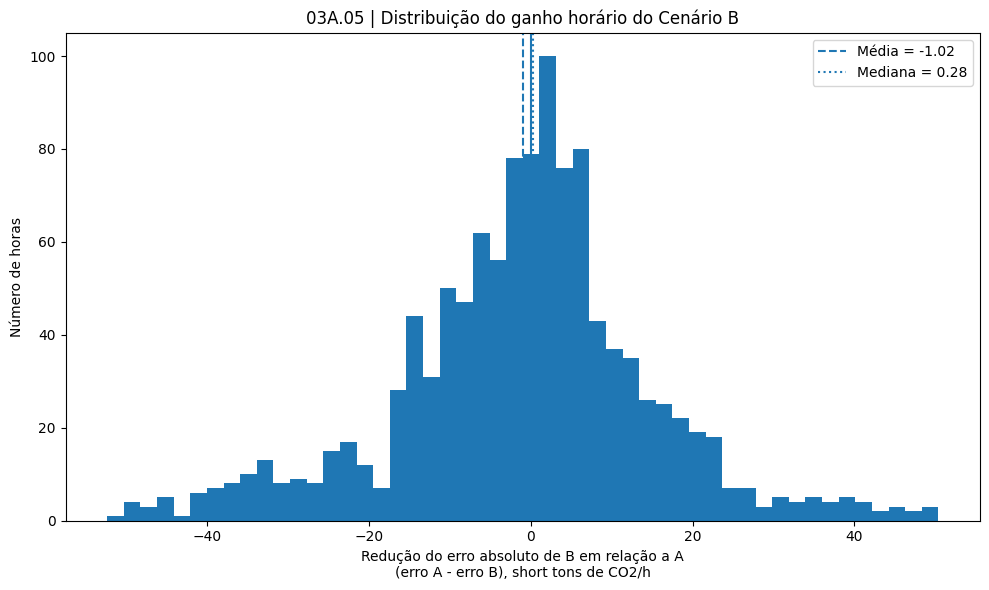

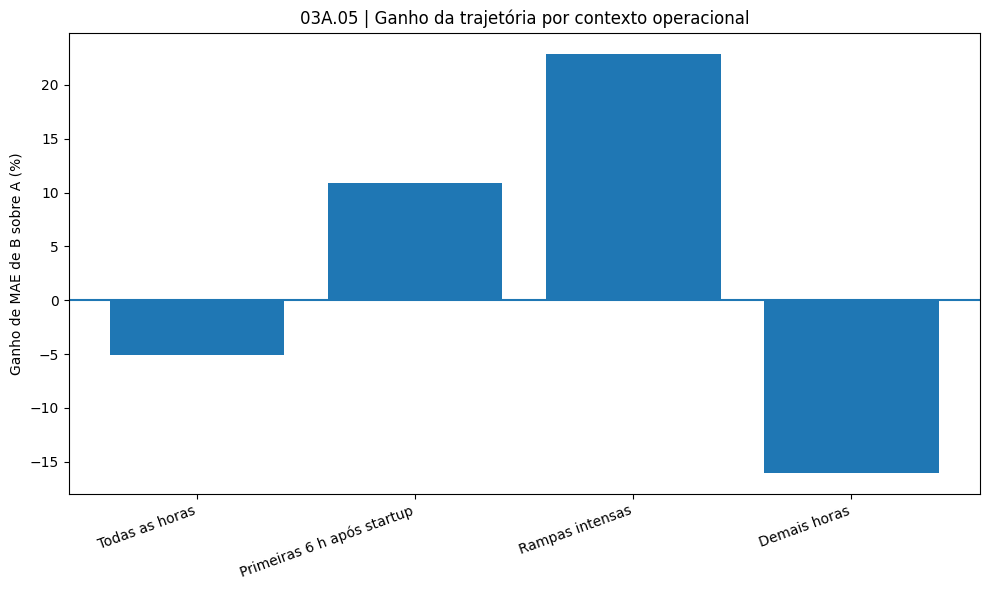


CÉLULA 8 CONCLUÍDA

Limiar de rampa intensa:
56.0000 MW/h

Tabela por contexto:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_comparacao_contextos_operacionais.csv

Quantis do ganho horário:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_quantis_ganho_horario_B_vs_A.csv

Maiores pioras de B:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_maiores_pioras_B.csv

Maiores melhorias de B:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_maiores_melhorias_B.csv

Resumo dos casos extremos:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A05_resumo_casos_extremos_B.csv

Base pareada com contextos:
/content/drive/MyDrive/co2-cems-thermal-modeling/data/interim/03A05_trajectory_history/03A05_previsoes_pareadas_com_contextos.parquet

Figuras:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/figures/03A05_distribuicao_ganho_horario_B_vs_A.png
/content/drive/MyDrive/co2-cems-thermal-m

In [10]:
# Referências metodológicas: (Hyndman; Koehler, 2006).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 8: DIAGNÓSTICO DO GANHO DA TRAJETÓRIA
# POR CONTEXTO OPERACIONAL
# ============================================================
#
# O QUE ESTA CÉLULA FAZ?
# ------------------------------------------------------------
#
# A Célula 7 mostrou que, no teste global de novembro e dezembro
# de 2025:
#
#     Cenário A:
#         MAE = 20.1514
#
#     Cenário B:
#         MAE = 21.1720
#
# Portanto, globalmente, o Cenário B apresentou piora de
# aproximadamente 5,06% no MAE.
#
#
# Entretanto, a comparação hora a hora mostrou algo importante:
#
#     B teve menor erro em aproximadamente 51% das horas.
#
#
# Isso significa que a piora global não ocorreu porque B foi
# pior em praticamente todas as observações.
#
# É possível que:
#
#     B melhore levemente muitas horas;
#
# mas:
#
#     piore bastante algumas horas específicas.
#
#
# OBJETIVO DESTA CÉLULA
# ------------------------------------------------------------
#
# Investigar se o benefício ou a piora associados às variáveis
# de trajetória dependem do contexto operacional.
#
#
# CONTEXTOS ANALISADOS
# ------------------------------------------------------------
#
# 1. Todas as horas do teste.
#
# 2. Primeiras 6 horas após startup.
#
# 3. Rampas intensas.
#
# 4. Demais horas de operação.
#
#
# Também examinaremos:
#
# - distribuição da diferença de erro entre B e A;
# - quantis dessa diferença;
# - horas em que B mais melhorou;
# - horas em que B mais piorou.
#
#
# IMPORTANTE
# ------------------------------------------------------------
#
# Nenhum modelo será treinado novamente.
#
# Utilizaremos exclusivamente:
#
#     paired_test_predictions
#
# produzido na Célula 7.
#
# Portanto, esta é uma análise diagnóstica do mesmo teste final,
# e não um novo experimento preditivo.
# ============================================================


# ============================================================
# 1. COPIAR A BASE DE PREVISÕES DO TESTE
# ============================================================
#
# paired_test_predictions contém exatamente as 1.144 horas de:
#
#     novembro e dezembro de 2025
#
# com:
#
#     valor observado;
#     previsão A;
#     previsão B;
#     resíduos;
#     erros absolutos;
#     informações operacionais.
#
#
# Utilizamos uma cópia para preservar a tabela original.
# ============================================================

context_test = (

    paired_test_predictions

    .copy()

    .reset_index(
        drop=True
    )

)


print(
    "Observações no teste:",
    f"{len(context_test):,}"
)


# ============================================================
# 2. DEFINIR O LIMIAR DE RAMPA INTENSA
# ============================================================
#
# Reproduzimos o mesmo princípio utilizado nos notebooks
# anteriores:
#
#     rampa intensa =
#
#         |ΔP| >= P90 da distribuição de |ΔP| no TREINO
#
#
# P90 significa percentil 90.
#
# Em termos simples:
#
# 90% das horas de treinamento possuem variação absoluta de
# carga abaixo desse valor.
#
# As aproximadamente 10% maiores variações são classificadas
# como rampas intensas.
#
#
# POR QUE O LIMIAR É CALCULADO NO TREINO?
# ------------------------------------------------------------
#
# Não queremos usar o próprio teste para decidir o que deve ser
# considerado uma rampa "intensa".
#
# Isso faria a definição do contexto depender de informações
# do período que está sendo avaliado.
#
#
# Neste notebook usamos train_final_common porque ele é o
# conjunto efetivamente utilizado para ajustar os modelos
# finais:
#
#     2011 a 2022
#
#     +
#
#     janeiro a outubro de 2025.
# ============================================================

RAMP_THRESHOLD = (

    train_final_common[
        "abs_delta_load_1h"
    ]

    .quantile(
        0.90
    )

)


print(
    "\nLimiar de rampa intensa, P90 do treino:",
    f"{RAMP_THRESHOLD:.4f} MW/h"
)


# ============================================================
# 3. IDENTIFICAR AS PRIMEIRAS 6 HORAS APÓS STARTUP
# ============================================================
#
# A feature hours_since_startup foi definida como:
#
#     1 = primeira hora após OFF -> ON
#     2 = segunda hora
#     ...
#
#
# Portanto, o contexto de startup utilizado nos experimentos
# anteriores corresponde a:
#
#     1 <= hours_since_startup <= 6
#
#
# Mantemos exatamente a mesma definição para permitir comparação
# com os notebooks anteriores.
# ============================================================

context_test[
    "startup_first_6h"
] = (

    (
        context_test[
            "hours_since_startup"
        ]
        >=
        1
    )

    &

    (
        context_test[
            "hours_since_startup"
        ]
        <=
        6
    )

)


# ============================================================
# 4. IDENTIFICAR RAMPAS INTENSAS
# ============================================================
#
# Uma hora é classificada como rampa intensa quando:
#
#     abs_delta_load_1h >= RAMP_THRESHOLD
#
#
# Como abs_delta_load_1h utiliza valor absoluto, entram tanto:
#
#     aumentos intensos de carga;
#
# quanto:
#
#     reduções intensas de carga.
# ============================================================

context_test[
    "intense_ramp"
] = (

    context_test[
        "abs_delta_load_1h"
    ]

    >=

    RAMP_THRESHOLD

)


# ============================================================
# 5. IDENTIFICAR AS DEMAIS HORAS
# ============================================================
#
# Criamos um contexto complementar:
#
#     regular_other
#
#
# Ele contém horas que NÃO pertencem:
#
#     às primeiras 6 horas após startup;
#
# nem:
#
#     às rampas intensas.
#
#
# Atenção:
#
# "demais horas" não significa necessariamente operação
# perfeitamente estável.
#
# Significa apenas que a observação não pertence aos dois
# contextos especiais definidos acima.
# ============================================================

context_test[
    "regular_other"
] = (

    ~

    (
        context_test[
            "startup_first_6h"
        ]

        |

        context_test[
            "intense_ramp"
        ]

    )

)


# ============================================================
# 6. IDENTIFICAR SOBREPOSIÇÃO ENTRE STARTUP E RAMPA
# ============================================================
#
# Startup e rampa intensa NÃO são categorias mutuamente
# exclusivas.
#
# Uma hora logo após um startup pode também apresentar grande
# variação de carga.
#
#
# Portanto, registramos a sobreposição explicitamente.
#
# Isso evita interpretar a soma dos tamanhos dos contextos como
# se eles representassem grupos completamente independentes.
# ============================================================

context_test[
    "startup_and_ramp"
] = (

    context_test[
        "startup_first_6h"
    ]

    &

    context_test[
        "intense_ramp"
    ]

)


n_startup = int(

    context_test[
        "startup_first_6h"
    ]

    .sum()

)


n_ramp = int(

    context_test[
        "intense_ramp"
    ]

    .sum()

)


n_overlap = int(

    context_test[
        "startup_and_ramp"
    ]

    .sum()

)


n_regular = int(

    context_test[
        "regular_other"
    ]

    .sum()

)


print("\n" + "=" * 72)

print(
    "COMPOSIÇÃO DOS CONTEXTOS"
)

print("=" * 72)


print(
    "Primeiras 6 h após startup:",
    n_startup
)


print(
    "Rampas intensas:",
    n_ramp
)


print(
    "Sobreposição startup + rampa:",
    n_overlap
)


print(
    "Demais horas:",
    n_regular
)


# ============================================================
# 7. FUNÇÃO PARA RESUMIR UM CONTEXTO
# ============================================================
#
# Para evitar repetir o mesmo código várias vezes, criamos uma
# função que recebe:
#
#     nome do contexto;
#     máscara booleana.
#
#
# Para cada grupo calcularemos:
#
# n
#     quantidade de horas.
#
#
# MAE_A e MAE_B
#     erro absoluto médio de cada cenário.
#
#
# ganho_B_vs_A_pct
#
#     positivo:
#         B possui MAE menor.
#
#     negativo:
#         B possui MAE maior.
#
#
# B_win_pct
#     percentual de horas em que B possui erro absoluto menor.
#
#
# mean_AE_reduction_B
#
#     média de:
#
#         abs_error_A - abs_error_B
#
#     positivo:
#         B melhora o erro em média.
#
#     negativo:
#         B piora o erro em média.
#
#
# median_AE_reduction_B
#
#     mesma diferença, mas utilizando a mediana.
#
#     Ela é menos sensível a algumas horas extremamente ruins.
#
#
# RMSE
#
#     também será calculado porque erros extremos possuem maior
#     peso nessa métrica.
#
#
# Bias
#
#     mantém a convenção:
#
#         observado - previsto.
# ============================================================

def summarize_context(
    context_name,
    mask
):


    subset = (

        context_test.loc[
            mask
        ]

        .copy()

    )


    # Se não houver nenhuma observação no contexto, devolvemos
    # uma linha preenchida com NaN em vez de gerar erro.

    if subset.empty:

        return {

            "contexto":
                context_name,

            "n":
                0,

            "MAE_A":
                np.nan,

            "MAE_B":
                np.nan,

            "ganho_B_vs_A_pct":
                np.nan,

            "RMSE_A":
                np.nan,

            "RMSE_B":
                np.nan,

            "ganho_RMSE_B_vs_A_pct":
                np.nan,

            "Bias_A":
                np.nan,

            "Bias_B":
                np.nan,

            "B_win_pct":
                np.nan,

            "mean_AE_reduction_B":
                np.nan,

            "median_AE_reduction_B":
                np.nan

        }


    # --------------------------------------------------------
    # MAE
    # --------------------------------------------------------

    mae_A = (

        subset[
            "abs_error_A"
        ]

        .mean()

    )


    mae_B = (

        subset[
            "abs_error_B"
        ]

        .mean()

    )


    # --------------------------------------------------------
    # GANHO RELATIVO DE MAE
    # --------------------------------------------------------

    mae_gain = (

        100
        *
        (
            mae_A
            -
            mae_B
        )
        /
        mae_A

        if mae_A != 0

        else np.nan

    )


    # --------------------------------------------------------
    # RMSE
    # --------------------------------------------------------
    #
    # Os resíduos já foram calculados na Célula 7.

    rmse_A = np.sqrt(

        np.mean(

            np.square(

                subset[
                    "residual_A"
                ]

            )

        )

    )


    rmse_B = np.sqrt(

        np.mean(

            np.square(

                subset[
                    "residual_B"
                ]

            )

        )

    )


    # --------------------------------------------------------
    # GANHO RELATIVO DE RMSE
    # --------------------------------------------------------

    rmse_gain = (

        100
        *
        (
            rmse_A
            -
            rmse_B
        )
        /
        rmse_A

        if rmse_A != 0

        else np.nan

    )


    # --------------------------------------------------------
    # BIAS
    # --------------------------------------------------------

    bias_A = (

        subset[
            "residual_A"
        ]

        .mean()

    )


    bias_B = (

        subset[
            "residual_B"
        ]

        .mean()

    )


    # --------------------------------------------------------
    # PERCENTUAL DE VITÓRIAS DE B
    # --------------------------------------------------------

    B_win_pct_context = (

        100
        *
        subset[
            "B_lower_error"
        ]

        .mean()

    )


    # --------------------------------------------------------
    # DIFERENÇA PAREADA DE ERRO
    # --------------------------------------------------------

    mean_reduction = (

        subset[
            "AE_reduction_B"
        ]

        .mean()

    )


    median_reduction = (

        subset[
            "AE_reduction_B"
        ]

        .median()

    )


    return {

        "contexto":
            context_name,

        "n":
            len(
                subset
            ),

        "MAE_A":
            mae_A,

        "MAE_B":
            mae_B,

        "ganho_B_vs_A_pct":
            mae_gain,

        "RMSE_A":
            rmse_A,

        "RMSE_B":
            rmse_B,

        "ganho_RMSE_B_vs_A_pct":
            rmse_gain,

        "Bias_A":
            bias_A,

        "Bias_B":
            bias_B,

        "B_win_pct":
            B_win_pct_context,

        "mean_AE_reduction_B":
            mean_reduction,

        "median_AE_reduction_B":
            median_reduction

    }


# ============================================================
# 8. DEFINIR OS CONTEXTOS ANALISADOS
# ============================================================
#
# "Todas as horas" fornece a referência global já observada na
# Célula 7.
#
#
# "Primeiras 6 h após startup" e "Rampas intensas" reproduzem
# os contextos utilizados anteriormente.
#
#
# "Demais horas" fornece um grupo complementar que ajuda a
# entender se a piora está concentrada fora dos regimes
# especiais.
#
#
# Startup e rampas continuam podendo se sobrepor.
# ============================================================

contexts = {

    "Todas as horas":

        pd.Series(

            True,

            index=context_test.index

        ),


    "Primeiras 6 h após startup":

        context_test[
            "startup_first_6h"
        ],


    "Rampas intensas":

        context_test[
            "intense_ramp"
        ],


    "Demais horas":

        context_test[
            "regular_other"
        ]

}


# ============================================================
# 9. CALCULAR OS RESULTADOS POR CONTEXTO
# ============================================================

context_rows = []


for (
    context_name,
    context_mask
) in contexts.items():


    context_rows.append(

        summarize_context(

            context_name,
            context_mask

        )

    )


context_results = pd.DataFrame(

    context_rows

)


print("\n" + "=" * 72)

print(
    "DESEMPENHO POR CONTEXTO OPERACIONAL"
)

print("=" * 72)


print(
    f"Limiar de rampa intensa: "
    f"|ΔP| >= {RAMP_THRESHOLD:.4f} MW/h"
)


display(

    context_results

    .round(
        4
    )

)


# ============================================================
# 10. INTERPRETAÇÃO DO SINAL DO GANHO
# ============================================================
#
# Para facilitar a leitura criamos uma classificação textual.
#
#
# ganho > 0:
#
#     B possui menor MAE.
#
#
# ganho < 0:
#
#     B possui maior MAE.
#
#
# Essa classificação não define significância estatística.
#
# Ela apenas descreve a direção do resultado observado.
# ============================================================

context_results[
    "direcao_resultado"
] = np.where(

    context_results[
        "ganho_B_vs_A_pct"
    ]
    >
    0,

    "B com menor MAE",

    np.where(

        context_results[
            "ganho_B_vs_A_pct"
        ]
        <
        0,

        "A com menor MAE",

        "MAE igual"

    )

)


# ============================================================
# 11. DISTRIBUIÇÃO DA DIFERENÇA PAREADA DE ERRO
# ============================================================
#
# Na Célula 7 definimos:
#
#     AE_reduction_B =
#
#         abs_error_A - abs_error_B
#
#
# Portanto:
#
# valor positivo:
#     B foi melhor.
#
# valor negativo:
#     B foi pior.
#
#
# Agora calculamos alguns percentis para entender a forma dessa
# distribuição.
#
#
# Isso é importante porque:
#
#     média = -1.0206
#
# enquanto:
#
#     mediana = +0.2814
#
#
# Essa diferença sugere assimetria e possível presença de
# algumas perdas maiores do Cenário B.
# ============================================================

AE_REDUCTION_QUANTILES = [

    0.01,
    0.05,
    0.10,
    0.25,
    0.50,
    0.75,
    0.90,
    0.95,
    0.99

]


paired_error_quantiles = (

    context_test[
        "AE_reduction_B"
    ]

    .quantile(
        AE_REDUCTION_QUANTILES
    )

    .rename(
        "AE_reduction_B"
    )

    .reset_index()

    .rename(
        columns={
            "index":
                "quantile"
        }
    )

)


print("\n" + "=" * 72)

print(
    "QUANTIS DA REDUÇÃO PAREADA DO ERRO"
)

print("=" * 72)


print(
    "Valor positivo = B melhor"
)


print(
    "Valor negativo = B pior"
)


display(

    paired_error_quantiles

    .round(
        4
    )

)


# ============================================================
# 12. IDENTIFICAR AS HORAS EM QUE B MAIS PIOROU
# ============================================================
#
# Ordenamos AE_reduction_B do menor para o maior.
#
# Como valores negativos significam piora de B, as primeiras
# linhas representam as maiores perdas associadas ao Cenário B.
#
#
# Isso NÃO será utilizado para ajustar o modelo.
#
# A análise é exclusivamente diagnóstica.
# ============================================================

N_EXTREME_CASES = 20


worst_B_cases = (

    context_test

    .sort_values(
        "AE_reduction_B",
        ascending=True
    )

    .head(
        N_EXTREME_CASES
    )

    [

        [

            "timestamp",
            "load_current_mw",
            "delta_load_1h",
            "abs_delta_load_1h",
            "hours_since_startup",
            "startup_first_6h",
            "intense_ramp",
            TARGET,
            "pred_A",
            "pred_B",
            "abs_error_A",
            "abs_error_B",
            "AE_reduction_B"

        ]

    ]

    .copy()

)


print("\n" + "=" * 72)

print(
    "20 HORAS EM QUE O CENÁRIO B MAIS PIOROU"
)

print("=" * 72)


display(

    worst_B_cases

    .round(
        4
    )

)


# ============================================================
# 13. IDENTIFICAR AS HORAS EM QUE B MAIS MELHOROU
# ============================================================
#
# Agora fazemos o contrário.
#
# Os maiores valores positivos de AE_reduction_B correspondem
# às horas em que a trajetória mais reduziu o erro.
# ============================================================

best_B_cases = (

    context_test

    .sort_values(
        "AE_reduction_B",
        ascending=False
    )

    .head(
        N_EXTREME_CASES
    )

    [

        [

            "timestamp",
            "load_current_mw",
            "delta_load_1h",
            "abs_delta_load_1h",
            "hours_since_startup",
            "startup_first_6h",
            "intense_ramp",
            TARGET,
            "pred_A",
            "pred_B",
            "abs_error_A",
            "abs_error_B",
            "AE_reduction_B"

        ]

    ]

    .copy()

)


print("\n" + "=" * 72)

print(
    "20 HORAS EM QUE O CENÁRIO B MAIS MELHOROU"
)

print("=" * 72)


display(

    best_B_cases

    .round(
        4
    )

)


# ============================================================
# 14. RESUMIR OS CASOS EXTREMOS
# ============================================================
#
# Queremos saber se os maiores ganhos ou perdas de B estão
# concentrados em:
#
#     startups;
#
#     rampas;
#
#     ou nenhum dos dois.
#
#
# Não estamos criando um novo critério preditivo.
#
# Estamos apenas descrevendo os extremos já observados.
# ============================================================

extreme_case_summary = pd.DataFrame(

    [

        {

            "grupo":
                "20 maiores pioras de B",

            "n":
                len(
                    worst_B_cases
                ),

            "startup_first_6h":
                int(
                    worst_B_cases[
                        "startup_first_6h"
                    ].sum()
                ),

            "intense_ramp":
                int(
                    worst_B_cases[
                        "intense_ramp"
                    ].sum()
                ),

            "startup_and_ramp":
                int(

                    (

                        worst_B_cases[
                            "startup_first_6h"
                        ]

                        &

                        worst_B_cases[
                            "intense_ramp"
                        ]

                    ).sum()

                ),

            "mean_AE_reduction_B":
                worst_B_cases[
                    "AE_reduction_B"
                ].mean()

        },

        {

            "grupo":
                "20 maiores melhorias de B",

            "n":
                len(
                    best_B_cases
                ),

            "startup_first_6h":
                int(
                    best_B_cases[
                        "startup_first_6h"
                    ].sum()
                ),

            "intense_ramp":
                int(
                    best_B_cases[
                        "intense_ramp"
                    ].sum()
                ),

            "startup_and_ramp":
                int(

                    (

                        best_B_cases[
                            "startup_first_6h"
                        ]

                        &

                        best_B_cases[
                            "intense_ramp"
                        ]

                    ).sum()

                ),

            "mean_AE_reduction_B":
                best_B_cases[
                    "AE_reduction_B"
                ].mean()

        }

    ]

)


print("\n" + "=" * 72)

print(
    "RESUMO DOS CASOS EXTREMOS"
)

print("=" * 72)


display(

    extreme_case_summary

    .round(
        4
    )

)


# ============================================================
# 15. FIGURA 1: DISTRIBUIÇÃO DA DIFERENÇA DE ERRO
# ============================================================
#
# O histograma mostra:
#
#     abs_error_A - abs_error_B
#
#
# Linha vertical em zero:
#
#     separa as horas em que A e B possuem melhor desempenho.
#
#
# Lado positivo:
#
#     B melhor.
#
#
# Lado negativo:
#
#     B pior.
#
#
# A figura ajuda a visualizar por que a mediana pode ser
# positiva enquanto a média é negativa.
# ============================================================

plt.figure(
    figsize=(10, 6)
)


plt.hist(

    context_test[
        "AE_reduction_B"
    ],

    bins=50

)


plt.axvline(

    0,

    linewidth=1.5

)


plt.axvline(

    context_test[
        "AE_reduction_B"
    ].mean(),

    linestyle="--",

    linewidth=1.5,

    label=(
        "Média = "
        f"{context_test['AE_reduction_B'].mean():.2f}"
    )

)


plt.axvline(

    context_test[
        "AE_reduction_B"
    ].median(),

    linestyle=":",

    linewidth=1.5,

    label=(
        "Mediana = "
        f"{context_test['AE_reduction_B'].median():.2f}"
    )

)


plt.xlabel(
    "Redução do erro absoluto de B em relação a A\n"
    "(erro A - erro B), short tons de CO2/h"
)


plt.ylabel(
    "Número de horas"
)


plt.title(
    "03A.05 | Distribuição do ganho horário do Cenário B"
)


plt.legend()


plt.tight_layout()


AE_DISTRIBUTION_FIG_PATH = (

    FIGURES
    /
    "03A05_distribuicao_ganho_horario_B_vs_A.png"

)


plt.savefig(

    AE_DISTRIBUTION_FIG_PATH,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 16. FIGURA 2: GANHO DE MAE POR CONTEXTO
# ============================================================
#
# Esta figura resume o sinal do ganho de B.
#
#
# Acima de zero:
#
#     B reduz o MAE.
#
#
# Abaixo de zero:
#
#     B aumenta o MAE.
#
#
# Não adicionamos outros contextos além dos definidos antes da
# análise.
# ============================================================

plt.figure(
    figsize=(10, 6)
)


plt.bar(

    context_results[
        "contexto"
    ],

    context_results[
        "ganho_B_vs_A_pct"
    ]

)


plt.axhline(

    0,

    linewidth=1.5

)


plt.ylabel(
    "Ganho de MAE de B sobre A (%)"
)


plt.title(
    "03A.05 | Ganho da trajetória por contexto operacional"
)


plt.xticks(
    rotation=20,
    ha="right"
)


plt.tight_layout()


CONTEXT_GAIN_FIG_PATH = (

    FIGURES
    /
    "03A05_ganho_trajetoria_por_contexto.png"

)


plt.savefig(

    CONTEXT_GAIN_FIG_PATH,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 17. SALVAR A TABELA DE RESULTADOS POR CONTEXTO
# ============================================================

CONTEXT_RESULTS_PATH = (

    TABLES
    /
    "03A05_comparacao_contextos_operacionais.csv"

)


context_results.to_csv(

    CONTEXT_RESULTS_PATH,

    index=False

)


# ============================================================
# 18. SALVAR OS QUANTIS DA DIFERENÇA DE ERRO
# ============================================================

ERROR_QUANTILES_PATH = (

    TABLES
    /
    "03A05_quantis_ganho_horario_B_vs_A.csv"

)


paired_error_quantiles.to_csv(

    ERROR_QUANTILES_PATH,

    index=False

)


# ============================================================
# 19. SALVAR OS CASOS EXTREMOS
# ============================================================
#
# Preservamos as horas que mais contribuíram para:
#
#     piora de B;
#
#     melhoria de B.
#
#
# Isso permite auditoria posterior sem precisar reconstruir
# manualmente a ordenação.
# ============================================================

WORST_B_CASES_PATH = (

    TABLES
    /
    "03A05_maiores_pioras_B.csv"

)


BEST_B_CASES_PATH = (

    TABLES
    /
    "03A05_maiores_melhorias_B.csv"

)


EXTREME_SUMMARY_PATH = (

    TABLES
    /
    "03A05_resumo_casos_extremos_B.csv"

)


worst_B_cases.to_csv(

    WORST_B_CASES_PATH,

    index=False

)


best_B_cases.to_csv(

    BEST_B_CASES_PATH,

    index=False

)


extreme_case_summary.to_csv(

    EXTREME_SUMMARY_PATH,

    index=False

)


# ============================================================
# 20. SALVAR A BASE DE TESTE COM OS CONTEXTOS
# ============================================================
#
# paired_test_predictions já foi salva na Célula 7.
#
# Nesta célula acrescentamos:
#
#     startup_first_6h;
#     intense_ramp;
#     regular_other;
#     startup_and_ramp.
#
#
# Salvamos uma nova versão para não sobrescrever silenciosamente
# o arquivo anterior.
# ============================================================

CONTEXT_TEST_PATH = (

    EXPERIMENT_DIR
    /
    "03A05_previsoes_pareadas_com_contextos.parquet"

)


context_test.to_parquet(

    CONTEXT_TEST_PATH,

    index=False

)


# ============================================================
# 21. RESUMO FINAL DA CÉLULA
# ============================================================
#
# Esta célula NÃO altera a conclusão global da Célula 7.
#
# O objetivo é explicar melhor:
#
#     onde B ajuda;
#
#     onde B piora;
#
#     e se as maiores diferenças estão relacionadas a startup
#     ou rampas intensas.
#
#
# A interpretação científica deve ser feita somente depois de
# observar os resultados efetivamente produzidos.
# ============================================================

print("\n" + "=" * 72)

print(
    "CÉLULA 8 CONCLUÍDA"
)

print("=" * 72)


print(
    "\nLimiar de rampa intensa:"
)


print(
    f"{RAMP_THRESHOLD:.4f} MW/h"
)


print(
    "\nTabela por contexto:"
)


print(
    CONTEXT_RESULTS_PATH
)


print(
    "\nQuantis do ganho horário:"
)


print(
    ERROR_QUANTILES_PATH
)


print(
    "\nMaiores pioras de B:"
)


print(
    WORST_B_CASES_PATH
)


print(
    "\nMaiores melhorias de B:"
)


print(
    BEST_B_CASES_PATH
)


print(
    "\nResumo dos casos extremos:"
)


print(
    EXTREME_SUMMARY_PATH
)


print(
    "\nBase pareada com contextos:"
)


print(
    CONTEXT_TEST_PATH
)


print(
    "\nFiguras:"
)


print(
    AE_DISTRIBUTION_FIG_PATH
)


print(
    CONTEXT_GAIN_FIG_PATH
)


print(
    "\nNenhum modelo foi retreinado nesta célula."
)

## Diagnóstico adicional de cobertura operacional

Potts et al. (2026), em um preprint sobre monitoramento preditivo de emissões em frotas de turbinas a gás, usam a presença de atributos fora das faixas observadas no treinamento como um dos sinais de operação fora da distribuição conhecida. A célula seguinte incorpora **somente esse princípio simples de cobertura por faixa** ao presente estudo.

O diagnóstico compara, para as sete variáveis do Cenário B, os valores do teste com os mínimos e máximos observados no conjunto de treinamento final. Ele **não reproduz** o sistema completo de confiança de Potts et al. (2026): não calcula distância de Mahalanobis, incerteza de ensemble, predição auxiliar ou escore de confiança. Também não altera treinamento, hiperparâmetros, previsões ou resultados centrais já reproduzidos.

**Nota de rastreabilidade atualizada:** o diagnóstico foi executado na rodada recebida de 29/10/2026. Nenhum dos sete atributos apresentou valores do teste fora de sua faixa marginal de treino. Esse resultado não demonstra cobertura conjunta do espaço de atributos, ausência de mudança de distribuição ou confiança calibrada. As saídas originais foram preservadas.


In [11]:
# ============================================================
# DIAGNÓSTICO ADICIONAL: COBERTURA OPERACIONAL DO TESTE
# ============================================================
#
# Referência metodológica de inspiração:
#
# POTTS, R.; DURRANT, A.; HACKNEY, R.; LEONTIDIS, G. (2026).
# Trust-Aware Predictive Emissions Monitoring for Gas Turbine
# Fleets with Limited Labelled Data. arXiv:2606.06156.
#
# Potts et al. utilizam a quantidade de atributos fora das
# faixas observadas no treinamento como um dos sinais de
# operação fora da distribuição conhecida. Aqui adotamos
# APENAS esse diagnóstico simples de faixa.
#
# NÃO implementamos o framework completo do artigo:
# - não há Mahalanobis distance;
# - não há ensemble uncertainty;
# - não há auxiliary feature prediction;
# - não há trust score.
#
# Esta célula NÃO treina novos modelos e NÃO modifica as
# previsões de A ou B. Ela apenas caracteriza a cobertura
# operacional do teste em relação ao treinamento final.
# ============================================================

# 1. Limites observados no treinamento final para FEATURES_B.
operating_range_rows = []
outside_by_feature = pd.DataFrame(index=test_common.index)

for feature in FEATURES_B:

    train_values = pd.to_numeric(
        train_final_common[feature],
        errors="coerce"
    )

    test_values = pd.to_numeric(
        test_common[feature],
        errors="coerce"
    )

    train_min = float(train_values.min())
    train_max = float(train_values.max())

    below = test_values < train_min
    above = test_values > train_max
    outside = below | above

    outside_by_feature[feature] = outside.fillna(False)

    operating_range_rows.append(
        {
            "feature": feature,
            "train_min": train_min,
            "train_max": train_max,
            "test_min": float(test_values.min()),
            "test_max": float(test_values.max()),
            "n_below_train_min": int(below.sum()),
            "n_above_train_max": int(above.sum()),
            "n_outside_train_range": int(outside.sum()),
            "pct_outside_train_range": float(100 * outside.mean())
        }
    )

operating_range_by_feature = pd.DataFrame(operating_range_rows)

# 2. Número de variáveis fora da faixa em cada hora do teste.
operating_range_by_hour = test_common[["timestamp"]].copy()
operating_range_by_hour["n_features_outside_train_range"] = (
    outside_by_feature.sum(axis=1).astype(int).to_numpy()
)
operating_range_by_hour["outside_any_train_range"] = (
    operating_range_by_hour["n_features_outside_train_range"] > 0
)

# 3. Relacionar o diagnóstico aos erros já calculados.
# A junção por timestamp evita depender apenas da posição das linhas.
coverage_error_base = paired_test_predictions[
    [
        "timestamp",
        TARGET,
        "pred_A",
        "pred_B",
        "abs_error_A",
        "abs_error_B"
    ]
].merge(
    operating_range_by_hour,
    on="timestamp",
    how="left",
    validate="one_to_one"
)

# 4. Resumo do erro dentro e fora das faixas observadas no treino.
coverage_error_summary = (
    coverage_error_base
    .groupby("outside_any_train_range", dropna=False)
    .agg(
        n=("timestamp", "size"),
        mae_A=("abs_error_A", "mean"),
        mae_B=("abs_error_B", "mean"),
        mean_n_features_outside=("n_features_outside_train_range", "mean")
    )
    .reset_index()
)

coverage_error_summary["gain_B_pct"] = (
    100
    * (
        coverage_error_summary["mae_A"]
        - coverage_error_summary["mae_B"]
    )
    / coverage_error_summary["mae_A"]
)

# 5. Persistência dos resultados do diagnóstico.
operating_range_by_feature.to_csv(
    TABLES / "03A05_cobertura_faixa_operacional_features.csv",
    index=False
)

coverage_error_summary.to_csv(
    TABLES / "03A05_cobertura_faixa_operacional_erros.csv",
    index=False
)

operating_range_by_hour.to_csv(
    TABLES / "03A05_cobertura_faixa_operacional_horas.csv",
    index=False
)

print("\nCobertura por feature:")
display(operating_range_by_feature)

print("\nErro por condição de cobertura:")
display(coverage_error_summary)



Cobertura por feature:


,feature,train_min,train_max,test_min,test_max,n_below_train_min,n_above_train_max,n_outside_train_range,pct_outside_train_range
0,load_current_mw,0.0,955.0,0.0,948.000000,0,0,0,0.0
1,load_lag_1h,0.0,955.0,0.0,948.000000,0,0,0,0.0
2,delta_load_1h,-802.0,448.0,-776.0,244.000000,0,0,0,0.0
3,abs_delta_load_1h,0.0,802.0,0.0,776.000000,0,0,0,0.0
4,load_mean_previous_3h,0.0,955.0,0.0,945.666667,0,0,0,0.0
5,operating_time_lag_1h,0.0,1.0,0.0,1.000000,0,0,0,0.0
6,hours_since_startup,1.0,9539.0,1.0,530.000000,0,0,0,0.0



Erro por condição de cobertura:


,outside_any_train_range,n,mae_A,mae_B,mean_n_features_outside,gain_B_pct
0,False,1144,20.151419,21.171987,0.0,-5.064495


In [12]:
# ============================================================
# CÉLULA 9: RELATÓRIO FORMAL DO NOTEBOOK 03A.05
# ============================================================
#
# TÍTULO DO NOTEBOOK
# ------------------------------------------------------------
#
# 03A.05
# Trajetória operacional com histórico ampliado
#
#
# PERGUNTA DE PESQUISA
# ------------------------------------------------------------
#
# "Com histórico ampliado, a inclusão de variáveis de trajetória
# operacional melhora a previsão de CO2 em relação ao uso
# exclusivo da carga instantânea?"
#
#
# O QUE ESTA CÉLULA FAZ?
# ------------------------------------------------------------
#
# Esta célula encerra formalmente o Notebook 03A.05.
#
# Ela NÃO:
#
# - treina novos modelos;
# - altera hiperparâmetros;
# - recalcula previsões;
# - procura um novo cenário;
# - modifica os resultados obtidos.
#
#
# Ela utiliza exclusivamente os objetos, tabelas, métricas e
# decisões produzidos nas células anteriores para:
#
# 1. consolidar as evidências quantitativas;
#
# 2. registrar as principais decisões metodológicas;
#
# 3. construir uma tabela de síntese do experimento;
#
# 4. construir uma tabela específica de decisões metodológicas;
#
# 5. produzir um relatório formal em Markdown;
#
# 6. registrar limitações e escopo de interpretação;
#
# 7. formular a conclusão científica do notebook.
#
#
# POR QUE GERAR O RELATÓRIO A PARTIR DAS VARIÁVEIS?
# ------------------------------------------------------------
#
# Os números do relatório NÃO serão digitados manualmente.
#
# Eles serão extraídos diretamente de objetos como:
#
#     selection_results
#     test_results
#     incremental_trajectory_gain
#     context_results
#
#
# Isso reduz o risco de divergência entre:
#
#     resultado executado no notebook
#
# e:
#
#     resultado escrito no relatório.
#
# ============================================================


# ============================================================
# 1. IMPORTAÇÕES AUXILIARES
# ============================================================
#
# textwrap.dedent permite escrever o relatório como um bloco
# de texto multilinha mantendo o código organizado.
# ============================================================

from textwrap import dedent


# ============================================================
# 2. GARANTIR A EXISTÊNCIA DA PASTA DE RELATÓRIOS
# ============================================================
#
# Utilizamos o mesmo diretório estrutural dos notebooks
# anteriores:
#
#     outputs/reports
# ============================================================

REPORTS_03A05 = (

    ROOT
    /
    "outputs"
    /
    "reports"

)


REPORTS_03A05.mkdir(

    parents=True,

    exist_ok=True

)


# ============================================================
# 3. FUNÇÃO DE FORMATAÇÃO NUMÉRICA PARA O RELATÓRIO
# ============================================================
#
# Os arquivos CSV permanecem com valores numéricos normais.
#
# Entretanto, o relatório será escrito em português.
#
# Esta função transforma:
#
#     20.1514
#
# em:
#
#     20,1514
#
# somente para apresentação textual.
#
#
# O valor numérico original NÃO é modificado.
# ============================================================

def pt_number(
    value,
    decimals=4
):


    if pd.isna(
        value
    ):

        return "NA"


    formatted = (

        f"{float(value):,.{decimals}f}"

    )


    # Primeiro protegemos o separador decimal.
    #
    # Exemplo:
    #
    #     1,234.5678
    #
    # vira:
    #
    #     1.234,5678

    formatted = (

        formatted

        .replace(
            ",",
            "TEMP"
        )

        .replace(
            ".",
            ","
        )

        .replace(
            "TEMP",
            "."
        )

    )


    return formatted


# ============================================================
# 4. RECUPERAR AS LINHAS PRINCIPAIS DOS RESULTADOS
# ============================================================
#
# Não recalculamos nenhuma métrica.
#
# Apenas recuperamos as linhas já produzidas anteriormente.
# ============================================================

selection_A = (

    selection_results.loc[

        selection_results[
            "scenario"
        ]
        ==
        "A"

    ]

    .iloc[0]

)


selection_B = (

    selection_results.loc[

        selection_results[
            "scenario"
        ]
        ==
        "B"

    ]

    .iloc[0]

)


test_A = (

    test_results.loc[

        test_results[
            "scenario"
        ]
        ==
        "A"

    ]

    .iloc[0]

)


test_B = (

    test_results.loc[

        test_results[
            "scenario"
        ]
        ==
        "B"

    ]

    .iloc[0]

)


gain_final = (

    incremental_trajectory_gain

    .iloc[0]

)


# ============================================================
# 5. RECUPERAR OS RESULTADOS POR CONTEXTO
# ============================================================
#
# Os nomes abaixo correspondem aos contextos definidos
# previamente na Célula 8.
# ============================================================

context_global = (

    context_results.loc[

        context_results[
            "contexto"
        ]
        ==
        "Todas as horas"

    ]

    .iloc[0]

)


context_startup = (

    context_results.loc[

        context_results[
            "contexto"
        ]
        ==
        "Primeiras 6 h após startup"

    ]

    .iloc[0]

)


context_ramp = (

    context_results.loc[

        context_results[
            "contexto"
        ]
        ==
        "Rampas intensas"

    ]

    .iloc[0]

)


context_regular = (

    context_results.loc[

        context_results[
            "contexto"
        ]
        ==
        "Demais horas"

    ]

    .iloc[0]

)


# ============================================================
# 6. RECUPERAR INFORMAÇÕES SOBRE OS CASOS EXTREMOS
# ============================================================
#
# A Célula 8 mostrou também onde estavam concentradas as maiores
# melhorias e pioras do Cenário B.
#
# Extraímos essas informações da tabela já construída.
# ============================================================

extreme_worst = (

    extreme_case_summary.loc[

        extreme_case_summary[
            "grupo"
        ]
        ==
        "20 maiores pioras de B"

    ]

    .iloc[0]

)


extreme_best = (

    extreme_case_summary.loc[

        extreme_case_summary[
            "grupo"
        ]
        ==
        "20 maiores melhorias de B"

    ]

    .iloc[0]

)


# ============================================================
# 7. AUDITAR O REGISTRO DE CARGA AUSENTE DE 2019
# ============================================================
#
# Não alteramos esse registro.
#
# Apenas recuperamos a quantidade para registrá-la formalmente
# no relatório.
# ============================================================

missing_load_operating_rows = (

    df_features.loc[

        df_features[
            "is_on"
        ]

        &

        df_features[
            "Gross Load (MW)"
        ]

        .isna()

    ]

    .copy()

)


n_missing_load_operating = len(

    missing_load_operating_rows

)


# ============================================================
# 8. CONSTRUIR TABELA DE DECISÕES METODOLÓGICAS
# ============================================================
#
# Esta tabela documenta decisões que modificaram a forma como
# a amostra ou o experimento foi construído.
#
#
# Ela é especialmente importante porque permite distinguir:
#
#     decisão metodológica
#
# de:
#
#     resultado empírico.
#
#
# Dessa forma, alguém lendo o repositório posteriormente pode
# compreender por que determinadas observações foram incluídas
# ou excluídas.
# ============================================================

methodological_decisions = pd.DataFrame(

    [

        {

            "ordem":
                1,

            "tema":
                "Período histórico",

            "decisao":
                "Utilizar 2011 a 2022 como histórico de referência.",

            "justificativa":
                (
                    "2010 corresponde ao período inicial de entrada "
                    "em operação e não foi utilizado como referência. "
                    "Os anos de 2023 e 2024 foram previamente "
                    "caracterizados como regime operacional distinto "
                    "do intervalo empírico observado em 2011 a 2022."
                )

        },

        {

            "ordem":
                2,

            "tema":
                "Preservação das horas OFF",

            "decisao":
                (
                    "Manter horas OFF durante a construção das "
                    "variáveis temporais."
                ),

            "justificativa":
                (
                    "As horas OFF são necessárias para reconstruir "
                    "transições OFF para ON e identificar startups."
                )

        },

        {

            "ordem":
                3,

            "tema":
                "Carga ausente em 2019",

            "decisao":
                (
                    "Preservar o NaN da carga durante operação e "
                    "não realizar imputação."
                ),

            "justificativa":
                (
                    "Foi identificado um único registro de carga "
                    "ausente durante operação. A imputação criaria "
                    "um valor não observado. As linhas sem vetor "
                    "completo de features foram excluídas da "
                    "amostra pareada."
                )

        },

        {

            "ordem":
                4,

            "tema":
                "Blocos temporais",

            "decisao":
                (
                    "Calcular lags e médias móveis separadamente "
                    "nos blocos 2011 a 2022 e 2025."
                ),

            "justificativa":
                (
                    "Essa regra impede que dezembro de 2022 seja "
                    "utilizado artificialmente como passado "
                    "imediato de janeiro de 2025."
                )

        },

        {

            "ordem":
                5,

            "tema":
                "Início de 2011",

            "decisao":
                (
                    "Excluir da comparação A x B as 250 horas "
                    "iniciais em operação com idade do startup "
                    "desconhecida."
                ),

            "justificativa":
                (
                    "A série começa com a unidade já ligada. "
                    "Não existe informação anterior suficiente "
                    "para determinar o tempo real desde o startup."
                )

        },

        {

            "ordem":
                6,

            "tema":
                "Comparação pareada",

            "decisao":
                (
                    "Utilizar exatamente as mesmas observações "
                    "para os Cenários A e B."
                ),

            "justificativa":
                (
                    "A diferença entre os cenários deve decorrer "
                    "das features utilizadas e não de diferenças "
                    "na composição da amostra."
                )

        },

        {

            "ordem":
                7,

            "tema":
                "Seleção de complexidade",

            "decisao":
                (
                    "Utilizar outubro de 2025 como validação "
                    "para early stopping."
                ),

            "justificativa":
                (
                    "Cada representação pode exigir número "
                    "diferente de árvores, mas ambas utilizam "
                    "o mesmo período de validação e os mesmos "
                    "hiperparâmetros estruturais."
                )

        },

        {

            "ordem":
                8,

            "tema":
                "Refit final",

            "decisao":
                (
                    "Após selecionar o número de árvores, "
                    "reincorporar outubro ao treinamento e "
                    "remover o early stopping."
                ),

            "justificativa":
                (
                    "A complexidade já havia sido selecionada. "
                    "O treinamento final utiliza todas as "
                    "observações permitidas até outubro de 2025."
                )

        },

        {

            "ordem":
                9,

            "tema":
                "Teste temporal",

            "decisao":
                (
                    "Avaliar A e B nas mesmas 1.144 horas de "
                    "novembro e dezembro de 2025."
                ),

            "justificativa":
                (
                    "Esse período não foi usado no ajuste nem "
                    "na seleção de complexidade dentro do 03A.05."
                )

        },

        {

            "ordem":
                10,

            "tema":
                "Rampas intensas",

            "decisao":
                (
                    "Definir rampa intensa por |delta P| maior "
                    "ou igual ao P90 calculado no treinamento."
                ),

            "justificativa":
                (
                    "O limiar é determinado sem utilizar a "
                    "distribuição do conjunto de teste e mantém "
                    "o critério empregado nas análises anteriores."
                )

        }

    ]

)


# ============================================================
# 9. CONSTRUIR TABELA-SÍNTESE DAS EVIDÊNCIAS
# ============================================================
#
# Esta tabela reúne em um único arquivo os números que sustentam
# a conclusão do notebook.
#
#
# Ela não substitui as tabelas detalhadas já produzidas.
#
# Sua função é permitir leitura rápida e facilitar a utilização
# dos resultados em:
#
#     relatório;
#     artigo;
#     apresentação;
#     README;
#     discussão metodológica.
# ============================================================

evidence_summary = pd.DataFrame(

    [

        # ----------------------------------------------------
        # AMOSTRA
        # ----------------------------------------------------

        {

            "etapa":
                "Amostra",

            "indicador":
                "Horas operacionais disponíveis",

            "cenario_A":
                np.nan,

            "cenario_B":
                np.nan,

            "valor":
                n_operating_all,

            "ganho_B_vs_A_pct":
                np.nan,

            "observacao":
                "2011 a 2022 e 2025."

        },

        {

            "etapa":
                "Amostra",

            "indicador":
                "Horas da amostra comum A x B",

            "cenario_A":
                np.nan,

            "cenario_B":
                np.nan,

            "valor":
                n_common,

            "ganho_B_vs_A_pct":
                np.nan,

            "observacao":
                (
                    "Mesmas observações utilizadas pelos dois "
                    "cenários."
                )

        },

        {

            "etapa":
                "Amostra",

            "indicador":
                "Histórico comum 2011 a 2022",

            "cenario_A":
                np.nan,

            "cenario_B":
                np.nan,

            "valor":
                len(
                    history_common
                ),

            "ganho_B_vs_A_pct":
                np.nan,

            "observacao":
                (
                    "Após critérios de elegibilidade da comparação."
                )

        },

        {

            "etapa":
                "Amostra",

            "indicador":
                "Teste final nov-dez/2025",

            "cenario_A":
                np.nan,

            "cenario_B":
                np.nan,

            "valor":
                len(
                    test_common
                ),

            "ganho_B_vs_A_pct":
                np.nan,

            "observacao":
                "Teste pareado."

        },

        # ----------------------------------------------------
        # VALIDAÇÃO
        # ----------------------------------------------------

        {

            "etapa":
                "Validação outubro/2025",

            "indicador":
                "Árvores selecionadas",

            "cenario_A":
                selection_A[
                    "selected_trees"
                ],

            "cenario_B":
                selection_B[
                    "selected_trees"
                ],

            "valor":
                np.nan,

            "ganho_B_vs_A_pct":
                np.nan,

            "observacao":
                (
                    "Complexidade definida por early stopping."
                )

        },

        {

            "etapa":
                "Validação outubro/2025",

            "indicador":
                "MAE",

            "cenario_A":
                selection_A[
                    "validation_MAE"
                ],

            "cenario_B":
                selection_B[
                    "validation_MAE"
                ],

            "valor":
                np.nan,

            "ganho_B_vs_A_pct":
                validation_mae_gain_pct,

            "observacao":
                (
                    "Resultado de validação, não resultado final."
                )

        },

        {

            "etapa":
                "Validação outubro/2025",

            "indicador":
                "RMSE",

            "cenario_A":
                selection_A[
                    "validation_RMSE"
                ],

            "cenario_B":
                selection_B[
                    "validation_RMSE"
                ],

            "valor":
                np.nan,

            "ganho_B_vs_A_pct":
                validation_rmse_gain_pct,

            "observacao":
                (
                    "B apresentou melhor desempenho em outubro."
                )

        },

        # ----------------------------------------------------
        # TESTE GLOBAL
        # ----------------------------------------------------

        {

            "etapa":
                "Teste global",

            "indicador":
                "MAE",

            "cenario_A":
                test_A[
                    "MAE"
                ],

            "cenario_B":
                test_B[
                    "MAE"
                ],

            "valor":
                np.nan,

            "ganho_B_vs_A_pct":
                gain_final[
                    "MAE_gain_pct"
                ],

            "observacao":
                (
                    "Ganho negativo indica pior desempenho de B."
                )

        },

        {

            "etapa":
                "Teste global",

            "indicador":
                "RMSE",

            "cenario_A":
                test_A[
                    "RMSE"
                ],

            "cenario_B":
                test_B[
                    "RMSE"
                ],

            "valor":
                np.nan,

            "ganho_B_vs_A_pct":
                gain_final[
                    "RMSE_gain_pct"
                ],

            "observacao":
                (
                    "B apresentou maior RMSE."
                )

        },

        {

            "etapa":
                "Teste global",

            "indicador":
                "R2",

            "cenario_A":
                test_A[
                    "R2"
                ],

            "cenario_B":
                test_B[
                    "R2"
                ],

            "valor":
                gain_final[
                    "R2_change"
                ],

            "ganho_B_vs_A_pct":
                np.nan,

            "observacao":
                "Valor representa a variação B menos A."

        },

        {

            "etapa":
                "Teste global",

            "indicador":
                "NMAE (%)",

            "cenario_A":
                test_A[
                    "NMAE_pct"
                ],

            "cenario_B":
                test_B[
                    "NMAE_pct"
                ],

            "valor":
                np.nan,

            "ganho_B_vs_A_pct":
                gain_final[
                    "MAE_gain_pct"
                ],

            "observacao":
                (
                    "NMAE utiliza o mesmo denominador para os "
                    "dois cenários."
                )

        },

        {

            "etapa":
                "Teste global",

            "indicador":
                "Bias",

            "cenario_A":
                test_A[
                    "Bias"
                ],

            "cenario_B":
                test_B[
                    "Bias"
                ],

            "valor":
                bias_magnitude_gain_pct,

            "ganho_B_vs_A_pct":
                np.nan,

            "observacao":
                (
                    "Valor adicional representa redução percentual "
                    "da magnitude do bias em B."
                )

        },

        {

            "etapa":
                "Teste global",

            "indicador":
                "Horas com menor erro de B (%)",

            "cenario_A":
                np.nan,

            "cenario_B":
                gain_final[
                    "B_win_pct"
                ],

            "valor":
                gain_final[
                    "mean_paired_AE_reduction"
                ],

            "ganho_B_vs_A_pct":
                np.nan,

            "observacao":
                (
                    "Valor adicional representa redução média "
                    "pareada do erro absoluto."
                )

        },

        # ----------------------------------------------------
        # CONTEXTOS
        # ----------------------------------------------------

        {

            "etapa":
                "Contexto",

            "indicador":
                "Primeiras 6 h após startup, MAE",

            "cenario_A":
                context_startup[
                    "MAE_A"
                ],

            "cenario_B":
                context_startup[
                    "MAE_B"
                ],

            "valor":
                context_startup[
                    "n"
                ],

            "ganho_B_vs_A_pct":
                context_startup[
                    "ganho_B_vs_A_pct"
                ],

            "observacao":
                (
                    "Amostra pequena. B não apresentou menor "
                    "erro na maioria das horas."
                )

        },

        {

            "etapa":
                "Contexto",

            "indicador":
                "Rampas intensas, MAE",

            "cenario_A":
                context_ramp[
                    "MAE_A"
                ],

            "cenario_B":
                context_ramp[
                    "MAE_B"
                ],

            "valor":
                context_ramp[
                    "n"
                ],

            "ganho_B_vs_A_pct":
                context_ramp[
                    "ganho_B_vs_A_pct"
                ],

            "observacao":
                (
                    "Principal contexto com benefício consistente "
                    "da trajetória."
                )

        },

        {

            "etapa":
                "Contexto",

            "indicador":
                "Demais horas, MAE",

            "cenario_A":
                context_regular[
                    "MAE_A"
                ],

            "cenario_B":
                context_regular[
                    "MAE_B"
                ],

            "valor":
                context_regular[
                    "n"
                ],

            "ganho_B_vs_A_pct":
                context_regular[
                    "ganho_B_vs_A_pct"
                ],

            "observacao":
                (
                    "Esse grupo representa a maior parte do teste "
                    "e determina a piora global de B."
                )

        }

    ]

)


# ============================================================
# 10. CALCULAR ALGUNS VALORES AUXILIARES PARA O TEXTO
# ============================================================
#
# Estes valores servem apenas para tornar a interpretação do
# relatório mais explícita.
#
# Nenhuma métrica preditiva nova é criada.
# ============================================================

regular_share_pct = (

    100
    *
    float(
        context_regular[
            "n"
        ]
    )
    /
    len(
        context_test
    )

)


ramp_share_pct = (

    100
    *
    float(
        context_ramp[
            "n"
        ]
    )
    /
    len(
        context_test
    )

)


startup_share_pct = (

    100
    *
    float(
        context_startup[
            "n"
        ]
    )
    /
    len(
        context_test
    )

)


# ============================================================
# 11. CONSTRUIR O RELATÓRIO FORMAL
# ============================================================
#
# O relatório é escrito em Markdown para:
#
# - leitura direta no GitHub;
# - rastreabilidade;
# - futura conversão para outros formatos;
# - facilidade de reutilização em artigo ou apresentação.
#
#
# ESTRUTURA DO RELATÓRIO
# ------------------------------------------------------------
#
# 1. Identificação
# 2. Pergunta de pesquisa
# 3. Motivação
# 4. Dados e delimitação
# 5. Engenharia de atributos
# 6. Decisões metodológicas
# 7. Protocolo experimental
# 8. Seleção de complexidade
# 9. Resultado final
# 10. Diagnóstico por contexto
# 11. Interpretação
# 12. Limitações
# 13. Conclusão
#
# ============================================================

report_text = dedent(
    f"""
    # Relatório do Notebook 03A.05

    ## Trajetória operacional com histórico ampliado

    ### 1. Objetivo

    Este notebook investigou a seguinte pergunta:

    **Com histórico ampliado, a inclusão de variáveis de trajetória operacional melhora a previsão de CO₂ em relação ao uso exclusivo da carga instantânea?**

    O experimento foi construído como continuação direta das análises anteriores. Os resultados prévios indicaram que a família de modelos XGBoost apresentou desempenho substancialmente superior ao MLP para a previsão horária de emissões de CO₂ da Iatan Unit 2. Também foi observado que a inclusão de informações de trajetória apresentou ganhos pequenos ou inconsistentes quando analisada predominantemente com dados de 2025.

    Posteriormente, o Notebook 03A.04 mostrou que a ampliação do histórico de treinamento com dados de 2011 a 2022 trouxe ganho preditivo incremental mesmo quando dados recentes de 2025 já estavam disponíveis.

    Diante dessas evidências, o 03A.05 verificou se a maior disponibilidade de histórico permitiria ao XGBoost extrair valor adicional das variáveis que representam a trajetória operacional da unidade.

    ---

    ## 2. Unidade analisada e variável-alvo

    A análise permaneceu restrita à Iatan Unit 2, Facility ID 6065.

    A variável-alvo foi:

    `CO2 Mass (short tons)`

    correspondente à massa horária de CO₂ registrada no conjunto EPA CEMS/CAMPD.

    Foram mantidas apenas observações em que a unidade estava em operação para a amostra final de modelagem.

    ---

    ## 3. Delimitação temporal da base

    O histórico de referência foi definido como o período de **2011 a 2022**.

    O ano de 2010 não foi utilizado como referência histórica devido à entrada inicial da unidade em operação.

    Os anos de 2023 e 2024 permaneceram excluídos do treinamento principal. No Notebook 03A.04, esses dois anos apresentaram características operacionais fora do intervalo empírico observado entre 2011 e 2022 em múltiplos indicadores, incluindo utilização, frequência de carga zero durante horas classificadas como operacionais, carga média, percentil inferior da carga e número de startups.

    Essa classificação foi utilizada como delimitação operacional da amostra e não deve ser interpretada como prova formal de mudança de regime ou como resultado de um método estatístico de detecção de change point.

    A base utilizada neste notebook combinou:

    - histórico de referência: 2011 a 2022;
    - dados recentes: 2025;
    - 2023 e 2024 excluídos do treinamento principal.

    Antes da aplicação dos critérios específicos dos Cenários A e B, foram identificadas **{n_operating_all:,} horas operacionais**.

    ---

    ## 4. Cenários comparados

    Foram comparados dois cenários.

    ### Cenário A: carga instantânea

    O Cenário A utilizou somente:

    `load_current_mw`

    Em termos conceituais:

    `CO₂(t) = f(P(t))`

    Esse cenário representa a hipótese de que a carga instantânea contém informação suficiente para a previsão horária de CO₂.

    ### Cenário B: carga e trajetória operacional

    O Cenário B utilizou sete features:

    1. `load_current_mw`
    2. `load_lag_1h`
    3. `delta_load_1h`
    4. `abs_delta_load_1h`
    5. `load_mean_previous_3h`
    6. `operating_time_lag_1h`
    7. `hours_since_startup`

    Esse cenário acrescenta informações sobre o estado recente e a trajetória operacional da unidade.

    A comparação foi estruturada para que a única diferença entre os modelos fosse o vetor de features utilizado.

    ---

    ## 5. Reconstrução temporal e prevenção de leakage

    As features temporais foram calculadas utilizando a série horária completa, incluindo horas OFF quando necessário para reconstrução das transições operacionais.

    Dois blocos temporais independentes foram estabelecidos:

    - 2011 a 2022;
    - 2025.

    Os cálculos de `shift`, diferenças horárias e médias móveis foram executados separadamente dentro desses blocos.

    Essa decisão impediu que o último registro de 2022 fosse tratado como a observação imediatamente anterior ao primeiro registro de 2025.

    Nenhuma feature derivada de CO₂ foi utilizada como preditor.

    ---

    ## 6. Tratamento da carga ausente de 2019

    Foi identificado **{n_missing_load_operating} registro de carga ausente durante operação** em 2019.

    O registro ocorreu em uma sequência temporal contínua e operacionalmente estável.

    Optou-se por **não imputar a carga ausente**.

    A justificativa foi preservar a distinção entre valores observados e valores não observados. A imputação introduziria um valor artificial em uma série utilizada para construção de lags e diferenças.

    Como consequência da propagação temporal dessa ausência, duas horas de 2019 não apresentaram vetor completo do Cenário B.

    Para preservar o pareamento, essas observações também foram excluídas do Cenário A dentro do experimento 03A.05.

    ---

    ## 7. Tratamento do início do histórico

    A primeira observação de 2011 já apresentava a unidade em operação.

    Portanto, não era possível determinar quando havia ocorrido o startup do ciclo que estava em andamento antes do início da série disponível.

    Foram identificadas **{n_unknown_startup_age:,} horas operacionais** com `hours_since_startup` semanticamente desconhecido antes que um startup completo pudesse ser observado.

    O primeiro startup observado no histórico ocorreu em:

    `{first_observed_startup}`

    Essas {n_unknown_startup_age:,} horas foram excluídas da amostra comum A x B.

    Essa exclusão foi aplicada aos dois cenários, embora o Cenário A não utilize `hours_since_startup`, porque a comparação precisava utilizar exatamente as mesmas observações.

    A decisão não implica que essas horas fossem inválidas para o Notebook 03A.04. Elas eram válidas para um modelo baseado exclusivamente em carga instantânea. A necessidade de exclusão surgiu apenas na comparação pareada com um cenário que utiliza explicitamente a idade do ciclo operacional.

    ---

    ## 8. Amostra comum A x B

    Após os critérios de elegibilidade, a amostra comum ficou composta por:

    - horas operacionais originalmente disponíveis: **{n_operating_all:,}**;
    - horas elegíveis para os dois cenários: **{n_common:,}**;
    - horas excluídas: **{n_removed_common:,}**;
    - percentual excluído: **{pt_number(removed_common_pct, 4)}%**.

    O histórico comum de 2011 a 2022 ficou com:

    **{len(history_common):,} observações**

    A perda amostral foi pequena em relação ao volume total disponível e permitiu assegurar uma comparação estritamente pareada.

    ---

    ## 9. Protocolo temporal do experimento

    O experimento utilizou separação temporal explícita.

    ### Treinamento para seleção de complexidade

    Foram utilizados:

    - histórico comum de 2011 a 2022;
    - janeiro a setembro de 2025.

    Total:

    **{len(train_selection_common):,} observações**

    ### Validação

    Outubro de 2025 foi utilizado como período de validação para early stopping:

    **{len(validation_common):,} observações**

    ### Treinamento final

    Após a seleção do número de árvores, outubro foi reincorporado à base de treinamento.

    O treinamento final utilizou:

    - 2011 a 2022;
    - janeiro a outubro de 2025.

    Total:

    **{len(train_final_common):,} observações**

    ### Teste temporal

    O teste utilizou novembro e dezembro de 2025:

    **{len(test_common):,} observações**

    Esse período não participou do ajuste nem da seleção de complexidade dentro do Notebook 03A.05.

    Entretanto, novembro e dezembro de 2025 já haviam sido analisados em notebooks anteriores do projeto. Portanto, este período deve ser tratado como teste temporal da comparação específica A x B realizada aqui, mas não como um holdout completamente cego em relação ao projeto como um todo.

    ---

    ## 10. Modelo e controle experimental

    Os dois cenários utilizaram XGBoost com os mesmos hiperparâmetros estruturais.

    A configuração de seleção utilizou:

    - `objective = reg:squarederror`
    - `learning_rate = 0.03`
    - `max_depth = 4`
    - `min_child_weight = 5`
    - `subsample = 0.80`
    - `colsample_bytree = 0.80`
    - `reg_alpha = 0`
    - `reg_lambda = 1`
    - `eval_metric = rmse`
    - máximo de 3000 árvores
    - `early_stopping_rounds = 50`
    - `random_state = 42`

    A e B utilizaram as mesmas observações de treino, validação e teste.

    Cada cenário pôde selecionar seu próprio número de árvores porque diferentes representações de entrada podem exigir diferentes níveis de complexidade.


    ### Fundamentação metodológica das técnicas empregadas

    **Aprendizado supervisionado para regressão e XGBoost.** A emissão horária de CO₂ é a variável-alvo contínua e os preditores são variáveis operacionais. O `XGBRegressor` é um modelo de *gradient-boosted regression trees* (GBRT): um conjunto sequencial de árvores de regressão, e não uma árvore isolada. O objetivo `reg:squarederror` orienta o ajuste das árvores, enquanto `eval_metric=rmse` monitora o desempenho na validação.

    **Engenharia de atributos temporais (*temporal feature engineering*).** Os preditores adicionais de B incluem *lagged features* (`shift(1)`), estatísticas em janelas móveis (*rolling-window features*) e informações de transição entre estados operacionais. `shift(1).rolling(window=3, min_periods=1).mean()` calcula uma média retrospectiva sem incluir a observação atual. O agrupamento por `temporal_block` evita conectar artificialmente o último registro de 2022 ao primeiro de 2025. As variáveis retrospectivas são construídas sem antecipar observações, mas a previsão da hora t ainda pressupõe disponibilidade de `load_current_mw(t)`.

    **Desenho experimental pareado e amostra comum elegível.** A e B utilizam as mesmas horas com entradas válidas, a mesma emissão observada e as mesmas divisões temporais. Isso permite atribuir diferenças de desempenho principalmente à representação de atributos sob o protocolo aplicado. A restrição à amostra comum é necessária à comparabilidade, embora delimite a população sobre a qual se pode concluir. Não foi realizado teste formal de significância estatística das diferenças.

    **Early stopping e seleção de complexidade.** Outubro de 2025 é usado para selecionar separadamente o número de árvores de A e de B, monitorando RMSE e interrompendo o ajuste após 50 rodadas sem melhora, até o limite de 3.000 árvores. Os demais hiperparâmetros estruturais são mantidos controlados entre os cenários. Este protocolo não corresponde a *Random Search* ou validação cruzada temporal *walk-forward*.

    **Final refit e temporal holdout.** Após fixar as quantidades de árvores selecionadas, os dois modelos são reajustados com 2011–2022 e janeiro–outubro de 2025. O teste temporal de novembro–dezembro de 2025 não entra nesse reajuste. Como esse intervalo já havia sido estudado em notebooks anteriores, não deve ser tratado como teste completamente cego em relação à pesquisa como um todo.

    **Análise estratificada de erros (*context-stratified error analysis*).** O comportamento de A e B é descrito separadamente em horas próximas de partidas, em rampas intensas e nas demais horas. O limiar de rampa intensa é o percentil 90 de `abs_delta_load_1h` calculado no conjunto de treinamento, sem utilizar o teste para defini-lo. A análise é exploratória, não causal, e não inclui um modelo híbrido ou mecanismo de seleção condicional de modelos.

    ---

    ## 11. Seleção de complexidade em outubro de 2025

    O Cenário A selecionou:

    **{int(selection_A["selected_trees"])} árvores**

    Resultados de validação:

    - MAE: **{pt_number(selection_A["validation_MAE"], 4)}**
    - RMSE: **{pt_number(selection_A["validation_RMSE"], 4)}**
    - R²: **{pt_number(selection_A["validation_R2"], 4)}**
    - NMAE: **{pt_number(selection_A["validation_NMAE_pct"], 4)}%**
    - Bias: **{pt_number(selection_A["validation_Bias"], 4)}**

    O Cenário B selecionou:

    **{int(selection_B["selected_trees"])} árvores**

    Resultados de validação:

    - MAE: **{pt_number(selection_B["validation_MAE"], 4)}**
    - RMSE: **{pt_number(selection_B["validation_RMSE"], 4)}**
    - R²: **{pt_number(selection_B["validation_R2"], 4)}**
    - NMAE: **{pt_number(selection_B["validation_NMAE_pct"], 4)}%**
    - Bias: **{pt_number(selection_B["validation_Bias"], 4)}**

    Em outubro, B apresentou redução de:

    - **{pt_number(validation_mae_gain_pct, 4)}% no MAE**;
    - **{pt_number(validation_rmse_gain_pct, 4)}% no RMSE**.

    B apresentou menor erro absoluto em **{pt_number(validation_B_win_pct, 2)}%** das horas de validação.

    Esses resultados foram utilizados apenas para compreender o comportamento da seleção de complexidade. Outubro não foi utilizado para determinar a conclusão final sobre a superioridade dos cenários.

    ---

    ## 12. Refit final

    Depois da seleção da complexidade:

    - A foi fixado em **{int(test_A["selected_trees"])} árvores**;
    - B foi fixado em **{int(test_B["selected_trees"])} árvores**.

    O early stopping foi removido.

    Os modelos foram então ajustados novamente sobre as mesmas **{len(train_final_common):,} observações**, correspondentes ao histórico de 2011 a 2022 e aos meses de janeiro a outubro de 2025.

    ---

    ## 13. Resultado global no teste de novembro e dezembro de 2025

    ### Cenário A

    - MAE: **{pt_number(test_A["MAE"], 4)} short tons de CO₂/h**
    - MedianAE: **{pt_number(test_A["MedianAE"], 4)}**
    - RMSE: **{pt_number(test_A["RMSE"], 4)}**
    - R²: **{pt_number(test_A["R2"], 4)}**
    - NMAE: **{pt_number(test_A["NMAE_pct"], 4)}%**
    - Bias: **{pt_number(test_A["Bias"], 4)} short tons de CO₂/h**

    ### Cenário B

    - MAE: **{pt_number(test_B["MAE"], 4)} short tons de CO₂/h**
    - MedianAE: **{pt_number(test_B["MedianAE"], 4)}**
    - RMSE: **{pt_number(test_B["RMSE"], 4)}**
    - R²: **{pt_number(test_B["R2"], 4)}**
    - NMAE: **{pt_number(test_B["NMAE_pct"], 4)}%**
    - Bias: **{pt_number(test_B["Bias"], 4)} short tons de CO₂/h**

    A inclusão das variáveis de trajetória produziu:

    - ganho de MAE: **{pt_number(gain_final["MAE_gain_pct"], 4)}%**;
    - ganho de RMSE: **{pt_number(gain_final["RMSE_gain_pct"], 4)}%**;
    - variação de R²: **{pt_number(gain_final["R2_change"], 6)}**.

    Como os ganhos de MAE e RMSE foram negativos, B apresentou maior erro global que A.

    O MAE passou de:

    **{pt_number(test_A["MAE"], 4)} para {pt_number(test_B["MAE"], 4)}**

    correspondendo a uma piora de aproximadamente:

    **{pt_number(abs(gain_final["MAE_gain_pct"]), 2)}%**

    O RMSE passou de:

    **{pt_number(test_A["RMSE"], 4)} para {pt_number(test_B["RMSE"], 4)}**

    correspondendo a uma piora de aproximadamente:

    **{pt_number(abs(gain_final["RMSE_gain_pct"]), 2)}%**

    Portanto, o Cenário B não apresentou benefício global sobre o Cenário A no período de teste.

    ---

    ## 14. Comparação pareada hora a hora

    Apesar do maior erro agregado, B apresentou menor erro absoluto em:

    **{pt_number(gain_final["B_win_pct"], 2)}% das horas**

    A redução média pareada do erro absoluto foi:

    **{pt_number(gain_final["mean_paired_AE_reduction"], 4)} short tons de CO₂/h**

    enquanto a redução mediana foi:

    **{pt_number(gain_final["median_paired_AE_reduction"], 4)} short tons de CO₂/h**

    A mediana ligeiramente positiva e a média negativa indicam que o comportamento de B não foi uniformemente pior.

    B melhorou muitas observações de forma moderada, mas apresentou algumas deteriorações suficientemente grandes para aumentar o MAE e, principalmente, o RMSE.

    ---

    ## 15. Bias

    O Bias foi definido como:

    `observado - previsto`

    Portanto:

    - Bias positivo indica subestimação média;
    - Bias negativo indica superestimação média.

    No teste:

    - A: **{pt_number(test_A["Bias"], 4)}**
    - B: **{pt_number(test_B["Bias"], 4)}**

    A magnitude do Bias foi reduzida em aproximadamente:

    **{pt_number(bias_magnitude_gain_pct, 2)}%**

    pela inclusão das variáveis de trajetória.

    Portanto, B reduziu substancialmente o deslocamento sistemático médio da previsão, mas essa melhora de calibração média não se converteu em menor erro global.

    ---

    ## 16. Diagnóstico por contexto operacional

    Para investigar se o efeito da trajetória dependia do estado operacional, o teste foi analisado em contextos definidos previamente.

    As rampas intensas foram identificadas utilizando:

    `|delta P| >= P90 do conjunto de treinamento`

    O limiar obtido foi:

    **{pt_number(RAMP_THRESHOLD, 4)} MW/h**

    ### 16.1 Primeiras seis horas após startup

    Número de observações:

    **{int(context_startup["n"])} horas**

    Isso corresponde a aproximadamente **{pt_number(startup_share_pct, 2)}%** do teste.

    Resultados:

    - MAE A: **{pt_number(context_startup["MAE_A"], 4)}**
    - MAE B: **{pt_number(context_startup["MAE_B"], 4)}**
    - ganho de MAE de B: **{pt_number(context_startup["ganho_B_vs_A_pct"], 4)}%**
    - RMSE A: **{pt_number(context_startup["RMSE_A"], 4)}**
    - RMSE B: **{pt_number(context_startup["RMSE_B"], 4)}**
    - ganho de RMSE de B: **{pt_number(context_startup["ganho_RMSE_B_vs_A_pct"], 4)}%**
    - B apresentou menor erro em **{pt_number(context_startup["B_win_pct"], 2)}%** das horas.

    Embora as métricas agregadas tenham melhorado, B não apresentou menor erro na maioria das observações e a amostra possui apenas {int(context_startup["n"])} horas.

    Portanto, o resultado de startup deve ser interpretado como evidência localizada e não como demonstração de benefício consistente em todas as horas posteriores a partidas.

    ### 16.2 Rampas intensas

    Número de observações:

    **{int(context_ramp["n"])} horas**

    Isso corresponde a aproximadamente **{pt_number(ramp_share_pct, 2)}%** do teste.

    Resultados:

    - MAE A: **{pt_number(context_ramp["MAE_A"], 4)}**
    - MAE B: **{pt_number(context_ramp["MAE_B"], 4)}**
    - ganho de MAE de B: **{pt_number(context_ramp["ganho_B_vs_A_pct"], 4)}%**
    - RMSE A: **{pt_number(context_ramp["RMSE_A"], 4)}**
    - RMSE B: **{pt_number(context_ramp["RMSE_B"], 4)}**
    - ganho de RMSE de B: **{pt_number(context_ramp["ganho_RMSE_B_vs_A_pct"], 4)}%**
    - B apresentou menor erro em **{pt_number(context_ramp["B_win_pct"], 2)}%** das horas;
    - redução média pareada do erro: **{pt_number(context_ramp["mean_AE_reduction_B"], 4)}**;
    - redução mediana pareada do erro: **{pt_number(context_ramp["median_AE_reduction_B"], 4)}**.

    As diferentes métricas apontaram na mesma direção.

    Nesse contexto, as variáveis de trajetória apresentaram benefício preditivo consistente.

    ### 16.3 Demais horas

    Foram classificadas como demais horas as observações que não pertenciam às primeiras seis horas após startup nem às rampas intensas.

    Número de observações:

    **{int(context_regular["n"])} horas**

    Isso corresponde a aproximadamente:

    **{pt_number(regular_share_pct, 2)}% do teste**

    Resultados:

    - MAE A: **{pt_number(context_regular["MAE_A"], 4)}**
    - MAE B: **{pt_number(context_regular["MAE_B"], 4)}**
    - ganho de MAE de B: **{pt_number(context_regular["ganho_B_vs_A_pct"], 4)}%**
    - RMSE A: **{pt_number(context_regular["RMSE_A"], 4)}**
    - RMSE B: **{pt_number(context_regular["RMSE_B"], 4)}**
    - ganho de RMSE de B: **{pt_number(context_regular["ganho_RMSE_B_vs_A_pct"], 4)}%**
    - B apresentou menor erro em **{pt_number(context_regular["B_win_pct"], 2)}%** das horas.

    Nesse grupo, a trajetória deteriorou claramente o desempenho.

    Como essas observações representam aproximadamente {pt_number(regular_share_pct, 2)}% do conjunto de teste, a deterioração nesse regime predominante foi suficiente para superar os ganhos obtidos em condições mais dinâmicas.

    ---

    ## 17. Casos extremos

    A análise das 20 maiores pioras de B mostrou:

    - horas nas primeiras seis horas após startup: **{int(extreme_worst["startup_first_6h"])}**;
    - rampas intensas: **{int(extreme_worst["intense_ramp"])}**;
    - redução média pareada do erro: **{pt_number(extreme_worst["mean_AE_reduction_B"], 4)}**.

    Portanto, nenhuma das 20 maiores deteriorações de B ocorreu em startup inicial ou em rampa intensa.

    Por outro lado, entre as 20 maiores melhorias de B:

    - horas nas primeiras seis horas após startup: **{int(extreme_best["startup_first_6h"])}**;
    - rampas intensas: **{int(extreme_best["intense_ramp"])}**;
    - redução média pareada do erro: **{pt_number(extreme_best["mean_AE_reduction_B"], 4)}**.

    Das 20 maiores melhorias de B, **{int(extreme_best["intense_ramp"])}** ocorreram em rampas intensas.

    Esse resultado reforça a interpretação de que a informação de trajetória apresentou maior valor em períodos de mudança operacional acentuada.

    ---

    ## 18. Interpretação integrada

    Os resultados permitem separar duas questões.

    A primeira é se as variáveis de trajetória melhoram globalmente a previsão.

    Para essa pergunta, a resposta observada foi negativa.

    Mesmo com a ampliação substancial do histórico de treinamento, o Cenário B apresentou MAE e RMSE maiores que o Cenário A no teste temporal.

    A segunda questão é se as informações de trajetória possuem algum conteúdo preditivo útil.

    Para essa pergunta, a resposta é mais específica.

    O benefício dependeu do contexto operacional.

    Em rampas intensas, B apresentou redução expressiva e consistente dos erros. Em contrapartida, nas demais horas, que representam a maior parte do teste, a inclusão das variáveis adicionais deteriorou o desempenho.

    Portanto, os resultados não sustentam a utilização indiscriminada das sete features de trajetória em todas as condições operacionais.

    Ao mesmo tempo, também não sustentam a conclusão de que a trajetória seja irrelevante.

    As evidências indicam valor preditivo localizado principalmente em regimes dinâmicos de carga.

    ---

    ## 19. Relação com os resultados anteriores

    Nos experimentos anteriores, a trajetória já havia apresentado benefício global pequeno ou inconsistente quando comparada à utilização exclusiva da carga.

    O 03A.04 mostrou posteriormente que o aumento do histórico de treinamento era útil para o próprio Cenário A.

    O 03A.05 testou, então, uma explicação possível para o desempenho limitado das features de trajetória: a hipótese de que o modelo anteriormente não possuía quantidade ou diversidade histórica suficiente para aprender essas relações.

    O resultado atual não sustentou essa explicação em nível global.

    Mesmo com histórico ampliado, B permaneceu inferior a A na avaliação agregada.

    Entretanto, o novo experimento revelou com maior clareza que a trajetória apresenta valor preditivo localizado em condições de variação intensa de carga.

    ---

    ## 20. Limitações

    Os resultados devem ser interpretados dentro do escopo experimental utilizado.

    ### 20.1 Uma única unidade

    O estudo foi realizado exclusivamente para a Iatan Unit 2.

    Os resultados não devem ser generalizados automaticamente para outras unidades termelétricas.

    ### 20.2 Um único conjunto de features de trajetória

    O Cenário B representa uma definição específica de memória operacional.

    O resultado não demonstra que toda forma possível de representação temporal seja ineficaz.

    ### 20.3 Modelo específico

    O experimento utilizou XGBoost com uma configuração estrutural controlada.

    Outros algoritmos ou representações sequenciais podem responder de forma diferente às mesmas informações.

    ### 20.4 Período de teste

    Novembro e dezembro de 2025 foram mantidos fora do treinamento e da seleção de complexidade do 03A.05.

    Entretanto, esses meses já haviam sido analisados em notebooks anteriores do projeto.

    Portanto, o resultado deve ser entendido como teste temporal controlado desta comparação, mas não como avaliação completamente cega de todo o processo de pesquisa.

    ### 20.5 Número de horas de startup

    O diagnóstico de startup utilizou apenas **{int(context_startup["n"])} observações**.

    A interpretação desse contexto deve ser mais cautelosa que a análise das rampas intensas ou do conjunto global.

    ### 20.6 Interpretação não causal

    O modelo identifica relações preditivas.

    Os resultados não demonstram que rampas, duração de operação ou qualquer outra feature sejam causas diretas das alterações observadas nas emissões.

    ---

    ## 21. Conclusão

    O Notebook 03A.05 avaliou se a ampliação do histórico de treinamento permitiria que variáveis de trajetória operacional acrescentassem valor ao modelo baseado apenas na carga instantânea.

    No teste temporal de novembro e dezembro de 2025, o Cenário A apresentou MAE de **{pt_number(test_A["MAE"], 4)} short tons de CO₂/h**, enquanto o Cenário B apresentou MAE de **{pt_number(test_B["MAE"], 4)} short tons de CO₂/h**.

    Isso correspondeu a uma variação de **{pt_number(gain_final["MAE_gain_pct"], 4)}%**, indicando piora global com a inclusão das variáveis de trajetória.

    O RMSE também aumentou em **{pt_number(abs(gain_final["RMSE_gain_pct"]), 2)}%**.

    Portanto, **a ampliação do histórico não tornou o Cenário B globalmente superior ao Cenário A**.

    Entretanto, o efeito das variáveis de trajetória não foi uniforme.

    Em rampas intensas, B reduziu o MAE em **{pt_number(context_ramp["ganho_B_vs_A_pct"], 2)}%** e o RMSE em **{pt_number(context_ramp["ganho_RMSE_B_vs_A_pct"], 2)}%**, apresentando menor erro em **{pt_number(context_ramp["B_win_pct"], 2)}%** das horas.

    Nas demais condições operacionais, o MAE de B foi aproximadamente **{pt_number(abs(context_regular["ganho_B_vs_A_pct"]), 2)}% maior** que o de A.

    Assim, a evidência obtida neste notebook indica que **as variáveis de trajetória possuem valor preditivo localizado em regimes operacionais dinâmicos, especialmente durante rampas intensas, mas sua utilização indiscriminada em todas as condições operacionais deteriora o desempenho global**.

    O Cenário A permanece, portanto, como a representação global mais parcimoniosa e mais precisa entre os dois cenários avaliados neste experimento.

    O achado localizado nas rampas é exploratório e não justifica modificar retroativamente o resultado global ou selecionar um novo modelo com base no próprio conjunto de teste.

    ---

    ## 22. Síntese objetiva

    | Questão | Evidência |
    |---|---|
    | Histórico ampliado tornou B globalmente superior? | Não |
    | MAE A | {pt_number(test_A["MAE"], 4)} |
    | MAE B | {pt_number(test_B["MAE"], 4)} |
    | Ganho global de MAE de B | {pt_number(gain_final["MAE_gain_pct"], 4)}% |
    | RMSE A | {pt_number(test_A["RMSE"], 4)} |
    | RMSE B | {pt_number(test_B["RMSE"], 4)} |
    | Ganho global de RMSE de B | {pt_number(gain_final["RMSE_gain_pct"], 4)}% |
    | B venceu na maioria das horas globais? | Sim, marginalmente: {pt_number(gain_final["B_win_pct"], 2)}% |
    | B reduziu a magnitude do bias? | Sim |
    | Trajetória ajudou em startups? | Houve melhora agregada, mas não benefício consistente na maioria das horas |
    | Trajetória ajudou em rampas intensas? | Sim, ganho de MAE de {pt_number(context_ramp["ganho_B_vs_A_pct"], 2)}% |
    | Trajetória ajudou nas demais horas? | Não, piora de MAE de {pt_number(abs(context_regular["ganho_B_vs_A_pct"]), 2)}% |
    | Conclusão principal | Valor preditivo localizado em regimes dinâmicos, sem benefício global |
    """
).strip()


# ============================================================
# 12. DEFINIR OS CAMINHOS DOS ARQUIVOS
# ============================================================

REPORT_PATH = (

    REPORTS_03A05
    /
    "03A05_relatorio_trajetoria_operacional_historico_ampliado.md"

)


EVIDENCE_SUMMARY_PATH = (

    TABLES
    /
    "03A05_sintese_evidencias_trajetoria_historico.csv"

)


METHODOLOGICAL_DECISIONS_PATH = (

    TABLES
    /
    "03A05_decisoes_metodologicas.csv"

)


# ============================================================
# 13. SALVAR O RELATÓRIO
# ============================================================
#
# encoding="utf-8" preserva corretamente:
#
#     acentos;
#     CO₂;
#     símbolos matemáticos;
#     caracteres em português.
# ============================================================

with open(

    REPORT_PATH,

    "w",

    encoding="utf-8"

) as report_file:


    report_file.write(

        report_text

    )


# ============================================================
# 14. SALVAR A TABELA-SÍNTESE
# ============================================================

evidence_summary.to_csv(

    EVIDENCE_SUMMARY_PATH,

    index=False

)


# ============================================================
# 15. SALVAR AS DECISÕES METODOLÓGICAS
# ============================================================

methodological_decisions.to_csv(

    METHODOLOGICAL_DECISIONS_PATH,

    index=False

)


# ============================================================
# 16. EXIBIR A SÍNTESE DE EVIDÊNCIAS
# ============================================================
#
# Isso permite conferir rapidamente se os principais números
# extraídos do notebook estão corretos antes de encerrar a
# execução.
# ============================================================

print("=" * 72)

print(
    "SÍNTESE DAS EVIDÊNCIAS DO NOTEBOOK 03A.05"
)

print("=" * 72)


display(

    evidence_summary

    .round(
        4
    )

)


# ============================================================
# 17. EXIBIR AS DECISÕES METODOLÓGICAS
# ============================================================

print("\n" + "=" * 72)

print(
    "DECISÕES METODOLÓGICAS REGISTRADAS"
)

print("=" * 72)


display(

    methodological_decisions

)


# ============================================================
# 18. EXIBIR UMA PRÉVIA DO RELATÓRIO
# ============================================================
#
# Mostramos as primeiras linhas apenas para confirmar que o
# arquivo foi construído corretamente.
#
# O relatório completo permanece salvo em Markdown.
# ============================================================

print("\n" + "=" * 72)

print(
    "PRÉVIA DO RELATÓRIO"
)

print("=" * 72)


report_preview_lines = (

    report_text

    .splitlines()

    [:80]

)


print(

    "\n".join(
        report_preview_lines
    )

)


# ============================================================
# 19. AUDITORIA FINAL DOS ARQUIVOS
# ============================================================
#
# Confirmamos que os três arquivos realmente existem após a
# gravação.
# ============================================================

files_created = {

    "Relatório formal":
        REPORT_PATH,

    "Síntese de evidências":
        EVIDENCE_SUMMARY_PATH,

    "Decisões metodológicas":
        METHODOLOGICAL_DECISIONS_PATH

}


print("\n" + "=" * 72)

print(
    "ARQUIVOS GERADOS"
)

print("=" * 72)


for (
    description,
    path
) in files_created.items():


    exists = path.exists()


    print(
        f"{description}:"
    )


    print(
        path
    )


    print(
        "Status:",
        "OK" if exists else "ERRO"
    )


    print()


# ============================================================
# 20. SANITY CHECK FINAL
# ============================================================
#
# A célula deve falhar explicitamente se algum dos arquivos não
# tiver sido produzido.
# ============================================================

missing_output_files = [

    str(
        path
    )

    for path in files_created.values()

    if not path.exists()

]


if missing_output_files:

    raise RuntimeError(

        "Os seguintes arquivos não foram gerados: "
        +
        str(
            missing_output_files
        )

    )


# ============================================================
# 21. RESUMO FINAL DO NOTEBOOK
# ============================================================
#
# Este print encerra formalmente o 03A.05.
#
# Ele contém apenas os resultados essenciais e não substitui o
# relatório detalhado.
# ============================================================

print("\n" + "=" * 72)

print(
    "NOTEBOOK 03A.05 CONCLUÍDO"
)

print("=" * 72)


print(
    "\nPergunta:"
)


print(
    "Com histórico ampliado, a inclusão de variáveis de "
    "trajetória operacional melhora a previsão de CO2 em "
    "relação ao uso exclusivo da carga instantânea?"
)


print(
    "\nResposta global:"
)


print(
    "NÃO."
)


print(
    "\nMAE A:",
    f"{test_A['MAE']:.4f}"
)


print(
    "MAE B:",
    f"{test_B['MAE']:.4f}"
)


print(
    "Ganho global de MAE de B:",
    f"{gain_final['MAE_gain_pct']:+.4f}%"
)


print(
    "Ganho global de RMSE de B:",
    f"{gain_final['RMSE_gain_pct']:+.4f}%"
)


print(
    "\nPrincipal resultado contextual:"
)


print(
    "Rampas intensas:"
)


print(
    "Ganho de MAE de B:",
    f"{context_ramp['ganho_B_vs_A_pct']:+.4f}%"
)


print(
    "Ganho de RMSE de B:",
    f"{context_ramp['ganho_RMSE_B_vs_A_pct']:+.4f}%"
)


print(
    "B teve menor erro em:",
    f"{context_ramp['B_win_pct']:.2f}% das horas"
)


print(
    "\nDemais horas:"
)


print(
    "Ganho de MAE de B:",
    f"{context_regular['ganho_B_vs_A_pct']:+.4f}%"
)


print(
    "\nConclusão:"
)


print(
    "A trajetória apresenta valor preditivo localizado em "
    "regimes dinâmicos, especialmente em rampas intensas, "
    "mas não melhora o desempenho global quando aplicada "
    "indiscriminadamente."
)


print(
    "\nRelatório formal:"
)


print(
    REPORT_PATH
)


print(
    "\nSíntese de evidências:"
)


print(
    EVIDENCE_SUMMARY_PATH
)


print(
    "\nDecisões metodológicas:"
)


print(
    METHODOLOGICAL_DECISIONS_PATH
)

SÍNTESE DAS EVIDÊNCIAS DO NOTEBOOK 03A.05


,etapa,indicador,cenario_A,cenario_B,valor,ganho_B_vs_A_pct,observacao
0,Amostra,Horas operacionais disponíveis,NaN,NaN,90082.0000,NaN,2011 a 2022 e 2025.
1,Amostra,Horas da amostra comum A x B,NaN,NaN,89830.0000,NaN,Mesmas observações utilizadas pelos dois cenár...
2,Amostra,Histórico comum 2011 a 2022,NaN,NaN,83581.0000,NaN,Após critérios de elegibilidade da comparação.
3,Amostra,Teste final nov-dez/2025,NaN,NaN,1144.0000,NaN,Teste pareado.
4,Validação outubro/2025,Árvores selecionadas,498.0000,721.0000,NaN,NaN,Complexidade definida por early stopping.
5,Validação outubro/2025,MAE,59.9124,53.7186,NaN,10.3381,"Resultado de validação, não resultado final."
6,Validação outubro/2025,RMSE,75.4836,67.6990,NaN,10.3130,B apresentou melhor desempenho em outubro.
7,Teste global,MAE,20.1514,21.1720,NaN,-5.0645,Ganho negativo indica pior desempenho de B.
8,Teste global,RMSE,25.0653,26.5779,NaN,-6.0346,B apresentou maior RMSE.
9,Teste global,R2,0.9847,0.9828,-0.0019,NaN,Valor representa a variação B menos A.



DECISÕES METODOLÓGICAS REGISTRADAS


,ordem,tema,decisao,justificativa
0,1,Período histórico,Utilizar 2011 a 2022 como histórico de referên...,2010 corresponde ao período inicial de entrada...
1,2,Preservação das horas OFF,Manter horas OFF durante a construção das vari...,As horas OFF são necessárias para reconstruir ...
2,3,Carga ausente em 2019,Preservar o NaN da carga durante operação e nã...,Foi identificado um único registro de carga au...
3,4,Blocos temporais,Calcular lags e médias móveis separadamente no...,Essa regra impede que dezembro de 2022 seja ut...
4,5,Início de 2011,Excluir da comparação A x B as 250 horas inici...,A série começa com a unidade já ligada. Não ex...
5,6,Comparação pareada,Utilizar exatamente as mesmas observações para...,A diferença entre os cenários deve decorrer da...
6,7,Seleção de complexidade,Utilizar outubro de 2025 como validação para e...,Cada representação pode exigir número diferent...
7,8,Refit final,"Após selecionar o número de árvores, reincorpo...",A complexidade já havia sido selecionada. O tr...
8,9,Teste temporal,Avaliar A e B nas mesmas 1.144 horas de novemb...,Esse período não foi usado no ajuste nem na se...
9,10,Rampas intensas,Definir rampa intensa por |delta P| maior ou i...,O limiar é determinado sem utilizar a distribu...



PRÉVIA DO RELATÓRIO
# Relatório do Notebook 03A.05

## Trajetória operacional com histórico ampliado

### 1. Objetivo

Este notebook investigou a seguinte pergunta:

**Com histórico ampliado, a inclusão de variáveis de trajetória operacional melhora a previsão de CO₂ em relação ao uso exclusivo da carga instantânea?**

O experimento foi construído como continuação direta das análises anteriores. Os resultados prévios indicaram que a família de modelos XGBoost apresentou desempenho substancialmente superior ao MLP para a previsão horária de emissões de CO₂ da Iatan Unit 2. Também foi observado que a inclusão de informações de trajetória apresentou ganhos pequenos ou inconsistentes quando analisada predominantemente com dados de 2025.

Posteriormente, o Notebook 03A.04 mostrou que a ampliação do histórico de treinamento com dados de 2011 a 2022 trouxe ganho preditivo incremental mesmo quando dados recentes de 2025 já estavam disponíveis.

Diante dessas evidências, o 03A.05 verificou se 

## Complemento bibliográfico e avaliação separada

Diebold e Mariano (1994) fundamentam formar diferenças pareadas de perda. O complemento 03A.05B já executado usa previsões preservadas para reamostrar blocos de calendário de 1, 3 e 7 dias, com 10.000 réplicas e semente 42; não executa DM/HAC. Künsch (1989) é referência geral de blocos sob dependência, sem garantia de cobertura transferida automaticamente. O teste já foi consultado, as horas ON têm lacunas e há poucos dias: os percentis são exploratórios, condicionais aos modelos ajustados. Este notebook e suas métricas originais não são recalculados.

## Referências

ASHRAF, W. M.; DUA, V.; DEBNATH, R. Domain consistent industrial decarbonisation of global coal power plants. Communications Sustainability, [s. l.], v. 1, art. 10, 2026. DOI: https://doi.org/10.1038/s44458-025-00010-w. Disponível em: https://www.nature.com/articles/s44458-025-00010-w. Acesso em: 29 out. 2026.

CAWLEY, G. C.; TALBOT, N. L. C. On Over-fitting in Model Selection and Subsequent Selection Bias in Performance Evaluation. Journal of Machine Learning Research, [s. l.], v. 11, n. 70, p. 2079-2107, 2010. Disponível em: https://jmlr.org/papers/v11/cawley10a.html. Acesso em: 29 out. 2026.

CERQUEIRA, V.; TORGO, L.; MOZETIČ, I. Evaluating time series forecasting models: an empirical study on performance estimation methods. Machine Learning, [s. l.], v. 109, n. 11, p. 1997-2028, 2020. DOI: https://doi.org/10.1007/s10994-020-05910-7. Disponível em: https://link.springer.com/article/10.1007/s10994-020-05910-7. Acesso em: 29 out. 2026.

CHEN, T.; GUESTRIN, C. XGBoost: A Scalable Tree Boosting System. In: ACM SIGKDD INTERNATIONAL CONFERENCE ON KNOWLEDGE DISCOVERY AND DATA MINING, 22., 2016, San Francisco. Proceedings [...]. New York: ACM, 2016. p. 785-794. DOI: https://doi.org/10.1145/2939672.2939785. Disponível em: https://www.kdd.org/kdd2016/papers/files/rfp0697-chenAemb.pdf. Versão dos autores consultada: arXiv:1603.02754, https://arxiv.org/abs/1603.02754. Acesso em: 29 out. 2026.

COUTURE, H. D. et al. Estimating Carbon Dioxide Emissions from Power Plant Water Vapor Plumes Using Satellite Imagery and Machine Learning. Remote Sensing, Basel, v. 16, n. 7, art. 1290, 2024. DOI: https://doi.org/10.3390/rs16071290. Disponível em: https://www.mdpi.com/2072-4292/16/7/1290. Acesso em: 29 out. 2026.

DIEBOLD, F. X.; MARIANO, R. S. Comparing Predictive Accuracy. Cambridge, MA: National Bureau of Economic Research, nov. 1994. Technical Working Paper 169. DOI: https://doi.org/10.3386/t0169. Disponível em: https://www.nber.org/papers/t0169. Acesso em: 29 out. 2026.

FAYAZ, S. J. et al. A Multi-Plant Machine Learning Framework for Emission Prediction, Forecasting, and Control in Cement Manufacturing. arXiv, 2026. Preprint arXiv:2604.19903v1, submetido em 21 abr. 2026. DOI: https://doi.org/10.48550/arXiv.2604.19903. Disponível em: https://arxiv.org/abs/2604.19903. Acesso em: 29 out. 2026.

FRIEDMAN, J. H. Greedy function approximation: A gradient boosting machine. The Annals of Statistics, [s. l.], v. 29, n. 5, p. 1189-1232, 2001. DOI: https://doi.org/10.1214/aos/1013203451. Disponível em: https://projecteuclid.org/journals/annals-of-statistics/volume-29/issue-5/Greedy-function-approximation-A-gradient-boosting-machine/10.1214/aos/1013203451.full. Acesso em: 29 out. 2026.

GU, J.; SWARD, J. A.; ZHANG, K. M. Predicting power plant emissions using public data and machine learning. Environmental Science: Advances, [s. l.], v. 2, n. 12, p. 1696-1707, 2023. DOI: https://doi.org/10.1039/D3VA00191A. Disponível em: https://pubs.rsc.org/en/content/articlelanding/2023/va/d3va00191a. Acesso em: 29 out. 2026.

HUANG, R.; LUO, W.; JIANG, Y.; LIANG, X.; LIU, Z.; WANG, Z.; LI, L.; ZHONG, D.; YAO, S. A domain-informed forecasting framework for short-horizon carbon emissions prediction in power plants under reduced-history conditions. Electric Power Systems Research, [s. l.], v. 265, art. 114351, 2027. Disponibilizado online em 12 out. 2026. DOI: https://doi.org/10.1016/j.epsr.2026.114351. Acesso em: 29 out. 2026.

HYNDMAN, R. J.; KOEHLER, A. B. Another look at measures of forecast accuracy. International Journal of Forecasting, [s. l.], v. 22, n. 4, p. 679-688, 2006. DOI: https://doi.org/10.1016/j.ijforecast.2006.03.001. Disponível em: https://robjhyndman.com/publications/another-look-at-measures-of-forecast-accuracy/. Manuscrito dos autores consultado, de 2 nov. 2005: https://robjhyndman.com/papers/mase.pdf, correspondente à publicação de 2006. Acesso em: 29 out. 2026.

JIN, X.; ZHANG, L.; LI, F.; XIE, W.; MA, D.; WU, Y. An explainable transfer learning approach to predict carbon emission intensity of coal-fired power plants with multi-source monitoring data. Expert Systems with Applications, [s. l.], v. 298, art. 129743, 2026. DOI: https://doi.org/10.1016/j.eswa.2025.129743. Acesso em: 29 out. 2026.

KÜNSCH, H. R. The Jackknife and the Bootstrap for General Stationary Observations. The Annals of Statistics, v. 17, n. 3, p. 1217-1241, 1989. DOI: https://doi.org/10.1214/aos/1176347265. Acesso em: 29 out. 2026.

LIU, X.; YU, H.; LIU, H.; SUN, Z. Life cycle carbon footprint analysis of deep load regulation in coal-fired power plants based on machine learning: a case study of a 1000 MW unit in Hunan province. Case Studies in Thermal Engineering, [s. l.], v. 68, art. 105861, 2025a. DOI: https://doi.org/10.1016/j.csite.2025.105861. Acesso em: 29 out. 2026.

LU, J.; TANG, H.; DUAN, L. Leveraging long short-term memory networks and transfer learning for the soft-measurement of flue gas flowrate from coal-fired boilers. Asia-Pacific Journal of Chemical Engineering, [s. l.], v. 19, n. 6, e3136, 2024. DOI: https://doi.org/10.1002/apj.3136. Acesso em: 29 out. 2026.

POTTS, R.; DURRANT, A.; HACKNEY, R.; LEONTIDIS, G. Trust-Aware Predictive Emissions Monitoring for Gas Turbine Fleets with Limited Labelled Data. arXiv, 2026. Preprint arXiv:2606.06156v1, submetido em 4 jun. 2026. DOI: https://doi.org/10.48550/arXiv.2606.06156. Disponível em: https://arxiv.org/abs/2606.06156. Acesso em: 29 out. 2026.

SAITO, T.; FUJIWARA, K. Causal analysis of nitrogen oxides emissions process in coal-fired power plant with LiNGAM. Frontiers in Analytical Science, [s. l.], v. 3, art. 1045324, 2023. DOI: https://doi.org/10.3389/frans.2023.1045324. Disponível em: https://www.frontiersin.org/journals/analytical-science/articles/10.3389/frans.2023.1045324/full. Acesso em: 29 out. 2026.

SCIKIT-LEARN. User Guide. Version 1.8.0. [S. l.]: The scikit-learn developers, [2025]. Seções MinMaxScaler e Regression metrics. Disponível em: https://scikit-learn.org/1.8/modules/generated/sklearn.preprocessing.MinMaxScaler.html e https://scikit-learn.org/1.8/modules/model_evaluation.html#regression-metrics. Acesso em: 29 out. 2026.

SURI, D.; DE CHALENDAR, J.; AZEVEDO, I. M. L. Assessing the real implications for CO₂ as generation from renewables increases. Nature Communications, [s. l.], v. 16, art. 7124, 2025. DOI: https://doi.org/10.1038/s41467-025-59800-4. Disponível em: https://www.nature.com/articles/s41467-025-59800-4. Acesso em: 29 out. 2026.

ZHANG, K.; WU, Z.; LIU, Z.; WANG, J. Dynamic Prediction of CO₂ Emissions from Coal-Fired Power Plants Based on XGBoost Hybrid Feature Selection and LSTM. In: 2026 IEEE 27th China Conference on System Simulation Technology and its Applications (CCSSTA). [S. l.]: IEEE, 2026. p. 865-870. DOI: https://doi.org/10.1109/CCSSTA69471.2026.11635773. Acesso em: 29 out. 2026.
